
# Actividad 3 — Data Wrangling y Análisis Exploratorio de Datos

## Limpieza de un dataset perturbado: Room Occupancy Estimation

**Objetivo.** Diagnosticar la calidad del dataset `room-occupancy-estimation`, aplicar dos estrategias de limpieza y evaluar sus resultados mediante un análisis exploratorio comparativo.

**Principio metodológico.** Las decisiones de limpieza se fundamentan en los problemas identificados en `modified.csv` y en las características de sus variables. El dataset `original.csv` se utilizará como referencia únicamente durante la evaluación de los resultados, evitando utilizar sus valores para determinar las transformaciones.

## Estructura del notebook

| Sección | Descripción |
|---|---|
| 1. Configuración | Dependencias, rutas relativas y configuración |
| 2. Carga de datos | Lectura del dataset perturbado sin conversiones automáticas |
| 3. Diagnóstico | Pruebas de calidad de datos y detección de anomalías |
| 4. Limpieza | Funciones reutilizables para corregir inconsistencias |
| 5. Estrategias | Eliminación de registros e imputación de valores |
| 6. Validación | Comprobaciones automáticas de integridad |
| 7. Auditoría | Comparación con el dataset original |
| 8. EDA comparativo | Distribuciones, outliers, correlaciones y pruebas estadísticas |
| 9. Conclusiones | Evaluación de las estrategias y limitaciones |

**Reproducibilidad.** Se utilizarán rutas relativas, funciones reutilizables y archivos de salida independientes para ambas estrategias de limpieza, conservando los datasets de entrada sin modificaciones.


# 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración de visualización
sns.set(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Directorio de trabajo actual en JupyterLab
PROJECT_DIR = Path.cwd()

# Directorio de datasets
DATA_DIR = PROJECT_DIR / "data"

# Archivos de entrada
MODIFIED_PATH = DATA_DIR / "modified.csv"
ORIGINAL_PATH = DATA_DIR / "original.csv"
METADATA_PATH = DATA_DIR / "metadata.json"

# Archivos de salida
BASELINE_PATH = DATA_DIR / "original_no_duplicates.csv"
CLEAN_A_PATH = DATA_DIR / "cleaned_dropna.csv"
CLEAN_B_PATH = DATA_DIR / "cleaned_imputed.csv"

# Verificar archivos de entrada
for path in (MODIFIED_PATH, ORIGINAL_PATH, METADATA_PATH):
    assert path.is_file(), f"No se encontró: {path}"

print("Configuración completada correctamente.")
print(f"Directorio del proyecto: {PROJECT_DIR}")
print(f"Directorio de datos: {DATA_DIR}")
print("Todos los archivos fueron encontrados.")


Configuración completada correctamente.
Directorio del proyecto: C:\Users\danta\Untitled Folder\A03_Data_Wrangling
Directorio de datos: C:\Users\danta\Untitled Folder\A03_Data_Wrangling\data
Todos los archivos fueron encontrados.


# 2. Load the raw data safely

**Why read everything as text (`dtype=str`)?**
If we let pandas infer types, a single bad token such as `"?"` turns a whole numeric column into `object`, or worse,
a custom `na_values` list could silently hide problems we want to *see*. Loading as text first gives us full control:
we inspect, then convert explicitly. This mirrors the MLOps principle of **"never trust the input, validate it"**.

`keep_default_na=False` makes sure that even strings like `"NaN"` or `"null"` arrive as literal text, so our tests count them.

In [27]:
# Cargar el dataset perturbado conservando sus valores originales
raw_df = pd.read_csv(
    MODIFIED_PATH,
    dtype=str,
    keep_default_na=False
)

print(f"Filas: {raw_df.shape[0]:,}")
print(f"Columnas: {raw_df.shape[1]}")

print("\nNombres de las columnas:")
print(raw_df.columns.tolist())

display(raw_df.head())


Filas: 10,331
Columnas: 20

Nombres de las columnas:
['Date', 'Time', 'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count', 'mixed_type_col']


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,mixed_type_col
0,2017/12/22,10:49:41,24.94,345.75,24.56,25.38,121.0,34.0,53.0,40.0,0.08,0.19,0.06,0.06,390.0,0.769230769231,0.0,0.0,1.0,599
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121.0,33.0,53.0,40.0,0.93,0.05,0.06,0.06,390.0,0.646153846154,0.0,0.0,1.0,
2,2017/12/22,10:50:42,25.0,24.75,24.5,25.44,121.0,34.0,53.0,40.0,0.43,0.11,0.08,0.06,390.0,0.519230769231,0.0,0.0,1.0,unknown
3,2017/12/22,10:51:13,25.0,24.75,24.56,25.44,121.0,34.0,53.0,40.0,0.41,0.1,0.1,0.09,390.0,0.388461538462,0.0,0.0,1.0,584
4,2017/12/22,10:51:44,25.0,24.75,24.56,25.44,121.0,34.0,54.0,40.0,0.18,0.06,0.06,0.06,390.0,0.253846153846,0.0,0.0,1.0,bad


In [3]:
# Cargar los metadatos del dataset perturbado
with open(METADATA_PATH, "r", encoding="utf-8") as file:
    metadata = json.load(file)

print("Metadatos del dataset Room Occupancy Estimation:")
print(json.dumps(metadata, indent=4, ensure_ascii=False))


Metadatos del dataset Room Occupancy Estimation:
{
    "name": "Room Occupancy Estimation",
    "slug": "room-occupancy-estimation",
    "page": "https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation",
    "source": "web",
    "downloaded": [
        "data/room-occupancy-estimation/original/room+occupancy+estimation.zip"
    ],
    "original_csv": "data/room-occupancy-estimation/original.csv",
    "modified_csv": "data/room-occupancy-estimation/modified.csv",
    "shape_original": [
        10129,
        19
    ],
    "shape_modified": [
        10331,
        20
    ],
    "hash_original_csv": "b1233661bf4ef0bf3aefca4714693e3b5b0b47288e899f3026be23976b0d3e6e",
    "hash_modified_csv": "53d80813eda203f3acfa9f0bbfeea28abe181c43f34fd15efe774e67d3355275",
    "seed": 42,
    "rates": {
        "dup_rate": 0.02,
        "nan_rate": 0.01,
        "outlier_rate": 0.01,
        "bad_token_rate": 0.005,
        "obj_noise_rate": 0.05,
        "add_mixed_type": true
    }
}


In [4]:
# Contrato estructural del dataset Room Occupancy Estimation

DATE_COLUMN = "Date"
TIME_COLUMN = "Time"
TARGET_COLUMN = "Room_Occupancy_Count"

TEMPERATURE_COLUMNS = [
    "S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"
]

LIGHT_COLUMNS = [
    "S1_Light", "S2_Light", "S3_Light", "S4_Light"
]

SOUND_COLUMNS = [
    "S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"
]

CO2_COLUMNS = [
    "S5_CO2", "S5_CO2_Slope"
]

PIR_COLUMNS = [
    "S6_PIR", "S7_PIR"
]

FEATURE_COLUMNS = (
    TEMPERATURE_COLUMNS
    + LIGHT_COLUMNS
    + SOUND_COLUMNS
    + CO2_COLUMNS
    + PIR_COLUMNS
)

EXPECTED_COLUMNS = [
    DATE_COLUMN,
    TIME_COLUMN,
    *FEATURE_COLUMNS,
    TARGET_COLUMN
]

EXTRA_COLUMNS = sorted(
    set(raw_df.columns) - set(EXPECTED_COLUMNS)
)

MISSING_COLUMNS = sorted(
    set(EXPECTED_COLUMNS) - set(raw_df.columns)
)

print(f"Columnas esperadas: {len(EXPECTED_COLUMNS)}")
print(f"Columnas encontradas: {len(raw_df.columns)}")
print(f"Columnas adicionales: {EXTRA_COLUMNS}")
print(f"Columnas faltantes: {MISSING_COLUMNS}")


Columnas esperadas: 19
Columnas encontradas: 20
Columnas adicionales: ['mixed_type_col']
Columnas faltantes: []


# 3. Diagnostic tests

Antes de aplicar cualquier transformación, se evaluará la calidad del dataset perturbado mediante pruebas que permitan identificar anomalías estructurales, valores inválidos e inconsistencias.

Cada prueba estará asociada con una acción correctiva, de manera que las decisiones de limpieza puedan justificarse a partir de los resultados obtenidos.

| Prueba | Diagnóstico | Acción correctiva propuesta |
|---|---|---|
| T1 | Validación del esquema y columnas esperadas | Identificar columnas adicionales o faltantes |
| T2 | Validación de tipos de datos | Normalizar y convertir los valores a los tipos correspondientes |
| T3 | Detección de espacios en blanco | Eliminar espacios innecesarios |
| T4 | Identificación de tokens inválidos | Convertir los tokens reconocidos en valores faltantes |
| T5 | Análisis de valores faltantes | Evaluar eliminación o imputación |
| T6 | Validación de rangos de dominio | Identificar valores físicamente imposibles o inconsistentes |
| T7 | Consistencia de sensores PIR | Verificar los valores binarios esperados |
| T8 | Validación de la variable objetivo | Comprobar que la ocupación sea un entero entre 0 y 3 |
| T9 | Detección de registros duplicados | Identificar y eliminar duplicados exactos |
| T10 | Integridad temporal | Verificar fechas, horas y marcas temporales duplicadas |

## Contrato de datos

El contrato de datos establece las características que deben cumplir las variables del dataset, incluyendo el esquema esperado, los tipos de datos y las restricciones de dominio.

El dataset contiene mediciones ambientales de temperatura, iluminación, sonido, concentración de CO₂ y sensores de movimiento PIR. La variable objetivo `Room_Occupancy_Count` representa el número de personas presentes en la habitación.

Las reglas de validación se establecerán considerando las características de los sensores y la documentación disponible. Los límites numéricos deberán justificarse antes de utilizarlos para modificar o descartar observaciones.

El diagnóstico se realizará exclusivamente sobre `modified.csv`. El dataset `original.csv` se reservará para la evaluación comparativa posterior, evitando utilizarlo para determinar las reglas de limpieza.


In [5]:
# Contrato de datos para Room Occupancy Estimation
# Los límites se aplicarán únicamente cuando estén justificados.

DATA_CONTRACT = {
    **{column: (None, None) for column in TEMPERATURE_COLUMNS},
    **{column: (0, None) for column in LIGHT_COLUMNS},
    **{column: (0, None) for column in SOUND_COLUMNS},
    "S5_CO2": (0, None),
    "S5_CO2_Slope": (None, None),
    "S6_PIR": (0, 1),
    "S7_PIR": (0, 1),
    TARGET_COLUMN: (0, 3),
}

# Variables numéricas que requieren validación
NUMERIC_COLUMNS = FEATURE_COLUMNS + [TARGET_COLUMN]

# Variables que deben contener valores enteros
INTEGER_COLUMNS = [TARGET_COLUMN]

# Variables binarias
BINARY_COLUMNS = PIR_COLUMNS

print("Contrato de datos configurado.")
print(f"Variables numéricas: {len(NUMERIC_COLUMNS)}")
print(f"Variables binarias: {BINARY_COLUMNS}")
print(f"Variable objetivo: {TARGET_COLUMN}")

display(
    pd.DataFrame.from_dict(
        DATA_CONTRACT,
        orient="index",
        columns=["Mínimo", "Máximo"]
    )
)


Contrato de datos configurado.
Variables numéricas: 17
Variables binarias: ['S6_PIR', 'S7_PIR']
Variable objetivo: Room_Occupancy_Count


,Mínimo,Máximo
S1_Temp,NaN,NaN
S2_Temp,NaN,NaN
S3_Temp,NaN,NaN
S4_Temp,NaN,NaN
S1_Light,0.0,NaN
S2_Light,0.0,NaN
S3_Light,0.0,NaN
S4_Light,0.0,NaN
S1_Sound,0.0,NaN
S2_Sound,0.0,NaN



### T1 — Validación del esquema

**Objetivo:** verificar que las columnas del dataset perturbado coincidan con el contrato estructural definido para Room Occupancy Estimation.

**Justificación:** las columnas adicionales pueden introducir información irrelevante, mientras que la ausencia de variables esperadas puede afectar el procesamiento posterior.

**Resultado:** el dataset contiene las 19 columnas esperadas y una columna adicional denominada `mixed_type_col`. No se identificaron columnas faltantes.

**Acción correctiva:** eliminar `mixed_type_col` durante la etapa de limpieza y conservar las 19 variables correspondientes al esquema esperado.


In [7]:
extra_cols = [c for c in raw_df.columns if c not in EXPECTED_COLUMNS]
missing_cols = [c for c in EXPECTED_COLUMNS if c not in raw_df.columns]

print("Unexpected columns:", extra_cols)
print("Missing columns:   ", missing_cols)

Unexpected columns: ['mixed_type_col']
Missing columns:    []


In [9]:
# Inspeccionar las columnas adicionales antes de eliminarlas
for col in extra_cols:
    series = raw_df[col]

    numeric_values = pd.to_numeric(
        series.str.strip(),
        errors="coerce"
    )

    print(f"\n--- {col} ---")
    print(f"Valores distintos: {series.nunique():,}")
    print(
        f"Porcentaje de valores numéricos: "
        f"{numeric_values.notna().mean():.1%}"
    )

    print("\nValores más frecuentes:")
    print(series.value_counts().head(8).to_string())

    # Evaluar la relación con la variable objetivo
    target_values = pd.to_numeric(
        raw_df[TARGET_COLUMN].str.strip(),
        errors="coerce"
    )

    correlation = numeric_values.corr(
        target_values,
        method="spearman"
    )

    print(
        f"\nCorrelación de Spearman con "
        f"{TARGET_COLUMN}: {correlation:.3f}"
    )



--- mixed_type_col ---
Valores distintos: 1,002
Porcentaje de valores numéricos: 69.2%

Valores más frecuentes:
mixed_type_col
bad        1068
unknown    1056
           1054
786          16
957          16
194          15
214          15
359          15

Correlación de Spearman con Room_Occupancy_Count: 0.003


**Resultado y acción correctiva — T1.**

El diagnóstico identificó una columna adicional denominada `mixed_type_col`, que contiene 1,002 valores distintos. El 69.2% de sus registros puede interpretarse numéricamente, mientras que también presenta tokens como `bad` y `unknown`.

La correlación de Spearman con `Room_Occupancy_Count` fue de 0.003, lo que indica una asociación monotónica prácticamente nula entre los valores numéricos disponibles y la variable objetivo.

Dado que esta columna no pertenece al esquema esperado de Room Occupancy Estimation y contiene información heterogénea introducida artificialmente, se eliminará durante el proceso de limpieza.

Las 19 columnas restantes se conservarán para las siguientes pruebas diagnósticas.


### T2 — Validación de tipos de datos

**Objetivo:** evaluar qué proporción de los valores de las 17 variables numéricas puede convertirse correctamente a un tipo numérico.

**Justificación:** durante la carga inicial, todas las columnas se conservaron como texto para evitar conversiones automáticas que ocultaran posibles anomalías. Esta prueba permite identificar valores no convertibles y evaluar si la eliminación de espacios exteriores mejora su interpretación.

Se comparan dos condiciones: conversión directa mediante `pd.to_numeric()` y conversión después de aplicar `str.strip()`.

Las columnas `Date` y `Time` se excluyen de esta prueba porque requieren validaciones específicas de fecha y hora.


In [10]:
# T2: Diagnóstico de conversión a valores numéricos

def parse_rate(series):
    return pd.to_numeric(
        series,
        errors="coerce"
    ).notna().mean()


type_test = pd.DataFrame({
    "parseable_as_is": raw_df[NUMERIC_COLUMNS].apply(
        parse_rate
    ),
    "parseable_after_strip": raw_df[NUMERIC_COLUMNS].apply(
        lambda series: parse_rate(series.str.strip())
    )
})

type_test["improvement"] = (
    type_test["parseable_after_strip"]
    - type_test["parseable_as_is"]
)

display(
    type_test.style.format({
        "parseable_as_is": "{:.2%}",
        "parseable_after_strip": "{:.2%}",
        "improvement": "{:+.2%}"
    })
)

print(
    "Variables analizadas:",
    len(NUMERIC_COLUMNS)
)


,parseable_as_is,parseable_after_strip,improvement
S1_Temp,98.48%,98.48%,+0.00%
S2_Temp,98.42%,98.42%,+0.00%
S3_Temp,98.44%,98.44%,+0.00%
S4_Temp,98.53%,98.53%,+0.00%
S1_Light,98.57%,98.57%,+0.00%
S2_Light,98.43%,98.43%,+0.00%
S3_Light,98.30%,98.30%,+0.00%
S4_Light,98.61%,98.61%,+0.00%
S1_Sound,98.59%,98.59%,+0.00%
S2_Sound,98.49%,98.49%,+0.00%


Variables analizadas: 17


**Resultado y acción correctiva — T2.**

Se analizaron las 17 variables numéricas del dataset perturbado. Los porcentajes de conversión directa se situaron entre 98.30% y 98.77%.

La variable `S3_Light` presentó el menor porcentaje de valores interpretables numéricamente (98.30%), mientras que `Room_Occupancy_Count` alcanzó el 98.34%.

La aplicación de `str.strip()` no produjo mejoras en ninguna de las variables, por lo que los espacios exteriores no explican los problemas de conversión observados.

**Acción correctiva:** identificar los tokens inválidos y los valores faltantes mediante las pruebas T4 y T5. Posteriormente, normalizar las representaciones válidas y convertir explícitamente las columnas a tipos numéricos. Los valores que no puedan recuperarse deberán tratarse conforme a las estrategias de limpieza definidas.

La variable objetivo recibirá un tratamiento independiente para evitar asignar etiquetas de ocupación sin evidencia.


### T3 — Detección de espacios en blanco

**Objetivo:** identificar valores que contienen espacios innecesarios al inicio o al final de su representación textual.

**Justificación:** los espacios exteriores pueden generar inconsistencias en comparaciones, agrupaciones y detección de registros duplicados, incluso cuando no impiden la conversión de los valores numéricos.

Se analizan las 19 columnas esperadas del dataset, incluyendo fecha, hora, sensores ambientales y variable objetivo.

Para cada variable se contabilizan las celdas afectadas y su porcentaje respecto al número total de registros.


In [11]:
# T3: Detección de espacios al inicio y final de los valores

whitespace_counts = raw_df[EXPECTED_COLUMNS].apply(
    lambda series: (
        series != series.str.strip()
    ).sum()
)

total_cells = raw_df[EXPECTED_COLUMNS].size
total_whitespace = whitespace_counts.sum()

whitespace_percentage = (
    total_whitespace / total_cells * 100
)

whitespace_results = pd.DataFrame({
    "Celdas con espacios": whitespace_counts,
    "Porcentaje (%)": (
        whitespace_counts / len(raw_df) * 100
    )
})

print(f"Total de celdas analizadas: {total_cells:,}")
print(f"Celdas con espacios: {total_whitespace:,}")
print(f"Porcentaje global: {whitespace_percentage:.2f}%")

display(
    whitespace_results.sort_values(
        "Celdas con espacios",
        ascending=False
    ).style.format({
        "Porcentaje (%)": "{:.2f}%"
    })
)


Total de celdas analizadas: 196,289
Celdas con espacios: 9,766
Porcentaje global: 4.98%


,Celdas con espacios,Porcentaje (%)
S3_Light,552,5.34%
S3_Temp,543,5.26%
S5_CO2_Slope,540,5.23%
S2_Sound,533,5.16%
Time,532,5.15%
S6_PIR,530,5.13%
S1_Temp,529,5.12%
S2_Light,529,5.12%
S1_Sound,526,5.09%
S5_CO2,509,4.93%



**Resultado y acción correctiva — T3.**

Se analizaron 196,289 celdas correspondientes a 10,331 registros y 19 variables del dataset perturbado.

Se identificaron 9,766 celdas con espacios exteriores, equivalentes al 4.98% del total.

La variable `S3_Light` presentó la mayor cantidad de celdas afectadas, con 552 registros (5.34%). Por su parte, la variable objetivo `Room_Occupancy_Count` presentó 482 registros con espacios exteriores (4.67%).

Aunque en T2 no se identificaron mejoras en la conversión numérica después de eliminar estos espacios, su presencia puede afectar otras operaciones de procesamiento y comparación.

**Acción correctiva:** aplicar `str.strip()` a las columnas del dataset durante la etapa de normalización, antes de convertir los tipos de datos y eliminar duplicados.

Esta transformación conserva el contenido de las mediciones y corrige inconsistencias de formato sin introducir valores artificiales.


### T4 — Identificación de tokens inválidos

**Objetivo:** identificar cadenas de texto no vacías que no pueden convertirse a valores numéricos en las 17 variables numéricas del dataset.

**Justificación:** durante la captura, almacenamiento o transferencia de datos pueden introducirse marcadores textuales como `?`, `error` o `NULL`, que representan información no disponible o inválida.

La prueba identifica estos valores después de eliminar los espacios exteriores y contabiliza sus frecuencias.

Posteriormente, los tokens se normalizan sin distinguir entre mayúsculas y minúsculas para establecer un conjunto consistente de marcadores inválidos.

Esta validación permite definir explícitamente qué cadenas serán tratadas como valores faltantes durante el proceso de limpieza.


In [15]:
# T4: Identificación de tokens no numéricos

# Trabajar con una copia normalizada sin modificar raw_df
stripped = raw_df[NUMERIC_COLUMNS].apply(
    lambda series: series.str.strip()
)

# Identificar valores no vacíos que no pueden convertirse a números
not_numeric = stripped.apply(
    lambda series: (
        (series != "")
        & pd.to_numeric(
            series,
            errors="coerce"
        ).isna()
    )
)

# Obtener los tokens detectados y sus frecuencias
token_counts = (
    stripped.where(not_numeric)
    .stack()
    .value_counts()
    .rename_axis("Token")
    .to_frame("Frecuencia")
)

total_invalid_tokens = int(token_counts["Frecuencia"].sum())

print(f"Variables analizadas: {len(NUMERIC_COLUMNS)}")
print(f"Total de tokens no numéricos: {total_invalid_tokens:,}")
print(f"Tokens diferentes: {len(token_counts)}")

display(token_counts)


Variables analizadas: 17
Total de tokens no numéricos: 953
Tokens diferentes: 10


,Frecuencia
Token,
?,187
error,179
invalid,169
NULL,158
N/A,152
NAN,79
n/a,8
ERROR,8
INVALID,7


In [14]:
# T4: Normalización de tokens inválidos
# La comparación ignora diferencias entre mayúsculas y minúsculas.

PLACEHOLDER_TOKENS = {
    token.lower()
    for token in token_counts.index
}

print("Tokens normalizados que se tratarán como faltantes:")
print(sorted(PLACEHOLDER_TOKENS))

print(
    f"\nRepresentaciones originales detectadas: "
    f"{len(token_counts)}"
)

print(
    f"Tokens normalizados diferentes: "
    f"{len(PLACEHOLDER_TOKENS)}"
)

print(
    f"Total de celdas afectadas: "
    f"{total_invalid_tokens:,}"
)


Tokens normalizados que se tratarán como faltantes:
['?', 'error', 'invalid', 'n/a', 'nan', 'null']

Representaciones originales detectadas: 10
Tokens normalizados diferentes: 6
Total de celdas afectadas: 953


**Resultado y acción correctiva — T4.**

Se identificaron 953 celdas con tokens no numéricos, distribuidas en diez representaciones diferentes dentro de las 17 variables numéricas analizadas.

Los tokens más frecuentes fueron `?` (187 registros), `error` (179), `invalid` (169), `NULL` (158) y `N/A` (152).

La normalización de mayúsculas y minúsculas permitió agrupar las diez representaciones en seis tokens: `?`, `error`, `invalid`, `n/a`, `nan` y `null`.

**Acción correctiva:** convertir estos marcadores a valores faltantes (`NaN`) durante el proceso de limpieza, después de normalizar los espacios y antes de realizar la conversión de tipos numéricos.

Los valores faltantes resultantes se tratarán posteriormente mediante las dos estrategias de limpieza propuestas, considerando las características de cada variable.

Esta decisión evita interpretar marcadores de error como mediciones reales y permite cuantificar explícitamente la información que requiere tratamiento.


### T5 — Diagnóstico de valores faltantes

**Objetivo:** cuantificar los valores faltantes del dataset perturbado, diferenciando entre celdas vacías y marcadores textuales inválidos.

**Justificación:** la cantidad y distribución de los valores faltantes influyen directamente en la selección de las estrategias de limpieza. Aunque el porcentaje de información faltante por columna sea reducido, su distribución entre registros puede ocasionar una pérdida considerable de observaciones si se aplica eliminación completa.

Se analizan las 19 columnas esperadas y se calcula tanto la proporción de celdas faltantes por variable como el porcentaje de registros afectados.

Para las variables numéricas se consideran faltantes las celdas vacías y los valores que no pueden convertirse a números. Para `Date` y `Time` se contabilizan inicialmente las celdas vacías; los formatos temporales inválidos se evaluarán en T10.


In [16]:
# T5: Diagnóstico de valores faltantes

# Normalizar espacios sin modificar el dataset original
normalized_df = raw_df[EXPECTED_COLUMNS].apply(
    lambda series: series.str.strip()
)

# Identificar celdas vacías
empty_cells = normalized_df.eq("").sum()

# Identificar tokens inválidos en columnas numéricas
placeholder_cells = normalized_df[NUMERIC_COLUMNS].apply(
    lambda series: series.str.lower().isin(
        PLACEHOLDER_TOKENS
    )
)

# Contabilizar valores faltantes después de considerar tokens
missing_numeric = normalized_df[NUMERIC_COLUMNS].apply(
    lambda series: pd.to_numeric(
        series,
        errors="coerce"
    ).isna()
)

missing_mask = normalized_df.eq("")
missing_mask.loc[:, NUMERIC_COLUMNS] = missing_numeric

# Tabla de resultados por variable
missing_test = pd.DataFrame({
    "Celdas vacías": empty_cells,
    "Tokens inválidos": pd.Series(
        0,
        index=EXPECTED_COLUMNS,
        dtype=int
    ),
    "Total faltantes": missing_mask.sum()
})

missing_test.loc[
    NUMERIC_COLUMNS, "Tokens inválidos"
] = placeholder_cells.sum()

missing_test["Porcentaje (%)"] = (
    missing_test["Total faltantes"]
    / len(raw_df)
    * 100
)

# Registros que contienen al menos un valor faltante
rows_with_missing = int(
    missing_mask.any(axis=1).sum()
)

print(f"Registros analizados: {len(raw_df):,}")
print(f"Columnas analizadas: {len(EXPECTED_COLUMNS)}")
print(f"Celdas vacías: {int(empty_cells.sum()):,}")
print(
    f"Tokens inválidos: "
    f"{int(placeholder_cells.sum().sum()):,}"
)
print(
    f"Total de celdas faltantes: "
    f"{int(missing_mask.sum().sum()):,}"
)
print(
    f"Registros con al menos un faltante: "
    f"{rows_with_missing:,}"
)
print(
    f"Porcentaje de registros afectados: "
    f"{rows_with_missing / len(raw_df):.2%}"
)

display(
    missing_test.sort_values(
        "Total faltantes",
        ascending=False
    ).style.format({
        "Porcentaje (%)": "{:.2f}%"
    })
)


Registros analizados: 10,331
Columnas analizadas: 19
Celdas vacías: 1,849
Tokens inválidos: 953
Total de celdas faltantes: 2,802
Registros con al menos un faltante: 2,449
Porcentaje de registros afectados: 23.71%


,Celdas vacías,Tokens inválidos,Total faltantes,Porcentaje (%)
S3_Light,108,68,176,1.70%
Room_Occupancy_Count,110,62,172,1.66%
S2_Temp,113,50,163,1.58%
S2_Light,103,59,162,1.57%
S3_Temp,100,61,161,1.56%
S7_PIR,100,59,159,1.54%
S5_CO2,107,52,159,1.54%
S1_Temp,99,58,157,1.52%
S2_Sound,90,66,156,1.51%
S5_CO2_Slope,91,62,153,1.48%


**Resultado y acción correctiva — T5.**

El diagnóstico identificó 2,802 celdas faltantes entre las 196,289 celdas correspondientes a las 19 variables del dataset perturbado. De ellas, 1,849 corresponden a celdas vacías y 953 a tokens inválidos.

Se encontraron 2,449 registros con al menos un valor faltante, equivalentes al 23.71% de las 10,331 observaciones.

La variable `S3_Light` presentó el mayor número de valores faltantes, con 176 registros (1.70%). La variable objetivo `Room_Occupancy_Count` presentó 172 valores faltantes (1.66%).

Aunque los porcentajes individuales por columna son relativamente bajos, la proporción acumulada de registros afectados demuestra que eliminar todas las observaciones incompletas podría provocar una pérdida considerable de información.

**Acción correctiva:** comparar dos estrategias de tratamiento. La estrategia A eliminará los registros con valores faltantes, mientras que la estrategia B evaluará la imputación de las mediciones de sensores para conservar una mayor proporción de observaciones.

Los registros sin una etiqueta válida de ocupación no se imputarán. Los valores faltantes de fecha y hora recibirán un tratamiento específico para preservar la integridad temporal.

La selección final se fundamentará en la cantidad de registros conservados y en la comparación estadística de ambas estrategias frente al dataset original sin duplicados.



### T6 — Validación de rangos de dominio y detección de outliers

**Objetivo:** identificar mediciones que incumplen restricciones de dominio y compararlas con las observaciones estadísticamente atípicas detectadas mediante el método del rango intercuartílico (IQR).

**Justificación:** una observación estadísticamente atípica no necesariamente representa un error. Los valores extremos pueden corresponder a eventos reales, especialmente en mediciones ambientales relacionadas con la ocupación de espacios.

Se utilizarán dos criterios complementarios:

1. **Validación de dominio:** comprueba que los valores cumplan restricciones definidas a partir de las características de las variables.
2. **Método IQR:** identifica observaciones fuera del intervalo comprendido entre Q1 − 1.5 × IQR y Q3 + 1.5 × IQR.

Los resultados de ambos métodos se compararán sin considerar automáticamente inválidos todos los valores detectados mediante IQR.

**Consideración metodológica:** los sensores PIR son variables binarias y pueden presentar un IQR igual a cero. Por esta razón, sus valores deben validarse principalmente mediante reglas de dominio.

Los límites utilizados para detectar valores inválidos deberán justificarse antes de aplicar las transformaciones. El dataset original se reservará para la evaluación posterior de las estrategias de limpieza.


In [17]:
# T6: Validación de rangos de dominio

# Convertir temporalmente las variables numéricas
# sin modificar el dataset original
numeric_raw = stripped.apply(
    lambda series: pd.to_numeric(
        series,
        errors="coerce"
    )
)

range_rows = []

for column, (lower, upper) in DATA_CONTRACT.items():
    values = numeric_raw[column]

    # Comprobar únicamente límites definidos
    invalid = pd.Series(
        False,
        index=values.index
    )

    if lower is not None:
        invalid = invalid | (values < lower)

    if upper is not None:
        invalid = invalid | (values > upper)

    range_rows.append({
        "Variable": column,
        "Mínimo permitido": lower,
        "Máximo permitido": upper,
        "Mínimo observado": values.min(),
        "Máximo observado": values.max(),
        "Fuera de rango": int(invalid.sum()),
        "Ejemplos": (
            values[invalid]
            .head(5)
            .round(3)
            .tolist()
        )
    })

range_test = pd.DataFrame(
    range_rows
).set_index("Variable")

print(
    "Total de celdas fuera de los límites definidos:",
    f"{range_test['Fuera de rango'].sum():,}"
)

display(range_test)


Total de celdas fuera de los límites definidos: 144


,Mínimo permitido,Máximo permitido,Mínimo observado,Máximo observado,Fuera de rango,Ejemplos
Variable,,,,,,
S1_Temp,NaN,NaN,24.940000,3084.910000,0,[]
S2_Temp,NaN,NaN,24.750000,2546.720000,0,[]
S3_Temp,NaN,NaN,24.440000,2413.740000,0,[]
S4_Temp,NaN,NaN,24.940000,2553.880000,0,[]
S1_Light,0.0,NaN,0.000000,14308.000000,0,[]
S2_Light,0.0,NaN,0.000000,12168.000000,0,[]
S3_Light,0.0,NaN,0.000000,26208.000000,0,[]
S4_Light,0.0,NaN,0.000000,5041.000000,0,[]
S1_Sound,0.0,NaN,0.060000,993.070000,0,[]


In [18]:

# T6: Comparación entre reglas de dominio y método IQR

iqr_results = []

for column in FEATURE_COLUMNS:
    values = numeric_raw[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_iqr = q1 - 1.5 * iqr
    upper_iqr = q3 + 1.5 * iqr

    outliers = (
        (values < lower_iqr)
        | (values > upper_iqr)
    )

    iqr_results.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior IQR": lower_iqr,
        "Límite superior IQR": upper_iqr,
        "Outliers IQR": int(outliers.sum()),
        "Fuera de dominio": int(
            range_test.loc[column, "Fuera de rango"]
        )
    })

iqr_comparison = pd.DataFrame(
    iqr_results
).set_index("Variable")

display(iqr_comparison.round(3))

print(
    "Total de celdas señaladas mediante IQR:",
    f"{iqr_comparison['Outliers IQR'].sum():,}"
)

print(
    "Total de celdas fuera del dominio configurado:",
    f"{iqr_comparison['Fuera de dominio'].sum():,}"
)


,Q1,Q3,IQR,Límite inferior IQR,Límite superior IQR,Outliers IQR,Fuera de dominio
Variable,,,,,,,
S1_Temp,25.190,25.69,0.500,24.440,26.440,110,0
S2_Temp,25.190,25.69,0.500,24.440,26.440,860,0
S3_Temp,24.690,25.38,0.690,23.655,26.415,107,0
S4_Temp,25.440,26.00,0.560,24.600,26.840,93,0
S1_Light,0.000,12.00,12.000,-18.000,30.000,1792,0
S2_Light,0.000,14.00,14.000,-21.000,35.000,1096,0
S3_Light,0.000,50.00,50.000,-75.000,125.000,1000,0
S4_Light,0.000,22.00,22.000,-33.000,55.000,613,0
S1_Sound,0.070,0.08,0.010,0.055,0.095,1889,0


Total de celdas señaladas mediante IQR: 19,465
Total de celdas fuera del dominio configurado: 101


In [19]:

# T6: Exploración de valores extremos por sensor
# Análisis descriptivo sin modificar los datos

CONTINUOUS_COLUMNS = (
    TEMPERATURE_COLUMNS
    + LIGHT_COLUMNS
    + SOUND_COLUMNS
    + CO2_COLUMNS
)

extreme_summary = numeric_raw[
    CONTINUOUS_COLUMNS
].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T

extreme_summary = extreme_summary[
    ["min", "1%", "25%", "50%", "75%", "99%", "max"]
]

extreme_summary.columns = [
    "Mínimo",
    "P1",
    "Q1",
    "Mediana",
    "Q3",
    "P99",
    "Máximo"
]

display(extreme_summary.round(3))


,Mínimo,P1,Q1,Mediana,Q3,P99,Máximo
S1_Temp,24.940,25.000,25.190,25.38,25.69,254.358,3084.910
S2_Temp,24.750,25.000,25.190,25.38,25.69,256.687,2546.720
S3_Temp,24.440,24.440,24.690,25.00,25.38,178.450,2413.740
S4_Temp,24.940,25.130,25.440,25.75,26.00,26.500,2553.880
S1_Light,0.000,0.000,0.000,0.00,12.00,165.000,14308.000
S2_Light,0.000,0.000,0.000,0.00,14.00,255.000,12168.000
S3_Light,0.000,0.000,0.000,0.00,50.00,274.000,26208.000
S4_Light,0.000,0.000,0.000,0.00,22.00,73.000,5041.000
S1_Sound,0.060,0.060,0.070,0.08,0.08,3.476,993.070
S2_Sound,0.040,0.040,0.050,0.05,0.06,2.813,970.050


In [20]:

# T6: Análisis de la magnitud de los valores extremos
# Diagnóstico exploratorio, sin modificar el dataset

scale_analysis = []

for column in CONTINUOUS_COLUMNS:
    values = numeric_raw[column].dropna()

    median = values.median()
    p99 = values.quantile(0.99)
    maximum = values.max()

    scale_analysis.append({
        "Variable": column,
        "Mediana": median,
        "P99": p99,
        "Máximo": maximum,
        "P99 / Mediana": (
            p99 / median
            if median != 0 else np.nan
        ),
        "Máximo / P99": (
            maximum / p99
            if p99 != 0 else np.nan
        )
    })

scale_df = pd.DataFrame(
    scale_analysis
).set_index("Variable")

display(scale_df.round(3))


,Mediana,P99,Máximo,P99 / Mediana,Máximo / P99
Variable,,,,,
S1_Temp,25.38,254.358,3084.910,10.022,12.128
S2_Temp,25.38,256.687,2546.720,10.114,9.921
S3_Temp,25.00,178.450,2413.740,7.138,13.526
S4_Temp,25.75,26.500,2553.880,1.029,96.373
S1_Light,0.00,165.000,14308.000,NaN,86.715
S2_Light,0.00,255.000,12168.000,NaN,47.718
S3_Light,0.00,274.000,26208.000,NaN,95.650
S4_Light,0.00,73.000,5041.000,NaN,69.055
S1_Sound,0.08,3.476,993.070,43.455,285.660


In [21]:

# T6: Umbrales exploratorios para investigar anomalías
# No representan todavía reglas definitivas de limpieza.

REVIEW_THRESHOLDS = {
    "S1_Temp": 50,
    "S2_Temp": 50,
    "S3_Temp": 50,
    "S4_Temp": 50,
    "S1_Light": 1000,
    "S2_Light": 1000,
    "S3_Light": 1000,
    "S4_Light": 1000,
    "S1_Sound": 10,
    "S2_Sound": 10,
    "S3_Sound": 10,
    "S4_Sound": 10,
    "S5_CO2": 10000,
    "S5_CO2_Slope": 100
}

review_results = []

for column, threshold in REVIEW_THRESHOLDS.items():
    values = numeric_raw[column]

    flagged = values > threshold

    review_results.append({
        "Variable": column,
        "Umbral exploratorio": threshold,
        "Registros señalados": int(flagged.sum()),
        "Porcentaje (%)": flagged.mean() * 100,
        "Máximo observado": values.max()
    })

review_df = pd.DataFrame(
    review_results
).set_index("Variable")

display(
    review_df.style.format({
        "Porcentaje (%)": "{:.2f}%",
        "Máximo observado": "{:.3f}"
    })
)

print(
    "Total de celdas señaladas para revisión:",
    f"{review_df['Registros señalados'].sum():,}"
)


,Umbral exploratorio,Registros señalados,Porcentaje (%),Máximo observado
Variable,,,,
S1_Temp,50,110,1.06%,3084.910
S2_Temp,50,109,1.06%,2546.720
S3_Temp,50,107,1.04%,2413.740
S4_Temp,50,93,0.90%,2553.880
S1_Light,1000,11,0.11%,14308.000
S2_Light,1000,14,0.14%,12168.000
S3_Light,1000,11,0.11%,26208.000
S4_Light,1000,16,0.15%,5041.000
S1_Sound,10,61,0.59%,993.070


Total de celdas señaladas para revisión: 778


In [22]:

# T6: Distribución de anomalías exploratorias por registro

review_mask = pd.DataFrame(
    {
        column: numeric_raw[column] > threshold
        for column, threshold in REVIEW_THRESHOLDS.items()
    },
    index=numeric_raw.index
)

# Número de sensores señalados por registro
flags_per_row = review_mask.sum(axis=1)

# Resumen de registros afectados
affected_rows = int((flags_per_row > 0).sum())
multiple_flags = int((flags_per_row > 1).sum())

print(f"Registros analizados: {len(raw_df):,}")
print(f"Registros con alguna anomalía: {affected_rows:,}")
print(
    f"Porcentaje de registros afectados: "
    f"{affected_rows / len(raw_df):.2%}"
)
print(
    f"Registros con anomalías en varios sensores: "
    f"{multiple_flags:,}"
)

print("\nDistribución de anomalías por registro:")

flag_distribution = (
    flags_per_row.value_counts()
    .sort_index()
    .rename_axis("Sensores señalados")
    .to_frame("Registros")
)

display(flag_distribution)

# Comprobación de consistencia
assert int(flags_per_row.sum()) == int(
    review_df["Registros señalados"].sum()
)


Registros analizados: 10,331
Registros con alguna anomalía: 754
Porcentaje de registros afectados: 7.30%
Registros con anomalías en varios sensores: 24

Distribución de anomalías por registro:


,Registros
Sensores señalados,
0,9577
1,730
2,24


In [30]:

# T6: Consistencia entre sensores de temperatura
# Diagnóstico exploratorio sin modificar raw_df

temperature_values = numeric_raw[TEMPERATURE_COLUMNS]

# Mediana de las cuatro temperaturas por registro
temperature_median = temperature_values.median(axis=1)

# Diferencia absoluta de cada sensor respecto a la mediana
temperature_deviation = temperature_values.sub(
    temperature_median,
    axis=0
).abs()

# Distribución de las diferencias por sensor
temperature_consistency = temperature_deviation.describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).T

temperature_consistency = temperature_consistency[
    ["50%", "90%", "95%", "99%", "max"]
]

temperature_consistency.columns = [
    "Mediana",
    "P90",
    "P95",
    "P99",
    "Máximo"
]

print("Desviaciones absolutas respecto a la mediana:")
display(temperature_consistency.round(3))

# Mostrar los registros con mayores discrepancias
max_deviation = temperature_deviation.max(axis=1)

extreme_temperature_rows = max_deviation.nlargest(10).index

print("\nRegistros con mayores discrepancias:")

display(
    temperature_values.loc[
        extreme_temperature_rows
    ].assign(
        Desviacion_maxima=max_deviation.loc[
            extreme_temperature_rows
        ]
    ).round(3)
)


Desviaciones absolutas respecto a la mediana:


,Mediana,P90,P95,P99,Máximo
S1_Temp,0.00,0.125,0.190,228.771,3059.720
S2_Temp,0.00,0.255,0.845,202.035,2520.750
S3_Temp,0.43,0.590,0.630,181.071,2388.395
S4_Temp,0.28,0.595,0.690,0.810,2528.035



Registros con mayores discrepancias:


,S1_Temp,S2_Temp,S3_Temp,S4_Temp,Desviacion_maxima
9538,3084.91,25.13,24.69,25.25,3059.720
1094,25.81,25.88,25.44,2553.88,2528.035
209,25.81,2546.72,25.38,26.13,2520.750
5764,25.31,25.31,25.19,2542.12,2516.810
2864,25.44,2480.38,25.06,25.88,2454.720
126,25.56,2472.00,25.00,25.88,2446.280
6238,25.44,2467.68,25.31,26.13,2441.895
245,26.00,27.81,25.75,2467.50,2440.595
5256,2462.74,25.13,24.63,25.44,2437.455
268,2444.00,27.38,25.88,26.31,2417.155


In [31]:

# T6: Disponibilidad de mediciones de temperatura
# Diagnóstico sin modificar los datos originales

temperature_available = temperature_values.notna().sum(axis=1)

temperature_availability = (
    temperature_available
    .value_counts()
    .sort_index()
    .reindex(range(5), fill_value=0)
    .rename_axis("Sensores disponibles")
    .to_frame("Registros")
)

temperature_availability["Porcentaje (%)"] = (
    temperature_availability["Registros"]
    / len(raw_df)
    * 100
)

display(
    temperature_availability.style.format({
        "Porcentaje (%)": "{:.2f}%"
    })
)

print(
    "Registros con al menos tres sensores disponibles:",
    f"{int((temperature_available >= 3).sum()):,}"
)

assert int(temperature_availability["Registros"].sum()) == len(raw_df)


,Registros,Porcentaje (%)
Sensores disponibles,,
0,0,0.00%
1,0,0.00%
2,12,0.12%
3,609,5.89%
4,9710,93.99%


Registros con al menos tres sensores disponibles: 10,319



**Resultado y acción correctiva — T6.**

El análisis de rangos de dominio identificó inicialmente 144 celdas que incumplen las restricciones configuradas, correspondientes a los sensores PIR y a la variable objetivo `Room_Occupancy_Count`.

Por otra parte, el método IQR señaló 19,465 valores atípicos en las variables predictoras. Esta diferencia evidencia que los criterios estadísticos y las restricciones de dominio identifican problemas distintos.

El análisis adicional de los sensores continuos mostró valores extremos considerablemente superiores a sus distribuciones habituales. Se observaron temperaturas superiores a 3,000 y concentraciones de CO₂ superiores a 300,000.

Mediante umbrales exploratorios se identificaron 778 celdas potencialmente anómalas, distribuidas en 754 registros, equivalentes al 7.30% del dataset. De estos registros, 730 presentan una anomalía en un sensor y 24 presentan anomalías en dos sensores.

**Acción correctiva:** utilizar los resultados como evidencia para definir posteriormente reglas de tratamiento específicas por variable. Los valores que incumplan restricciones justificadas se considerarán inválidos y recibirán tratamiento durante la limpieza.

Los valores señalados exclusivamente por IQR no se eliminarán automáticamente, debido a que pueden representar variaciones legítimas del comportamiento ambiental.

**Limitación:** los umbrales exploratorios no constituyen límites operativos documentados. Por tanto, las observaciones señaladas no pueden clasificarse todavía como errores confirmados. Las reglas definitivas de limpieza deberán justificarse y documentarse antes de aplicarse.

Este diagnóstico permite distinguir entre anomalías estadísticas, incumplimientos del contrato y mediciones que requieren revisión adicional.



### T7 — Validación de consistencia de sensores PIR

**Objetivo:** comprobar que las mediciones de los sensores de movimiento `S6_PIR` y `S7_PIR` correspondan exclusivamente a valores binarios válidos.

**Justificación:** los sensores PIR representan la detección de movimiento mediante valores de 0 y 1. Por tanto, cualquier valor numérico distinto de estas dos categorías constituye una inconsistencia con el dominio esperado.

Esta prueba complementa T6, ya que un valor como 0.5 puede encontrarse dentro del intervalo permitido de 0 a 1, pero no representa una lectura binaria válida.

Se cuantificarán los valores inválidos por sensor y los registros afectados, distinguiendo las inconsistencias de dominio de los valores faltantes identificados previamente.


In [23]:

# T7: Validación de consistencia de sensores PIR

pir_values = numeric_raw[PIR_COLUMNS]

# Valores numéricos distintos de 0 y 1
pir_invalid_mask = (
    pir_values.notna()
    & ~pir_values.isin([0, 1])
)

pir_results = pd.DataFrame({
    "Valores inválidos": pir_invalid_mask.sum(),
    "Porcentaje (%)": (
        pir_invalid_mask.mean() * 100
    ),
    "Valores distintos": pir_values.nunique()
})

print("Diagnóstico de sensores PIR:")
display(
    pir_results.style.format({
        "Porcentaje (%)": "{:.2f}%"
    })
)

# Registros afectados
pir_affected_rows = int(
    pir_invalid_mask.any(axis=1).sum()
)

print(
    f"\nRegistros con al menos un PIR inválido: "
    f"{pir_affected_rows:,}"
)

print(
    f"Porcentaje de registros afectados: "
    f"{pir_affected_rows / len(raw_df):.2%}"
)

# Mostrar ejemplos reales
print("\nEjemplos de valores inválidos:")

display(
    pir_values.where(pir_invalid_mask)
    .dropna(how="all")
    .head(10)
)


Diagnóstico de sensores PIR:


,Valores inválidos,Porcentaje (%),Valores distintos
S6_PIR,54,0.52%,55
S7_PIR,47,0.45%,47



Registros con al menos un PIR inválido: 101
Porcentaje de registros afectados: 0.98%

Ejemplos de valores inválidos:


,S6_PIR,S7_PIR
50,915.0,NaN
99,643.0,NaN
125,71.0,NaN
173,195.0,NaN
216,386.0,NaN
326,464.0,NaN
374,240.0,NaN
426,555.0,NaN
526,NaN,740.0
558,NaN,530.0



**Resultado y acción correctiva — T7.**

El diagnóstico identificó 101 registros con mediciones incompatibles con el dominio binario de los sensores PIR, equivalentes al 0.98% de las 10,331 observaciones.

El sensor `S6_PIR` presentó 54 valores inválidos (0.52%), mientras que `S7_PIR` presentó 47 (0.45%).

Entre los valores detectados se encuentran 915.0, 643.0, 71.0 y 740.0, que no corresponden a las categorías binarias esperadas de detección de movimiento.

Los resultados coinciden con las 101 celdas fuera de rango identificadas para estos sensores en T6. No se identificaron valores fraccionarios adicionales dentro del intervalo de 0 a 1.

**Acción correctiva:** convertir las lecturas PIR distintas de 0 y 1 en valores faltantes durante la normalización.

En la estrategia A se eliminarán los registros que permanezcan incompletos. En la estrategia B se evaluará una imputación apropiada para variables binarias, evitando generar valores intermedios que incumplan el contrato de datos.

La decisión definitiva se evaluará mediante las validaciones automáticas y el análisis comparativo frente al dataset original sin duplicados.



### T8 — Validación de la variable objetivo

**Objetivo:** verificar que `Room_Occupancy_Count` contenga exclusivamente valores enteros pertenecientes al conjunto de clases {0, 1, 2, 3}.

**Justificación:** la variable objetivo representa el número de personas presentes en la habitación. Los valores faltantes, fraccionarios o fuera del dominio esperado comprometen la integridad de las etiquetas utilizadas en un modelo de Machine Learning.

Se identificarán por separado:

1. Valores faltantes o no interpretables numéricamente.
2. Valores numéricos no enteros.
3. Valores enteros fuera del intervalo de 0 a 3.
4. Distribución de las clases válidas.

**Criterio de limpieza:** los registros con etiquetas inválidas se excluirán de ambas estrategias. No se imputarán valores de la variable objetivo, ya que esto supondría generar etiquetas sin evidencia.


In [24]:

# T8: Validación de la variable objetivo

target_values = numeric_raw[TARGET_COLUMN]

# Identificar valores faltantes o no numéricos
missing_target = target_values.isna()

# Identificar valores numéricos no enteros
non_integer_target = (
    target_values.notna()
    & (target_values % 1 != 0)
)

# Identificar valores enteros fuera del dominio
outside_target = (
    target_values.notna()
    & ~non_integer_target
    & ~target_values.between(0, 3)
)

# Identificar registros con etiquetas inválidas
invalid_target = (
    missing_target
    | non_integer_target
    | outside_target
)

target_test = pd.Series({
    "Faltantes o no numéricos": int(missing_target.sum()),
    "Valores no enteros": int(non_integer_target.sum()),
    "Enteros fuera de 0-3": int(outside_target.sum()),
    "Total de etiquetas inválidas": int(invalid_target.sum()),
    "Registros con etiquetas válidas": int((~invalid_target).sum())
})

print("Diagnóstico de la variable objetivo:")
display(target_test.to_frame("Registros"))

# Distribución de las clases válidas
valid_target_distribution = (
    target_values[~invalid_target]
    .astype(int)
    .value_counts()
    .sort_index()
    .reindex(range(4), fill_value=0)
)

print("\nDistribución de clases válidas:")

display(
    valid_target_distribution
    .rename_axis("Ocupación")
    .to_frame("Registros")
)

# Validación de consistencia
assert int(target_test["Total de etiquetas inválidas"]) == int(
    invalid_target.sum()
)


Diagnóstico de la variable objetivo:


,Registros
Faltantes o no numéricos,172
Valores no enteros,0
Enteros fuera de 0-3,43
Total de etiquetas inválidas,215
Registros con etiquetas válidas,10116



Distribución de clases válidas:


,Registros
Ocupación,
0,8225
1,450
2,751
3,690



**Resultado y acción correctiva — T8.**

El diagnóstico de la variable objetivo `Room_Occupancy_Count` identificó 215 registros con etiquetas inválidas, de los cuales 172 presentan valores faltantes o no interpretables numéricamente y 43 contienen valores enteros fuera del intervalo permitido de 0 a 3.

No se detectaron etiquetas numéricas fraccionarias.

Se identificaron 10,116 registros con etiquetas válidas. Su distribución corresponde a 8,225 registros con ocupación 0, 450 con ocupación 1, 751 con ocupación 2 y 690 con ocupación 3.

La clase 0 representa aproximadamente el 81.31% de las etiquetas válidas, lo que evidencia un desbalance importante de la variable objetivo.

**Acción correctiva:** excluir de ambas estrategias los registros con etiquetas faltantes, no numéricas o fuera de dominio. Posteriormente, convertir las etiquetas válidas a tipo entero.

No se aplicará imputación sobre `Room_Occupancy_Count`, debido a que esto supondría generar etiquetas artificiales sin evidencia.

Durante el EDA comparativo se evaluará si las estrategias de limpieza alteran la distribución de las clases frente al dataset original sin duplicados.



### T9 — Detección de registros duplicados

**Objetivo:** identificar registros duplicados en el dataset perturbado y evaluar cómo las diferencias de formato afectan su detección.

**Justificación:** los registros duplicados pueden alterar las distribuciones estadísticas, incrementar artificialmente la frecuencia de determinadas observaciones y producir sesgos durante el entrenamiento y evaluación de modelos de Machine Learning.

La prueba compara cuatro condiciones: el dataset completo sin modificar, la exclusión de columnas ajenas al esquema, la normalización de espacios exteriores y la conversión de las variables numéricas.

Se utilizarán las 19 columnas esperadas para identificar registros equivalentes, evitando que la columna artificial `mixed_type_col` impida detectar duplicados.

La eliminación definitiva se realizará durante el proceso de limpieza, después de normalizar los datos.


In [25]:

# T9: Diagnóstico de registros duplicados

# Duplicados exactos incluyendo la columna artificial
dups_raw = int(raw_df.duplicated().sum())

# Duplicados ignorando columnas ajenas al contrato
dups_expected_cols = int(
    raw_df[EXPECTED_COLUMNS].duplicated().sum()
)

# Normalizar espacios sin modificar el dataset original
normalized_duplicates = raw_df[
    EXPECTED_COLUMNS
].apply(lambda series: series.str.strip())

# Duplicados después de normalizar espacios
dups_after_strip = int(
    normalized_duplicates.duplicated().sum()
)

# Normalizar representaciones numéricas
normalized_duplicates = normalized_duplicates.copy()

for column in NUMERIC_COLUMNS:
    normalized_duplicates[column] = pd.to_numeric(
        normalized_duplicates[column],
        errors="coerce"
    )

# Duplicados después de normalizar valores numéricos
dups_after_normalization = int(
    normalized_duplicates.duplicated().sum()
)

duplicate_test = pd.DataFrame({
    "Etapa": [
        "Dataset completo sin normalizar",
        "Sin columna artificial",
        "Después de eliminar espacios",
        "Después de conversión numérica"
    ],
    "Duplicados": [
        dups_raw,
        dups_expected_cols,
        dups_after_strip,
        dups_after_normalization
    ]
})

display(duplicate_test)

print(
    f"Duplicados detectados después de normalizar: "
    f"{dups_after_normalization:,}"
)


,Etapa,Duplicados
0,Dataset completo sin normalizar,1
1,Sin columna artificial,16
2,Después de eliminar espacios,87
3,Después de conversión numérica,87


Duplicados detectados después de normalizar: 87



**Resultado y acción correctiva — T9.**

El diagnóstico identificó un duplicado exacto al considerar las 20 columnas del dataset perturbado.

Al excluir la columna artificial `mixed_type_col`, el número de duplicados aumentó a 16. Posteriormente, la normalización de espacios exteriores permitió identificar 87 registros duplicados.

La conversión de las variables numéricas no incrementó este último conteo, que permaneció en 87 registros.

Estos resultados demuestran que las diferencias de formato y la presencia de columnas adicionales pueden ocultar registros equivalentes e impedir su identificación mediante una comparación directa.

**Acción correctiva:** eliminar los duplicados exactos después de aplicar las transformaciones comunes de normalización, utilizando únicamente las columnas que pertenecen al contrato del dataset.

La eliminación se aplicará en ambas estrategias para evitar que las observaciones repetidas distorsionen el análisis estadístico.

**Limitación:** compartir una misma marca temporal no implica necesariamente que dos registros sean duplicados exactos. Esta situación se evaluará de manera independiente durante la validación de integridad temporal.



### T10 — Validación de integridad temporal

**Objetivo:** evaluar la calidad e integridad de las variables temporales `Date` y `Time`, identificando valores faltantes, formatos inválidos, marcas temporales duplicadas e inconsistencias en la secuencia cronológica.

**Justificación:** el dataset Room Occupancy Estimation contiene mediciones ambientales registradas temporalmente. Los errores en las fechas y horas pueden afectar la interpretación de los eventos, la identificación de registros repetidos y la reconstrucción de la secuencia de observaciones.

El diagnóstico considerará los siguientes aspectos:

1. **Valores faltantes:** identificar fechas y horas vacías.
2. **Formatos inválidos:** comprobar que los valores puedan convertirse a fechas y horas válidas.
3. **Marcas temporales duplicadas:** detectar observaciones que comparten la misma fecha y hora.
4. **Orden cronológico:** comprobar si las mediciones siguen una secuencia temporal consistente.
5. **Intervalos temporales:** analizar las diferencias de tiempo entre mediciones consecutivas.

**Criterio de limpieza:** las marcas temporales inválidas o faltantes recibirán un tratamiento específico para evitar asignar fechas u horas sin evidencia. Las marcas temporales repetidas no se eliminarán automáticamente, porque pueden corresponder a registros con mediciones diferentes.

Las decisiones de limpieza se fundamentarán en los resultados observados en `modified.csv`, sin utilizar los valores de `original.csv` para reconstruir información temporal.


In [28]:

# T10: Diagnóstico de integridad temporal

# Normalizar los valores sin modificar raw_df
date_values = raw_df[DATE_COLUMN].str.strip()
time_values = raw_df[TIME_COLUMN].str.strip()

# Identificar valores faltantes
missing_dates = date_values.eq("")
missing_times = time_values.eq("")

# Convertir fechas y horas de manera independiente
parsed_dates = pd.to_datetime(
    date_values,
    format="%Y/%m/%d",
    errors="coerce"
)

parsed_times = pd.to_datetime(
    time_values,
    format="%H:%M:%S",
    errors="coerce"
)

# Identificar formatos inválidos, excluyendo celdas vacías
invalid_dates = ~missing_dates & parsed_dates.isna()
invalid_times = ~missing_times & parsed_times.isna()

# Construir marcas temporales completas
timestamps = pd.to_datetime(
    date_values + " " + time_values,
    format="%Y/%m/%d %H:%M:%S",
    errors="coerce"
)

valid_timestamps = timestamps.notna()

# Identificar marcas temporales repetidas
duplicate_timestamps = (
    timestamps[valid_timestamps]
    .duplicated()
    .sum()
)

# Detectar retrocesos cronológicos en el orden original
time_differences = timestamps.diff()

chronological_reversals = (
    time_differences < pd.Timedelta(0)
).sum()

# Resumen del diagnóstico
temporal_test = pd.Series({
    "Fechas faltantes": int(missing_dates.sum()),
    "Horas faltantes": int(missing_times.sum()),
    "Fechas con formato inválido": int(invalid_dates.sum()),
    "Horas con formato inválido": int(invalid_times.sum()),
    "Marcas temporales válidas": int(valid_timestamps.sum()),
    "Marcas temporales inválidas": int((~valid_timestamps).sum()),
    "Marcas temporales duplicadas": int(duplicate_timestamps),
    "Retrocesos cronológicos": int(chronological_reversals)
})

print("Diagnóstico de integridad temporal:")
display(temporal_test.to_frame("Registros"))

print("\nIntervalos entre mediciones consecutivas:")

valid_intervals = time_differences[
    time_differences >= pd.Timedelta(0)
].dropna()

display(
    valid_intervals.dt.total_seconds()
    .describe()
    .to_frame("Segundos")
)


Diagnóstico de integridad temporal:


,Registros
Fechas faltantes,90
Horas faltantes,101
Fechas con formato inválido,3
Horas con formato inválido,5
Marcas temporales válidas,10134
Marcas temporales inválidas,197
Marcas temporales duplicadas,189
Retrocesos cronológicos,100



Intervalos entre mediciones consecutivas:


,Segundos
count,9.841000e+03
mean,5.247103e+03
std,8.119549e+04
min,3.000000e+01
25%,3.000000e+01
50%,3.100000e+01
75%,3.100000e+01
max,1.678815e+06



**Resultado y acción correctiva — T10.**

El diagnóstico de integridad temporal identificó 90 fechas faltantes, 101 horas faltantes, tres fechas con formato inválido y cinco horas con formato inválido.

En total, se encontraron 197 registros con marcas temporales inválidas, mientras que 10,134 registros presentan fechas y horas interpretables.

También se identificaron 189 marcas temporales duplicadas y 100 retrocesos cronológicos en el orden actual de las observaciones.

El análisis de intervalos mostró que las mediciones consecutivas válidas presentan habitualmente diferencias de 30 a 31 segundos. Sin embargo, se observaron intervalos considerablemente mayores que requieren interpretación adicional.

**Acción correctiva:** excluir de ambas estrategias los registros cuya fecha u hora no pueda interpretarse correctamente, evitando reconstruir información temporal sin evidencia.

Los duplicados exactos se eliminarán después de normalizar las variables. Las marcas temporales repetidas con mediciones diferentes se examinarán por separado y no se descartarán automáticamente.

Los registros podrán ordenarse cronológicamente cuando el procesamiento lo requiera, conservando las marcas temporales originales válidas.

**Limitación:** las discontinuidades temporales y los retrocesos observados no permiten distinguir de manera concluyente entre interrupciones de adquisición, desorden de registros y perturbaciones artificiales. Por esta razón, no se utilizarán automáticamente como criterios de eliminación.


# 4. Cleaning pipeline


El proceso de limpieza se construirá a partir de los problemas identificados en las pruebas diagnósticas T1–T10 del dataset perturbado Room Occupancy Estimation.

Cada transformación se implementará mediante funciones reutilizables, procurando que las operaciones sean explícitas, verificables y que no modifiquen directamente el dataset original.

El pipeline contemplará la validación del esquema, normalización de espacios, tratamiento de tokens inválidos, conversión de tipos numéricos, comprobación de restricciones de dominio, validación de sensores PIR, integridad de la variable objetivo y tratamiento de fechas y horas.

Se conservará un registro de las transformaciones realizadas, indicando los registros y las celdas afectadas cuando corresponda. Este mecanismo facilitará la trazabilidad y la comparación entre las estrategias de limpieza.

**Criterio metodológico:** las transformaciones comunes se aplicarán antes de dividir el procesamiento en dos estrategias. La estrategia A eliminará las observaciones incompletas, mientras que la estrategia B aplicará imputación a las variables predictoras cuando resulte apropiado.

La variable objetivo no será imputada y las marcas temporales inválidas no se reconstruirán sin evidencia suficiente. Los valores estadísticamente atípicos no se eliminarán automáticamente por el solo hecho de incumplir el criterio IQR.

Finalmente, ambas estrategias se evaluarán frente al dataset original sin duplicados, utilizando métricas estadísticas, análisis exploratorio y validaciones automáticas para identificar cuál conserva mejor las características de los datos.
re-run on next month's data or moved into a production job unchanged.

We also keep a **cleaning log** that records how many cells/rows each step touched. In production this log would be
stored with the dataset version (e.g. with DVC or MLflow) for traceability.

In [32]:

# Sección 4: Funciones reutilizables para la limpieza
# Dataset: Room Occupancy Estimation

cleaning_log = []


def log_step(step, detail, rows_before, rows_after, cells_changed=None):
    """Registra la trazabilidad de las transformaciones."""
    cleaning_log.append({
        "step": step,
        "detail": detail,
        "rows_before": rows_before,
        "rows_after": rows_after,
        "cells_changed": cells_changed
    })


def enforce_schema(df):
    """Conserva únicamente las columnas del contrato."""

    missing_columns = [
        column for column in EXPECTED_COLUMNS
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Faltan columnas obligatorias: {missing_columns}"
        )

    extra_columns = [
        column for column in df.columns
        if column not in EXPECTED_COLUMNS
    ]

    result = df[EXPECTED_COLUMNS].copy()

    log_step(
        "enforce_schema",
        f"Columnas adicionales eliminadas: {extra_columns}",
        len(df),
        len(result)
    )

    return result


def strip_whitespace(df):
    """Elimina espacios exteriores de las columnas de texto."""

    result = df.copy()
    changed_cells = 0

    for column in result.select_dtypes(include=["object", "string"]).columns:
        original = result[column]
        normalized = original.str.strip()

        changed_cells += int(
            original.ne(normalized).fillna(False).sum()
        )

        result[column] = normalized

    log_step(
        "strip_whitespace",
        "Normalización de espacios exteriores",
        len(df),
        len(result),
        changed_cells
    )

    return result


def placeholders_to_nan(df, tokens):
    """Convierte tokens inválidos y cadenas vacías en NaN."""

    result = df.copy()
    normalized_tokens = {token.lower() for token in tokens}
    changed_cells = 0

    for column in result.columns:
        if not pd.api.types.is_string_dtype(result[column]):
            continue

        normalized = result[column].str.lower()

        invalid_mask = (
            normalized.isin(normalized_tokens)
            | result[column].eq("")
        )

        changed_cells += int(invalid_mask.sum())

        result.loc[invalid_mask, column] = np.nan

    log_step(
        "placeholders_to_nan",
        "Conversión de marcadores inválidos a NaN",
        len(df),
        len(result),
        changed_cells
    )

    return result


def cast_numeric(df):
    """Convierte exclusivamente las variables numéricas."""

    result = df.copy()
    changed_cells = 0

    for column in NUMERIC_COLUMNS:
        original = result[column]

        converted = pd.to_numeric(
            original,
            errors="coerce"
        )

        changed_cells += int(
            (original.notna() & converted.isna()).sum()
        )

        result[column] = converted

    log_step(
        "cast_numeric",
        "Conversión explícita de las 17 variables numéricas",
        len(df),
        len(result),
        changed_cells
    )

    return result


def invalidate_out_of_range(df, contract):
    """Marca como faltantes los valores fuera de límites definidos."""

    result = df.copy()
    changed_cells = 0

    for column, (lower, upper) in contract.items():
        if column not in result.columns:
            raise ValueError(f"Columna no encontrada: {column}")

        values = result[column]
        invalid_mask = pd.Series(False, index=result.index)

        if lower is not None:
            invalid_mask |= values < lower

        if upper is not None:
            invalid_mask |= values > upper

        changed_cells += int(invalid_mask.sum())
        result.loc[invalid_mask, column] = np.nan

    log_step(
        "invalidate_out_of_range",
        "Validación de límites definidos en DATA_CONTRACT",
        len(df),
        len(result),
        changed_cells
    )

    return result


def invalidate_binary_sensors(df):
    """Valida que los sensores PIR contengan solo 0 o 1."""

    result = df.copy()
    changed_cells = 0

    for column in PIR_COLUMNS:
        invalid_mask = (
            result[column].notna()
            & ~result[column].isin([0, 1])
        )

        changed_cells += int(invalid_mask.sum())
        result.loc[invalid_mask, column] = np.nan

    log_step(
        "invalidate_binary_sensors",
        "Validación del dominio binario de sensores PIR",
        len(df),
        len(result),
        changed_cells
    )

    return result


def drop_invalid_target(df):
    """Descarta etiquetas inválidas sin realizar imputación."""

    target_values = df[TARGET_COLUMN]

    valid_mask = (
        target_values.notna()
        & target_values.isin([0, 1, 2, 3])
    )

    result = df.loc[valid_mask].copy()
    result[TARGET_COLUMN] = result[TARGET_COLUMN].astype(int)

    log_step(
        "drop_invalid_target",
        "Eliminación de registros con etiquetas inválidas",
        len(df),
        len(result),
        len(df) - len(result)
    )

    return result


def drop_invalid_timestamps(df):
    """Descarta registros con fechas u horas no interpretables."""

    result = df.copy()

    date_values = result[DATE_COLUMN]
    time_values = result[TIME_COLUMN]

    timestamps = pd.to_datetime(
        date_values + " " + time_values,
        format="%Y/%m/%d %H:%M:%S",
        errors="coerce"
    )

    valid_mask = timestamps.notna()

    result = result.loc[valid_mask].copy()

    log_step(
        "drop_invalid_timestamps",
        "Eliminación de registros con marcas temporales inválidas",
        len(df),
        len(result),
        len(df) - len(result)
    )

    return result


def drop_duplicates(df):
    """Elimina registros completamente duplicados."""

    result = df.drop_duplicates().copy()

    log_step(
        "drop_duplicates",
        "Eliminación de duplicados exactos",
        len(df),
        len(result),
        len(df) - len(result)
    )

    return result


### Steps 1–7: shared by both strategies

In [33]:

# Sección 4: Ejecutar las transformaciones comunes
# a las estrategias de limpieza A y B

# Reiniciar el registro de transformaciones
cleaning_log.clear()

# Construir el dataset base sin modificar raw_df
base_df = (
    raw_df
    .pipe(enforce_schema)
    .pipe(strip_whitespace)
    .pipe(placeholders_to_nan, PLACEHOLDER_TOKENS)
    .pipe(cast_numeric)
    .pipe(invalidate_out_of_range, DATA_CONTRACT)
    .pipe(invalidate_binary_sensors)
    .pipe(drop_invalid_target)
    .pipe(drop_invalid_timestamps)
)

# Identificar registros con variables predictoras faltantes
rows_with_missing_features = int(
    base_df[FEATURE_COLUMNS].isna().any(axis=1).sum()
)

# Resumen del dataset base
print(f"Registros originales: {len(raw_df):,}")
print(f"Registros después de la limpieza común: {len(base_df):,}")

print(
    f"Registros eliminados: "
    f"{len(raw_df) - len(base_df):,}"
)

print(
    f"Registros con al menos una variable predictora faltante: "
    f"{rows_with_missing_features:,}"
)

print(
    f"Porcentaje de registros con variables faltantes: "
    f"{rows_with_missing_features / len(base_df):.2%}"
)

print("\nValores faltantes por variable predictora:")

display(
    base_df[FEATURE_COLUMNS]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Valores faltantes")
)

print("\nRegistro de transformaciones:")

display(pd.DataFrame(cleaning_log))


Registros originales: 10,331
Registros después de la limpieza común: 9,924
Registros eliminados: 407
Registros con al menos una variable predictora faltante: 2,153
Porcentaje de registros con variables faltantes: 21.69%

Valores faltantes por variable predictora:


,Valores faltantes
S7_PIR,192
S6_PIR,184
S3_Light,166
S2_Light,157
S3_Temp,156
S1_Temp,154
S2_Temp,154
S2_Sound,153
S5_CO2,153
S4_Temp,150



Registro de transformaciones:


,step,detail,rows_before,rows_after,cells_changed
0,enforce_schema,Columnas adicionales eliminadas: ['mixed_type_...,10331,10331,NaN
1,strip_whitespace,Normalización de espacios exteriores,10331,10331,9766.0
2,placeholders_to_nan,Conversión de marcadores inválidos a NaN,10331,10331,2810.0
3,cast_numeric,Conversión explícita de las 17 variables numér...,10331,10331,0.0
4,invalidate_out_of_range,Validación de límites definidos en DATA_CONTRACT,10331,10331,144.0
5,invalidate_binary_sensors,Validación del dominio binario de sensores PIR,10331,10331,0.0
6,drop_invalid_target,Eliminación de registros con etiquetas inválidas,10331,10116,215.0
7,drop_invalid_timestamps,Eliminación de registros con marcas temporales...,10116,9924,192.0


# 5. Two strategies for the remaining missing feature values


Después de aplicar las transformaciones comunes de limpieza, se conservaron 9,924 registros. De estos, 2,153 presentan al menos una variable predictora faltante, equivalentes al 21.69% de las observaciones restantes.

Para evaluar el impacto del tratamiento de los valores faltantes, se implementarán dos estrategias independientes sobre el mismo dataset base.

| Criterio | Estrategia A — Eliminación | Estrategia B — Imputación |
|---|---|---|
| Procedimiento | Eliminar registros con variables predictoras faltantes | Sustituir valores faltantes según el tipo de variable |
| Variables continuas | Conservar únicamente mediciones disponibles | Imputar mediante la mediana de cada variable |
| Sensores PIR | Excluir registros con lecturas faltantes | Imputar mediante la moda, conservando valores binarios |
| Ventaja | No introduce mediciones imputadas | Conserva una mayor proporción de registros |
| Desventaja | Puede ocasionar pérdida de información y sesgos de selección | Introduce estimaciones que pueden modificar distribuciones y correlaciones |
| Evaluación | Comparación estadística contra el dataset original | Comparación estadística contra el dataset original |

**Reglas compartidas:** ambas estrategias partirán de las mismas transformaciones de normalización, validación de dominio e integridad temporal. Los registros con etiquetas inválidas ya fueron excluidos y no se realizará imputación de la variable objetivo.

La eliminación de duplicados exactos se aplicará en ambos casos después del tratamiento de los valores faltantes.

**Consideración metodológica:** la imputación se utilizará exclusivamente con fines de limpieza y análisis exploratorio. En un proceso posterior de entrenamiento de modelos, los parámetros de imputación deberán estimarse únicamente a partir del conjunto de entrenamiento para evitar fuga de información hacia los datos de evaluación.

Las estrategias se compararán mediante la cantidad de registros conservados, la distribución de la variable objetivo, estadísticas descriptivas, valores atípicos y correlaciones. También se utilizarán pruebas estadísticas para cuantificar las diferencias respecto al dataset original sin duplicados.

Los resultados permitirán discutir cuál de las dos estrategias preserva mejor las propiedades estadísticas del dataset y cuáles son sus limitaciones.


In [34]:

# Sección 5: Estrategias de limpieza A y B
# Dataset: Room Occupancy Estimation


def strategy_a_drop_rows(df):
    """Elimina registros con variables predictoras faltantes."""

    result = df.dropna(
        subset=FEATURE_COLUMNS
    ).copy()

    log_step(
        "strategy_a_drop_rows",
        "Eliminación de registros con sensores faltantes",
        len(df),
        len(result),
        len(df) - len(result)
    )

    return result


def strategy_b_impute(df):
    """Imputa sensores continuos con mediana y PIR con moda."""

    result = df.copy()

    continuous_columns = (
        TEMPERATURE_COLUMNS
        + LIGHT_COLUMNS
        + SOUND_COLUMNS
        + CO2_COLUMNS
    )

    continuous_missing = int(
        result[continuous_columns].isna().sum().sum()
    )

    # Imputación de variables continuas
    for column in continuous_columns:
        median_value = result[column].median()

        if pd.isna(median_value):
            raise ValueError(
                f"No es posible imputar {column}: "
                "no existen valores válidos."
            )

        result[column] = result[column].fillna(
            median_value
        )

    log_step(
        "strategy_b_impute_median",
        "Imputación por mediana de sensores continuos",
        len(df),
        len(result),
        continuous_missing
    )

    # Imputación de sensores binarios
    pir_missing = int(
        result[PIR_COLUMNS].isna().sum().sum()
    )

    for column in PIR_COLUMNS:
        mode_values = result[column].mode(dropna=True)

        if mode_values.empty:
            raise ValueError(
                f"No es posible imputar {column}: "
                "no existen valores válidos."
            )

        mode_value = mode_values.iloc[0]

        if mode_value not in (0, 1):
            raise ValueError(
                f"Moda inválida para el sensor {column}"
            )

        result[column] = result[column].fillna(
            mode_value
        )

    log_step(
        "strategy_b_impute_mode",
        "Imputación por moda de sensores PIR",
        len(df),
        len(result),
        pir_missing
    )

    return result


# Ejecutar estrategia A
clean_a = (
    base_df
    .pipe(strategy_a_drop_rows)
    .pipe(drop_duplicates)
    .reset_index(drop=True)
)

# Ejecutar estrategia B
clean_b = (
    base_df
    .pipe(strategy_b_impute)
    .pipe(drop_duplicates)
    .reset_index(drop=True)
)


# Validaciones iniciales
assert not clean_a[FEATURE_COLUMNS].isna().any().any()
assert not clean_b[FEATURE_COLUMNS].isna().any().any()

assert clean_a[TARGET_COLUMN].isin([0, 1, 2, 3]).all()
assert clean_b[TARGET_COLUMN].isin([0, 1, 2, 3]).all()

for dataset in (clean_a, clean_b):
    for column in PIR_COLUMNS:
        assert dataset[column].isin([0, 1]).all()


# Comparación inicial
strategy_summary = pd.DataFrame({
    "Estrategia": [
        "A - Eliminación",
        "B - Imputación"
    ],
    "Registros finales": [
        len(clean_a),
        len(clean_b)
    ],
    "Registros conservados (%)": [
        len(clean_a) / len(raw_df) * 100,
        len(clean_b) / len(raw_df) * 100
    ],
    "Duplicados restantes": [
        int(clean_a.duplicated().sum()),
        int(clean_b.duplicated().sum())
    ]
})

display(
    strategy_summary.style.format({
        "Registros conservados (%)": "{:.2f}%"
    })
)

print("\nRegistro actualizado de transformaciones:")
display(pd.DataFrame(cleaning_log))


,Estrategia,Registros finales,Registros conservados (%),Duplicados restantes
0,A - Eliminación,7684,74.38%,0
1,B - Imputación,9817,95.02%,0



Registro actualizado de transformaciones:


,step,detail,rows_before,rows_after,cells_changed
0,enforce_schema,Columnas adicionales eliminadas: ['mixed_type_...,10331,10331,NaN
1,strip_whitespace,Normalización de espacios exteriores,10331,10331,9766.0
2,placeholders_to_nan,Conversión de marcadores inválidos a NaN,10331,10331,2810.0
3,cast_numeric,Conversión explícita de las 17 variables numér...,10331,10331,0.0
4,invalidate_out_of_range,Validación de límites definidos en DATA_CONTRACT,10331,10331,144.0
5,invalidate_binary_sensors,Validación del dominio binario de sensores PIR,10331,10331,0.0
6,drop_invalid_target,Eliminación de registros con etiquetas inválidas,10331,10116,215.0
7,drop_invalid_timestamps,Eliminación de registros con marcas temporales...,10116,9924,192.0
8,strategy_a_drop_rows,Eliminación de registros con sensores faltantes,9924,7771,2153.0
9,drop_duplicates,Eliminación de duplicados exactos,7771,7684,87.0


In [35]:

# Sección 5: Resumen de trazabilidad de ambas estrategias

log_df = pd.DataFrame(cleaning_log)

print("Registro completo de transformaciones:")
display(log_df)

print("\nResumen final de las estrategias:")

summary = pd.DataFrame({
    "Indicador": [
        "Registros iniciales",
        "Registros finales",
        "Registros eliminados",
        "Porcentaje conservado",
        "Duplicados restantes",
        "Celdas faltantes restantes"
    ],
    "Estrategia A": [
        len(raw_df),
        len(clean_a),
        len(raw_df) - len(clean_a),
        len(clean_a) / len(raw_df) * 100,
        int(clean_a.duplicated().sum()),
        int(clean_a.isna().sum().sum())
    ],
    "Estrategia B": [
        len(raw_df),
        len(clean_b),
        len(raw_df) - len(clean_b),
        len(clean_b) / len(raw_df) * 100,
        int(clean_b.duplicated().sum()),
        int(clean_b.isna().sum().sum())
    ]
})

display(summary)


Registro completo de transformaciones:


,step,detail,rows_before,rows_after,cells_changed
0,enforce_schema,Columnas adicionales eliminadas: ['mixed_type_...,10331,10331,NaN
1,strip_whitespace,Normalización de espacios exteriores,10331,10331,9766.0
2,placeholders_to_nan,Conversión de marcadores inválidos a NaN,10331,10331,2810.0
3,cast_numeric,Conversión explícita de las 17 variables numér...,10331,10331,0.0
4,invalidate_out_of_range,Validación de límites definidos en DATA_CONTRACT,10331,10331,144.0
5,invalidate_binary_sensors,Validación del dominio binario de sensores PIR,10331,10331,0.0
6,drop_invalid_target,Eliminación de registros con etiquetas inválidas,10331,10116,215.0
7,drop_invalid_timestamps,Eliminación de registros con marcas temporales...,10116,9924,192.0
8,strategy_a_drop_rows,Eliminación de registros con sensores faltantes,9924,7771,2153.0
9,drop_duplicates,Eliminación de duplicados exactos,7771,7684,87.0



Resumen final de las estrategias:


,Indicador,Estrategia A,Estrategia B
0,Registros iniciales,10331.000000,10331.000000
1,Registros finales,7684.000000,9817.000000
2,Registros eliminados,2647.000000,514.000000
3,Porcentaje conservado,74.378085,95.024683
4,Duplicados restantes,0.000000,0.000000
5,Celdas faltantes restantes,0.000000,0.000000


# 6. Post-cleaning validation


Una vez aplicadas las estrategias de eliminación e imputación, es necesario comprobar que los datasets resultantes cumplan las restricciones definidas en el contrato de datos.

La validación se realizará mediante comprobaciones automáticas (`assert`) que permitan detectar inconsistencias antes de utilizar los archivos en el análisis exploratorio comparativo.

Se verificarán los siguientes aspectos:

1. **Integridad del esquema:** presencia y orden de las 19 columnas esperadas, sin columnas adicionales.
2. **Valores faltantes:** ausencia de celdas incompletas después de aplicar cada estrategia.
3. **Tipos de datos:** variables predictoras numéricas y variable objetivo de tipo entero.
4. **Restricciones de dominio:** cumplimiento de los límites establecidos en `DATA_CONTRACT`.
5. **Sensores PIR:** valores exclusivamente binarios, pertenecientes al conjunto {0, 1}.
6. **Variable objetivo:** etiquetas enteras pertenecientes al conjunto {0, 1, 2, 3}.
7. **Integridad temporal:** fechas y horas interpretables conforme al formato esperado.
8. **Duplicados:** ausencia de registros completamente duplicados.

Las comprobaciones permitirán determinar si ambas estrategias generan datasets estructuralmente consistentes y adecuados para la comparación estadística.

**Consideración metodológica:** superar estas validaciones garantiza el cumplimiento de las restricciones implementadas, pero no demuestra por sí solo que todas las mediciones sean correctas. Los valores extremos continuos identificados durante T6 seguirán sujetos a las limitaciones documentadas del contrato de datos.


In [36]:

# Sección 6: Validación automática de los datasets limpios


def validate(df, name):
    """Comprueba la integridad del dataset limpio."""

    # 1. Validar el esquema y el orden de las columnas
    assert df.columns.tolist() == EXPECTED_COLUMNS, (
        f"{name}: el esquema no coincide con el contrato"
    )

    # 2. Verificar que el dataset no esté vacío
    assert not df.empty, (
        f"{name}: el dataset está vacío"
    )

    # 3. Comprobar ausencia de valores faltantes
    assert not df.isna().any().any(), (
        f"{name}: existen valores faltantes"
    )

    # 4. Validar tipos de datos numéricos
    for column in FEATURE_COLUMNS:
        assert pd.api.types.is_numeric_dtype(df[column]), (
            f"{name}: {column} no es numérica"
        )

    # 5. Comprobar que la variable objetivo sea entera
    assert pd.api.types.is_integer_dtype(df[TARGET_COLUMN]), (
        f"{name}: la variable objetivo no es entera"
    )

    # 6. Validar las clases de ocupación
    assert df[TARGET_COLUMN].isin([0, 1, 2, 3]).all(), (
        f"{name}: existen etiquetas de ocupación inválidas"
    )

    # 7. Validar los límites del contrato de datos
    for column, (lower, upper) in DATA_CONTRACT.items():

        if lower is not None:
            assert df[column].ge(lower).all(), (
                f"{name}: {column} contiene valores "
                "inferiores al mínimo permitido"
            )

        if upper is not None:
            assert df[column].le(upper).all(), (
                f"{name}: {column} contiene valores "
                "superiores al máximo permitido"
            )

    # 8. Validar el dominio binario de los sensores PIR
    for column in PIR_COLUMNS:
        assert df[column].isin([0, 1]).all(), (
            f"{name}: {column} contiene valores no binarios"
        )

    # 9. Validar fechas y horas
    timestamps = pd.to_datetime(
        df[DATE_COLUMN] + " " + df[TIME_COLUMN],
        format="%Y/%m/%d %H:%M:%S",
        errors="coerce"
    )

    assert timestamps.notna().all(), (
        f"{name}: existen marcas temporales inválidas"
    )

    # 10. Comprobar ausencia de duplicados exactos
    assert not df.duplicated().any(), (
        f"{name}: existen registros duplicados"
    )

    print(
        f"{name}: {len(df):,} registros cumplen "
        "las validaciones del contrato."
    )


# Ejecutar validaciones para ambas estrategias
validate(clean_a, "Estrategia A - Eliminación")
validate(clean_b, "Estrategia B - Imputación")

print("\nValidaciones automáticas completadas correctamente.")


Estrategia A - Eliminación: 7,684 registros cumplen las validaciones del contrato.
Estrategia B - Imputación: 9,817 registros cumplen las validaciones del contrato.

Validaciones automáticas completadas correctamente.


In [37]:

# Sección 6: Exportación de los datasets limpios

# Verificar que exista el directorio de salida
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Guardar ambas estrategias sin incluir el índice
clean_a.to_csv(
    CLEAN_A_PATH,
    index=False,
    encoding="utf-8"
)

clean_b.to_csv(
    CLEAN_B_PATH,
    index=False,
    encoding="utf-8"
)

# Verificar que los archivos fueron generados
assert CLEAN_A_PATH.is_file()
assert CLEAN_B_PATH.is_file()

# Comprobar la cantidad de registros exportados
exported_a = pd.read_csv(CLEAN_A_PATH)
exported_b = pd.read_csv(CLEAN_B_PATH)

assert len(exported_a) == len(clean_a)
assert len(exported_b) == len(clean_b)

print("Archivos exportados correctamente.")
print(f"Estrategia A: {CLEAN_A_PATH}")
print(f"Estrategia B: {CLEAN_B_PATH}")

print(f"\nRegistros exportados en A: {len(exported_a):,}")
print(f"Registros exportados en B: {len(exported_b):,}")


Archivos exportados correctamente.
Estrategia A: C:\Users\danta\Untitled Folder\A03_Data_Wrangling\data\cleaned_dropna.csv
Estrategia B: C:\Users\danta\Untitled Folder\A03_Data_Wrangling\data\cleaned_imputed.csv

Registros exportados en A: 7,684
Registros exportados en B: 9,817


# 7. Audit against the original (synthetic exercise only)

Esta sección evalúa los resultados del proceso de limpieza utilizando `original.csv` como referencia del dataset antes de las perturbaciones artificiales.

A diferencia de las etapas anteriores, aquí se utilizará el archivo original exclusivamente para analizar la efectividad de las transformaciones aplicadas y cuantificar las alteraciones que pudieron detectarse.

La auditoría tendrá tres objetivos:

1. **Verificar la correspondencia entre datasets:** evaluar si las observaciones del dataset perturbado conservan una relación identificable con los registros originales.
2. **Cuantificar la detección de anomalías:** comparar los valores perturbados con los originales cuando exista correspondencia verificable, distinguiendo errores identificados y alteraciones no detectadas.
3. **Analizar las limitaciones del proceso:** identificar valores modificados que permanecen dentro de los rangos aceptados, así como posibles efectos de las reglas de limpieza sobre observaciones válidas.

**Principio metodológico:** las reglas de limpieza ya fueron establecidas utilizando exclusivamente `modified.csv`. Los resultados de esta auditoría no se utilizarán para ajustar retrospectivamente las transformaciones, evitando introducir información del dataset de referencia en el proceso de limpieza.

La comparación celda por celda se realizará únicamente cuando sea posible verificar una correspondencia confiable entre las observaciones. Si no existe alineación suficiente, la evaluación se centrará en métricas agregadas y distribuciones estadísticas, sin atribuir correspondencias individuales no demostradas.

Esta auditoría complementará el análisis exploratorio comparativo de la sección 8, donde se evaluará qué estrategia conserva mejor las características estadísticas del dataset original sin duplicados.


In [43]:

# Sección 7: Verificación de correspondencia numérica
# El dataset original se utiliza exclusivamente para auditoría.

original_df = pd.read_csv(
    ORIGINAL_PATH,
    dtype=str,
    keep_default_na=False
)

assert original_df.columns.tolist() == EXPECTED_COLUMNS

comparison_size = min(len(original_df), len(raw_df))

original_aligned = (
    original_df[EXPECTED_COLUMNS]
    .iloc[:comparison_size]
    .reset_index(drop=True)
    .apply(lambda series: series.str.strip())
)

modified_aligned = (
    raw_df[EXPECTED_COLUMNS]
    .iloc[:comparison_size]
    .reset_index(drop=True)
    .apply(lambda series: series.str.strip())
)

# Comparación por celda
cell_matches = pd.DataFrame(
    False,
    index=original_aligned.index,
    columns=EXPECTED_COLUMNS
)

# Fechas y horas: comparación textual normalizada
for column in [DATE_COLUMN, TIME_COLUMN]:
    cell_matches[column] = (
        original_aligned[column] == modified_aligned[column]
    )

# Variables numéricas: comparación con tolerancia
for column in NUMERIC_COLUMNS:
    original_values = pd.to_numeric(
        original_aligned[column],
        errors="coerce"
    )

    modified_values = pd.to_numeric(
        modified_aligned[column],
        errors="coerce"
    )

    cell_matches[column] = np.isclose(
        original_values,
        modified_values,
        rtol=1e-9,
        atol=1e-9,
        equal_nan=False
    )

# Indicadores de correspondencia
matching_cells = int(cell_matches.to_numpy().sum())
total_cells = int(cell_matches.size)
matching_rows = int(cell_matches.all(axis=1).sum())

print(f"Registros originales: {len(original_df):,}")
print(f"Registros perturbados: {len(raw_df):,}")
print(f"Celdas comparadas: {total_cells:,}")

print(
    f"Coincidencia numérica global: "
    f"{matching_cells / total_cells:.2%}"
)

print(
    f"Filas completamente coincidentes: "
    f"{matching_rows:,}"
)

# Correspondencia por variable
column_matching = (
    cell_matches.mean() * 100
).sort_values()

display(
    column_matching
    .rename("Coincidencia (%)")
    .to_frame()
    .style.format({
        "Coincidencia (%)": "{:.2f}%"
    })
)


Registros originales: 10,129
Registros perturbados: 10,331
Celdas comparadas: 192,451
Coincidencia numérica global: 97.83%
Filas completamente coincidentes: 6,718


,Coincidencia (%)
S2_Temp,97.35%
S1_Temp,97.39%
S3_Temp,97.43%
S5_CO2,97.51%
S2_Sound,97.53%
S1_Sound,97.53%
S4_Temp,97.61%
S2_Light,97.68%
S3_Sound,97.70%
S5_CO2_Slope,97.71%


In [44]:

# Sección 7: Auditoría de detección de alteraciones
# El original se utiliza exclusivamente como referencia evaluativa.

corrupted_mask = ~cell_matches

# Conservar el registro original de limpieza
saved_log = [entry.copy() for entry in cleaning_log]

try:
    audit_df = modified_aligned.copy()

    audit_df = audit_df.pipe(
        placeholders_to_nan,
        PLACEHOLDER_TOKENS
    )

    audit_df = audit_df.pipe(cast_numeric)

    audit_df = audit_df.pipe(
        invalidate_out_of_range,
        DATA_CONTRACT
    )

    audit_df = audit_df.pipe(
        invalidate_binary_sensors
    )

    # Máscara de detección por celda
    detected_mask = pd.DataFrame(
        False,
        index=audit_df.index,
        columns=EXPECTED_COLUMNS
    )

    # Detectar valores numéricos inválidos
    detected_mask.loc[:, NUMERIC_COLUMNS] = (
        audit_df[NUMERIC_COLUMNS].isna()
    )

    # Validar fecha y hora de forma independiente
    parsed_dates = pd.to_datetime(
        audit_df[DATE_COLUMN],
        format="%Y/%m/%d",
        errors="coerce"
    )

    parsed_times = pd.to_datetime(
        audit_df[TIME_COLUMN],
        format="%H:%M:%S",
        errors="coerce"
    )

    detected_mask[DATE_COLUMN] = parsed_dates.isna()
    detected_mask[TIME_COLUMN] = parsed_times.isna()

    # Matriz de clasificación
    tp = int(
        (detected_mask & corrupted_mask).sum().sum()
    )

    fp = int(
        (detected_mask & ~corrupted_mask).sum().sum()
    )

    fn = int(
        (~detected_mask & corrupted_mask).sum().sum()
    )

    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else np.nan
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else np.nan
    )

    audit_results = pd.Series({
        "Celdas diferentes respecto al original":
            int(corrupted_mask.sum().sum()),
        "Verdaderos positivos": tp,
        "Falsos positivos": fp,
        "Falsos negativos": fn,
        "Precisión (%)": precision * 100,
        "Recall (%)": recall * 100
    })

    print("Auditoría de detección de alteraciones:")
    display(audit_results.to_frame("Resultado"))

    assert tp + fn == int(corrupted_mask.sum().sum())

finally:
    cleaning_log[:] = saved_log


Auditoría de detección de alteraciones:


,Resultado
Celdas diferentes respecto al original,4173.000000
Verdaderos positivos,2899.000000
Falsos positivos,0.000000
Falsos negativos,1274.000000
Precisión (%),100.000000
Recall (%),69.470405


In [45]:

# Sección 7: Análisis de diferencias no detectadas
# El original se utiliza únicamente para evaluación.

# Identificar diferencias que las reglas no detectaron
missed_mask = corrupted_mask & ~detected_mask

# Validar consistencia con la auditoría anterior
total_missed = int(missed_mask.sum().sum())

assert total_missed == fn, (
    "El total de diferencias no detectadas no coincide."
)

# Resumen por variable
missed_by_column = (
    missed_mask.sum()
    .sort_values(ascending=False)
    .rename("Diferencias no detectadas")
    .to_frame()
)

missed_by_column["Porcentaje del total (%)"] = (
    missed_by_column["Diferencias no detectadas"]
    / total_missed
    * 100
)

print(f"Total de diferencias no detectadas: {total_missed:,}")

print("\nDistribución por variable:")

display(
    missed_by_column.style.format({
        "Porcentaje del total (%)": "{:.2f}%"
    })
)

# Mostrar ejemplos de las diferencias no detectadas
examples = []

for column in EXPECTED_COLUMNS:
    indices = missed_mask.index[missed_mask[column]]

    for index in indices[:5]:
        examples.append({
            "Variable": column,
            "Índice": index,
            "Valor perturbado": modified_aligned.loc[index, column],
            "Valor original": original_aligned.loc[index, column]
        })

examples_df = pd.DataFrame(examples)

print("\nEjemplos de diferencias no detectadas:")

display(examples_df.head(30))


Total de diferencias no detectadas: 1,274

Distribución por variable:


,Diferencias no detectadas,Porcentaje del total (%)
S1_Temp,110,8.63%
S1_Sound,109,8.56%
S2_Temp,107,8.40%
S3_Temp,104,8.16%
S4_Sound,97,7.61%
S3_Sound,96,7.54%
S5_CO2,96,7.54%
S2_Sound,95,7.46%
S4_Temp,91,7.14%
S5_CO2_Slope,83,6.51%



Ejemplos de diferencias no detectadas:


,Variable,Índice,Valor perturbado,Valor original
0,S1_Temp,40,352.66,25.19
1,S1_Temp,82,259.38,25.38
2,S1_Temp,250,2106.0,26.0
3,S1_Temp,255,832.0,26.0
4,S1_Temp,268,2444.0,26.0
5,S2_Temp,0,345.75,24.75
6,S2_Temp,47,274.34000000000003,24.94
7,S2_Temp,126,2472.0,25.75
8,S2_Temp,209,2546.7200000000003,28.94
9,S2_Temp,258,994.68,27.63



### Resultados y limitaciones de la auditoría

La comparación numérica entre los datasets original y perturbado permitió identificar una coincidencia del 97.83% entre las celdas analizadas, bajo la hipótesis de que las primeras 10,129 observaciones conservan su correspondencia posicional.

La auditoría identificó 4,173 celdas diferentes respecto al dataset original. De estas, las reglas de limpieza detectaron 2,899, mientras que 1,274 diferencias permanecieron sin identificar.

La precisión observada fue del 100% y el recall del 69.47%. Estos indicadores describen el comportamiento de las reglas de detección frente a las alteraciones sintéticas presentes en los registros comparados.

El análisis de falsos negativos mostró perturbaciones considerables en variables continuas. Por ejemplo, se observaron temperaturas modificadas de 352.66 frente a 25.19 y de 2,106 frente a 26. También se identificaron valores de iluminación de 10,248 frente a 122.

Estas alteraciones permanecieron sin detectar porque las restricciones actuales no incluyen límites superiores para determinadas variables continuas.

**Interpretación:** las reglas de validación resultaron eficaces para identificar valores faltantes, tokens inválidos e incumplimientos explícitos del contrato. Sin embargo, su capacidad para detectar alteraciones numéricas dentro de los rangos permitidos fue limitada.

**Limitaciones:** la comparación depende de la correspondencia posicional entre los archivos y de considerar como alteración cualquier diferencia respecto al original. Por ello, las métricas obtenidas no deben interpretarse como una garantía general de detección de errores en ambientes productivos.

Asimismo, la detección de una alteración no implica que se haya recuperado el valor original. Algunas mediciones extremas pueden permanecer en los datasets limpios y afectar sus propiedades estadísticas.

Los resultados se utilizarán exclusivamente para evaluar las limitaciones del proceso, sin modificar retrospectivamente las reglas de limpieza a partir de la información del dataset original.

La sección siguiente analizará las distribuciones, estadísticas descriptivas, valores atípicos y correlaciones para determinar cuál de las dos estrategias preserva mejor las características del dataset de referencia.


# 8. Comparative EDA

En esta sección se evaluarán los efectos de las estrategias de limpieza sobre las características estadísticas del dataset Room Occupancy Estimation.

La comparación utilizará tres conjuntos de datos:

| Dataset | Descripción |
|---|---|
| Original sin duplicados | Dataset de referencia obtenido de `original.csv`, después de eliminar registros completamente duplicados |
| Estrategia A — Eliminación | Dataset `cleaned_dropna.csv`, generado mediante eliminación de registros incompletos |
| Estrategia B — Imputación | Dataset `cleaned_imputed.csv`, generado mediante imputación por mediana de sensores continuos y moda de sensores PIR |

**Justificación de la línea base:** dado que ambas estrategias eliminan duplicados exactos, también se aplicará esta operación al dataset original. Esto permitirá comparar las distribuciones sobre conjuntos sometidos al mismo criterio de deduplicación.

El análisis comprenderá los siguientes elementos:

1. **Conservación de registros:** cantidad y porcentaje de observaciones disponibles después de cada estrategia.
2. **Estadísticas descriptivas:** comparación de medidas de tendencia central y dispersión.
3. **Distribuciones:** evaluación de histogramas y diagramas de caja para identificar cambios en el comportamiento de los sensores.
4. **Valores atípicos:** comparación de observaciones identificadas mediante criterios estadísticos.
5. **Correlaciones:** análisis de las relaciones entre variables ambientales y ocupación.
6. **Pruebas estadísticas:** evaluación cuantitativa de las diferencias entre las distribuciones.
7. **Distribución de clases:** comparación de la frecuencia de los valores de `Room_Occupancy_Count`.

**Criterio metodológico:** el dataset original se utilizará exclusivamente como referencia de evaluación. No se modificarán las reglas de limpieza a partir de sus valores.

La comparación considerará que las estrategias producen conjuntos de distinto tamaño y que la imputación puede modificar la variabilidad y las correlaciones. Asimismo, se documentará el efecto potencial de las mediciones extremas que permanecieron sin detectar durante la auditoría de la sección 7.

Los resultados permitirán determinar qué estrategia conserva mejor las propiedades estadísticas del dataset original y fundamentar las conclusiones de la actividad.


In [46]:

# Sección 8: Preparación del análisis exploratorio comparativo
# Dataset: Room Occupancy Estimation

# Preparar la línea base a partir del dataset original
original_dedup_df = pd.read_csv(ORIGINAL_PATH)

# Verificar el esquema original
assert original_dedup_df.columns.tolist() == EXPECTED_COLUMNS, (
    "El esquema del dataset original no coincide."
)

# Eliminar duplicados exactos del dataset original
original_rows = len(original_dedup_df)

original_dedup_df = (
    original_dedup_df
    .drop_duplicates()
    .reset_index(drop=True)
)

removed_duplicates = original_rows - len(original_dedup_df)

# Guardar la línea base para garantizar reproducibilidad
original_dedup_df.to_csv(
    BASELINE_PATH,
    index=False,
    encoding="utf-8"
)

# Verificar la línea base
assert not original_dedup_df.duplicated().any()
assert original_dedup_df.columns.tolist() == EXPECTED_COLUMNS
assert BASELINE_PATH.is_file()

# Preparar los tres datasets
datasets = {
    "Original (sin duplicados)": original_dedup_df,
    "Estrategia A": clean_a,
    "Estrategia B": clean_b
}

REFERENCE = "Original (sin duplicados)"

# Variables predictoras numéricas
numeric_features = FEATURE_COLUMNS

# Función reutilizable para transformar datos a formato largo
def long_format(columns):
    """Combina los datasets para realizar visualizaciones comparativas."""

    return pd.concat(
        [
            df[columns].assign(Dataset=name)
            for name, df in datasets.items()
        ],
        ignore_index=True
    )

# Resumen inicial
dataset_summary = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Registros": [len(df) for df in datasets.values()],
    "Columnas": [len(df.columns) for df in datasets.values()],
    "Duplicados": [
        int(df.duplicated().sum())
        for df in datasets.values()
    ]
})

print(f"Registros originales: {original_rows:,}")
print(f"Duplicados originales eliminados: {removed_duplicates:,}")
print(f"Registros de referencia: {len(original_dedup_df):,}")

print(f"\nArchivo de referencia: {BASELINE_PATH}")

print("\nDatasets preparados para el EDA:")
display(dataset_summary)


Registros originales: 10,129
Duplicados originales eliminados: 0
Registros de referencia: 10,129

Archivo de referencia: C:\Users\danta\Untitled Folder\A03_Data_Wrangling\data\original_no_duplicates.csv

Datasets preparados para el EDA:


,Dataset,Registros,Columnas,Duplicados
0,Original (sin duplicados),10129,19,0
1,Estrategia A,7684,19,0
2,Estrategia B,9817,19,0


## 8.1 Dataset structure and data quality

Se comparará la estructura de los tres conjuntos de datos para verificar la cantidad de registros, columnas, valores faltantes y duplicados.

Esta evaluación permitirá identificar las diferencias en conservación de observaciones entre las estrategias de eliminación e imputación.

El dataset original sin duplicados constituye la línea base de referencia. Las estrategias A y B se evaluarán considerando la cantidad de registros conservados y el cumplimiento de las restricciones estructurales verificadas en la sección 6.


In [47]:

# Sección 8.1: Comparación estructural de los datasets

structure = pd.DataFrame({
    name: {
        "Registros": len(df),
        "Columnas": df.shape[1],
        "Valores faltantes": int(df.isna().sum().sum()),
        "Duplicados": int(df.duplicated().sum()),
        "Duplicados (%)": (
            df.duplicated().mean() * 100
        ),
        "Conservación (%)": (
            len(df) / len(original_dedup_df) * 100
        )
    }
    for name, df in datasets.items()
}).T

display(
    structure.style.format({
        "Registros": "{:,.0f}",
        "Columnas": "{:.0f}",
        "Valores faltantes": "{:.0f}",
        "Duplicados": "{:.0f}",
        "Duplicados (%)": "{:.2f}%",
        "Conservación (%)": "{:.2f}%"
    })
)

# Validaciones de integridad estructural
assert all(
    df.shape[1] == len(EXPECTED_COLUMNS)
    for df in datasets.values()
)

assert all(
    not df.duplicated().any()
    for df in datasets.values()
)

assert all(
    not df.isna().any().any()
    for df in datasets.values()
)

print("\nComparación estructural completada correctamente.")


,Registros,Columnas,Valores faltantes,Duplicados,Duplicados (%),Conservación (%)
Original (sin duplicados),"10,129",19,0,0,0.00%,100.00%
Estrategia A,"7,684",19,0,0,0.00%,75.86%
Estrategia B,"9,817",19,0,0,0.00%,96.92%



Comparación estructural completada correctamente.



**Resultados de la comparación estructural.**

Las tres versiones del dataset conservan las 19 columnas esperadas y no presentan valores faltantes ni registros completamente duplicados.

La estrategia A conserva 7,684 observaciones, equivalentes al 75.86% de los registros del dataset original. La estrategia B conserva 9,817 observaciones, correspondientes al 96.92%.

La diferencia de 2,133 registros demuestra que la imputación permite conservar una proporción considerablemente mayor de observaciones. Sin embargo, los valores imputados representan estimaciones estadísticas y no mediciones originales.

Por tanto, la conservación de registros no constituye por sí sola evidencia suficiente para seleccionar una estrategia. Será necesario comparar las distribuciones, medidas descriptivas, valores atípicos y correlaciones para determinar cuál preserva mejor las características del dataset de referencia.


## 8.2 Target variable: `quality`

La variable `Room_Occupancy_Count` representa el número de personas presentes en la habitación, con valores enteros entre 0 y 3.

Se comparará la distribución porcentual de las cuatro clases en el dataset original sin duplicados y en los resultados de ambas estrategias de limpieza.

El objetivo es identificar posibles modificaciones en la proporción de clases, especialmente porque la eliminación de registros incompletos podría afectar de manera desigual a las distintas categorías de ocupación.

La variable objetivo no fue imputada en ninguna estrategia, por lo que las diferencias observadas estarán relacionadas con la selección y conservación de registros.


In [48]:

# Sección 8.2: Distribución porcentual de la ocupación

occupation_classes = [0, 1, 2, 3]

occupation_pct = pd.DataFrame({
    name: (
        df[TARGET_COLUMN]
        .value_counts(normalize=True)
        .reindex(occupation_classes, fill_value=0)
        * 100
    )
    for name, df in datasets.items()
})

occupation_pct.index.name = "Ocupación"

print("Distribución porcentual de la variable objetivo:")

display(
    occupation_pct.style.format("{:.2f}%")
)

# Verificar que cada distribución sume 100%
assert np.allclose(
    occupation_pct.sum(axis=0).to_numpy(),
    100.0
)

print("\nValidación de porcentajes completada.")


Distribución porcentual de la variable objetivo:


,Original (sin duplicados),Estrategia A,Estrategia B
Ocupación,,,
0,81.23%,81.34%,81.17%
1,4.53%,4.45%,4.51%
2,7.38%,7.43%,7.47%
3,6.85%,6.78%,6.86%



Validación de porcentajes completada.


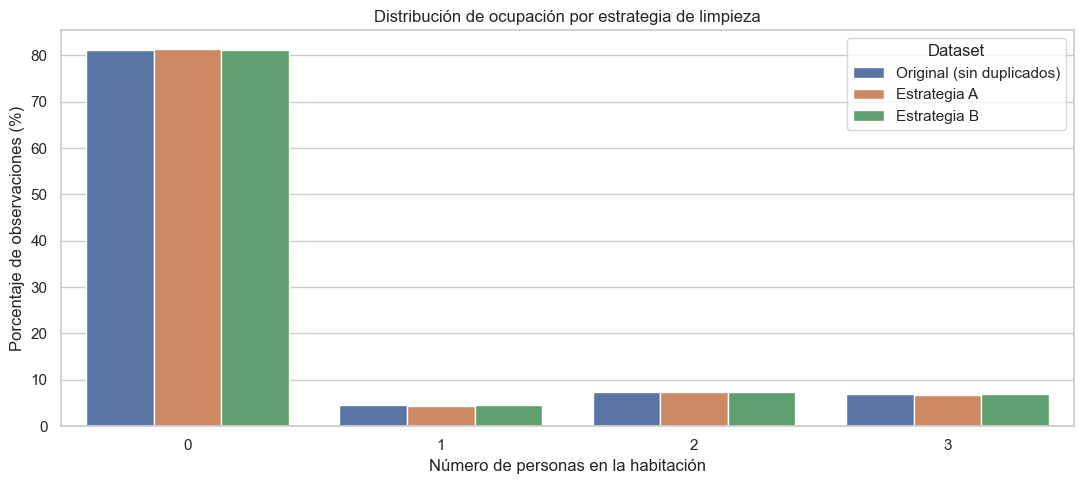

In [49]:

# Sección 8.2: Visualización comparativa de ocupación

occupation_plot = (
    occupation_pct
    .reset_index()
    .melt(
        id_vars="Ocupación",
        var_name="Dataset",
        value_name="Porcentaje"
    )
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=occupation_plot,
    x="Ocupación",
    y="Porcentaje",
    hue="Dataset"
)

plt.title(
    "Distribución de ocupación por estrategia de limpieza"
)

plt.xlabel("Número de personas en la habitación")
plt.ylabel("Porcentaje de observaciones (%)")

plt.legend(
    title="Dataset",
    loc="upper right"
)

plt.tight_layout()
plt.show()


In [50]:

# Sección 8.2: Prueba chi-cuadrado de homogeneidad

reference_counts = (
    datasets[REFERENCE][TARGET_COLUMN]
    .value_counts()
    .reindex(occupation_classes, fill_value=0)
)

chi_square_results = []

for name, df in datasets.items():

    if name == REFERENCE:
        continue

    strategy_counts = (
        df[TARGET_COLUMN]
        .value_counts()
        .reindex(occupation_classes, fill_value=0)
    )

    contingency_table = np.vstack([
        reference_counts.to_numpy(),
        strategy_counts.to_numpy()
    ])

    chi2, p_value, dof, expected = stats.chi2_contingency(
        contingency_table
    )

    chi_square_results.append({
        "Estrategia": name,
        "Chi-cuadrado": chi2,
        "Grados de libertad": dof,
        "Valor p": p_value,
        "Diferencia significativa (α=0.05)": p_value < 0.05
    })

chi_square_df = pd.DataFrame(chi_square_results)

print("Prueba chi-cuadrado de homogeneidad:")
display(
    chi_square_df.style.format({
        "Chi-cuadrado": "{:.4f}",
        "Valor p": "{:.4f}"
    })
)


Prueba chi-cuadrado de homogeneidad:


,Estrategia,Chi-cuadrado,Grados de libertad,Valor p,Diferencia significativa (α=0.05)
0,Estrategia A,0.1145,3,0.9900,False
1,Estrategia B,0.0518,3,0.9969,False



**Resultados e interpretación — Distribución de la variable objetivo**

El análisis comparativo mostró que las tres versiones del dataset conservan distribuciones de ocupación muy similares. En todos los casos predomina la clase 0, correspondiente a habitaciones sin ocupantes, con una proporción cercana al 81%.

La comparación porcentual mostró diferencias reducidas entre el dataset original y ambas estrategias. Esto sugiere que los procedimientos de limpieza no modificaron sustancialmente el desbalance de clases presente en los datos de referencia.

Como análisis complementario, se aplicó una prueba chi-cuadrado de homogeneidad. La estrategia A obtuvo un estadístico de 0.1145 y un valor p de 0.9900, mientras que la estrategia B presentó un estadístico de 0.0518 y un valor p de 0.9969.

Ambos valores p superan el nivel de significancia de 0.05. No obstante, dado que los datasets comparten observaciones y no constituyen muestras independientes, estos resultados se interpretan únicamente como indicadores descriptivos de similitud, sin atribuirles validez inferencial concluyente.

La estrategia B presentó una discrepancia ligeramente menor respecto al original y conservó un mayor número de registros. Sin embargo, la semejanza en las proporciones de ocupación no garantiza que también se hayan preservado las distribuciones de los sensores ambientales.

**Conclusión parcial:** ambas estrategias conservan de manera aproximada la distribución de la variable objetivo. Será necesario examinar las estadísticas descriptivas, los valores atípicos y las correlaciones antes de determinar cuál preserva mejor las características generales del dataset.


## 8.3 Univariate analysis

El análisis univariado permitirá comparar las características estadísticas de las variables predictoras entre el dataset original y las dos estrategias de limpieza.

Para cada variable se calcularán la media, mediana, desviación estándar, valores mínimo y máximo, asimetría y curtosis. Estas medidas permitirán identificar cambios en la tendencia central, dispersión y forma de las distribuciones.

Se analizarán los sensores de temperatura, iluminación, sonido, concentración de CO₂, pendiente de CO₂ y movimiento PIR.

Las estadísticas se calcularán por separado para cada dataset, de manera que podamos identificar el efecto de eliminar registros incompletos frente a imputar los valores faltantes.

**Consideración metodológica:** las mediciones extremas que no incumplieron las restricciones del contrato pueden influir considerablemente en las medias, desviaciones estándar, asimetrías y curtosis. Por ello, las interpretaciones también considerarán medidas robustas como la mediana.


In [51]:

# Sección 8.3: Estadísticas descriptivas univariadas

def univariate_summary(df):
    """Calcula estadísticas descriptivas de las variables predictoras."""

    features = df[FEATURE_COLUMNS]

    return pd.DataFrame({
        "Media": features.mean(),
        "Mediana": features.median(),
        "Desviación estándar": features.std(),
        "Mínimo": features.min(),
        "Máximo": features.max(),
        "Asimetría": features.skew(),
        "Curtosis": features.kurt()
    })


# Calcular estadísticas para cada dataset
univariate = pd.concat(
    {
        name: univariate_summary(df)
        for name, df in datasets.items()
    },
    axis=1
)

# Comparar las medias
print("Comparación de medias por variable:")

display(
    univariate.xs(
        "Media",
        axis=1,
        level=1
    ).round(4)
)

# Comparar las medianas
print("\nComparación de medianas por variable:")

display(
    univariate.xs(
        "Mediana",
        axis=1,
        level=1
    ).round(4)
)

# Comparar las desviaciones estándar
print("\nComparación de desviaciones estándar:")

display(
    univariate.xs(
        "Desviación estándar",
        axis=1,
        level=1
    ).round(4)
)

# Verificar que todas las variables fueron analizadas
assert len(univariate) == len(FEATURE_COLUMNS)

print(
    f"\nVariables predictoras analizadas: "
    f"{len(FEATURE_COLUMNS)}"
)


Comparación de medias por variable:


,Original (sin duplicados),Estrategia A,Estrategia B
S1_Temp,25.4540,36.2663,36.2199
S2_Temp,25.5461,36.6836,35.8947
S3_Temp,25.0566,35.2233,35.6078
S4_Temp,25.7541,33.3692,34.1333
S1_Light,25.4451,35.9012,34.4832
S2_Light,26.0163,32.4655,33.1414
S3_Light,34.2485,47.3687,44.5923
S4_Light,13.2203,19.5185,19.9212
S1_Sound,0.1682,3.1925,3.0129
S2_Sound,0.1201,2.4828,2.7713



Comparación de medianas por variable:


,Original (sin duplicados),Estrategia A,Estrategia B
S1_Temp,25.38,25.38,25.38
S2_Temp,25.38,25.38,25.38
S3_Temp,24.94,25.00,25.00
S4_Temp,25.75,25.75,25.75
S1_Light,0.00,0.00,0.00
S2_Light,0.00,0.00,0.00
S3_Light,0.00,0.00,0.00
S4_Light,0.00,0.00,0.00
S1_Sound,0.08,0.08,0.08
S2_Sound,0.05,0.05,0.05



Comparación de desviaciones estándar:


,Original (sin duplicados),Estrategia A,Estrategia B
S1_Temp,0.3514,126.5716,124.1209
S2_Temp,0.5863,127.2401,120.6831
S3_Temp,0.4273,119.8562,123.9308
S4_Temp,0.3564,98.9351,108.7938
S1_Light,51.0113,292.9882,261.4491
S2_Light,67.3042,184.7918,181.8439
S3_Light,58.4007,456.0430,404.8283
S4_Light,19.6022,101.1387,110.7407
S1_Sound,0.3167,44.0877,42.3868
S2_Sound,0.2665,39.1798,41.6216



Variables predictoras analizadas: 16


In [52]:

# Sección 8.3: Diferencias estadísticas respecto al original

reference_stats = univariate_summary(
    datasets[REFERENCE]
)

statistics_to_compare = [
    "Media",
    "Mediana",
    "Desviación estándar"
]

relative_results = {}
absolute_results = {}

for name, df in datasets.items():

    if name == REFERENCE:
        continue

    strategy_stats = univariate_summary(df)

    # Diferencias absolutas
    absolute_diff = (
        strategy_stats[statistics_to_compare]
        - reference_stats[statistics_to_compare]
    )

    # Diferencias relativas únicamente si la referencia no es cero
    relative_diff = pd.DataFrame(
        np.nan,
        index=reference_stats.index,
        columns=statistics_to_compare
    )

    for statistic in statistics_to_compare:

        reference_values = reference_stats[statistic]

        valid_reference = (
            reference_values.notna()
            & ~np.isclose(reference_values, 0)
        )

        relative_diff.loc[
            valid_reference, statistic
        ] = (
            absolute_diff.loc[valid_reference, statistic]
            / reference_values.loc[valid_reference].abs()
            * 100
        )

    relative_results[name] = relative_diff
    absolute_results[name] = absolute_diff


# Consolidar resultados
relative_comparison = pd.concat(
    relative_results,
    axis=1
)

absolute_comparison = pd.concat(
    absolute_results,
    axis=1
)

print("Diferencias relativas respecto al original (%):")
print("NaN indica referencia igual o cercana a cero.")

display(relative_comparison.round(2))

print("\nDiferencias absolutas respecto al original:")
display(absolute_comparison.round(4))


Diferencias relativas respecto al original (%):
NaN indica referencia igual o cercana a cero.


Estrategia A                             Estrategia B                            
                    Media Mediana Desviación estándar        Media Mediana Desviación estándar
S1_Temp             42.48    0.00            35924.31        42.30    0.00            35226.79
S2_Temp             43.60    0.00            21601.27        40.51    0.00            20482.95
S3_Temp             40.57    0.24            27950.82        42.11    0.24            28904.43
S4_Temp             29.57    0.00            27656.90        32.54    0.00            30422.85
S1_Light            41.09     NaN              474.36        35.52     NaN              412.53
S2_Light            24.79     NaN              174.56        27.39     NaN              170.18
S3_Light            38.31     NaN              680.89        30.20     NaN              593.19
S4_Light            47.64     NaN              415.96        50.69     NaN              464.94
S1_Sound          1798.28    0.00            13820.58      1691.49    0.00            13283.52
S2_Sound          1967.88    0.00            14601.48      2208.12    0.00            15517.71
S3_Sound          1622.57    0.00             9800.49      1608.78    0.00             9843.55
S4_Sound          2493.65    0.00            35125.91      2723.87   12.50            37329.51
S5_CO2              29.51    0.00             1848.06        29.63    0.00             1685.53
S5_CO2_Slope     53898.05     NaN             3618.42     56105.40     NaN             3676.93
S6_PIR               0.06     NaN                0.03        -0.89     NaN               -0.40
S7_PIR               1.40     NaN                0.64        -1.05     NaN               -0.48


Diferencias absolutas respecto al original:


Estrategia A                             Estrategia B                            
                    Media Mediana Desviación estándar        Media Mediana Desviación estándar
S1_Temp           10.8123    0.00            126.2203      10.7658    0.00            123.7695
S2_Temp           11.1375    0.00            126.6538      10.3486    0.00            120.0968
S3_Temp           10.1667    0.06            119.4290      10.5512    0.06            123.5036
S4_Temp            7.6150    0.00             98.5786       8.3791    0.00            108.4374
S1_Light          10.4562    0.00            241.9769       9.0382    0.00            210.4378
S2_Light           6.4492    0.00            117.4877       7.1251    0.00            114.5397
S3_Light          13.1202    0.00            397.6422      10.3438    0.00            346.4276
S4_Light           6.2982    0.00             81.5365       6.7009    0.00             91.1384
S1_Sound           3.0243    0.00             43.7710       2.8447    0.00             42.0701
S2_Sound           2.3628    0.00             38.9133       2.6512    0.00             41.3551
S3_Sound           2.5656    0.00             40.5384       2.5438    0.00             40.7165
S4_Sound           2.5894    0.00             42.3909       2.8285    0.01             45.0503
S5_CO2           136.0100    0.00           3695.4743     136.5744    0.00           3370.4623
S5_CO2_Slope       2.6033    0.00             42.1542       2.7099    0.00             42.8358
S6_PIR             0.0001    0.00              0.0001      -0.0008    0.00             -0.0012
S7_PIR             0.0011    0.00              0.0017      -0.0008    0.00             -0.0013


**Resultados e interpretación — Análisis univariado**

La comparación de estadísticas descriptivas mostró diferencias importantes entre las distribuciones originales y los datasets obtenidos mediante ambas estrategias de limpieza.

Las medias de diversas variables continuas aumentaron considerablemente. Por ejemplo, `S1_Temp` presentó incrementos del 42.48% en la estrategia A y del 42.30% en B. En `S1_Sound`, las diferencias superaron el 1,600% en ambas estrategias.

También se observaron incrementos pronunciados en las desviaciones estándar. Estos resultados indican que las mediciones extremas presentes en el dataset perturbado continúan afectando la dispersión de los datos después de aplicar las transformaciones de limpieza.

En contraste, las medianas permanecieron relativamente estables. En variables como `S1_Temp`, `S2_Temp` y `S5_CO2`, los valores fueron prácticamente idénticos entre el original y ambas estrategias.

Esta diferencia entre las medias y las medianas evidencia la sensibilidad de las estadísticas tradicionales a observaciones extremas y la utilidad de incorporar medidas robustas durante el análisis.

Las variables binarias `S6_PIR` y `S7_PIR` conservaron medias y desviaciones estándar muy próximas a las originales, lo que sugiere una mayor estabilidad de sus distribuciones.

**Limitación metodológica:** las restricciones del contrato no establecen límites superiores para determinadas variables continuas. Por ello, algunos valores alterados permanecieron en ambos datasets, aun cuando todas las validaciones automáticas fueron superadas.

La estrategia B conservó un mayor número de registros, pero ninguna de las dos estrategias eliminó completamente el efecto de las perturbaciones extremas.

**Conclusión parcial:** las estadísticas univariadas no permiten identificar todavía una estrategia claramente superior. Será necesario complementar la evaluación mediante distribuciones gráficas, valores atípicos y correlaciones, considerando tanto la conservación de observaciones como las desviaciones respecto al dataset original.


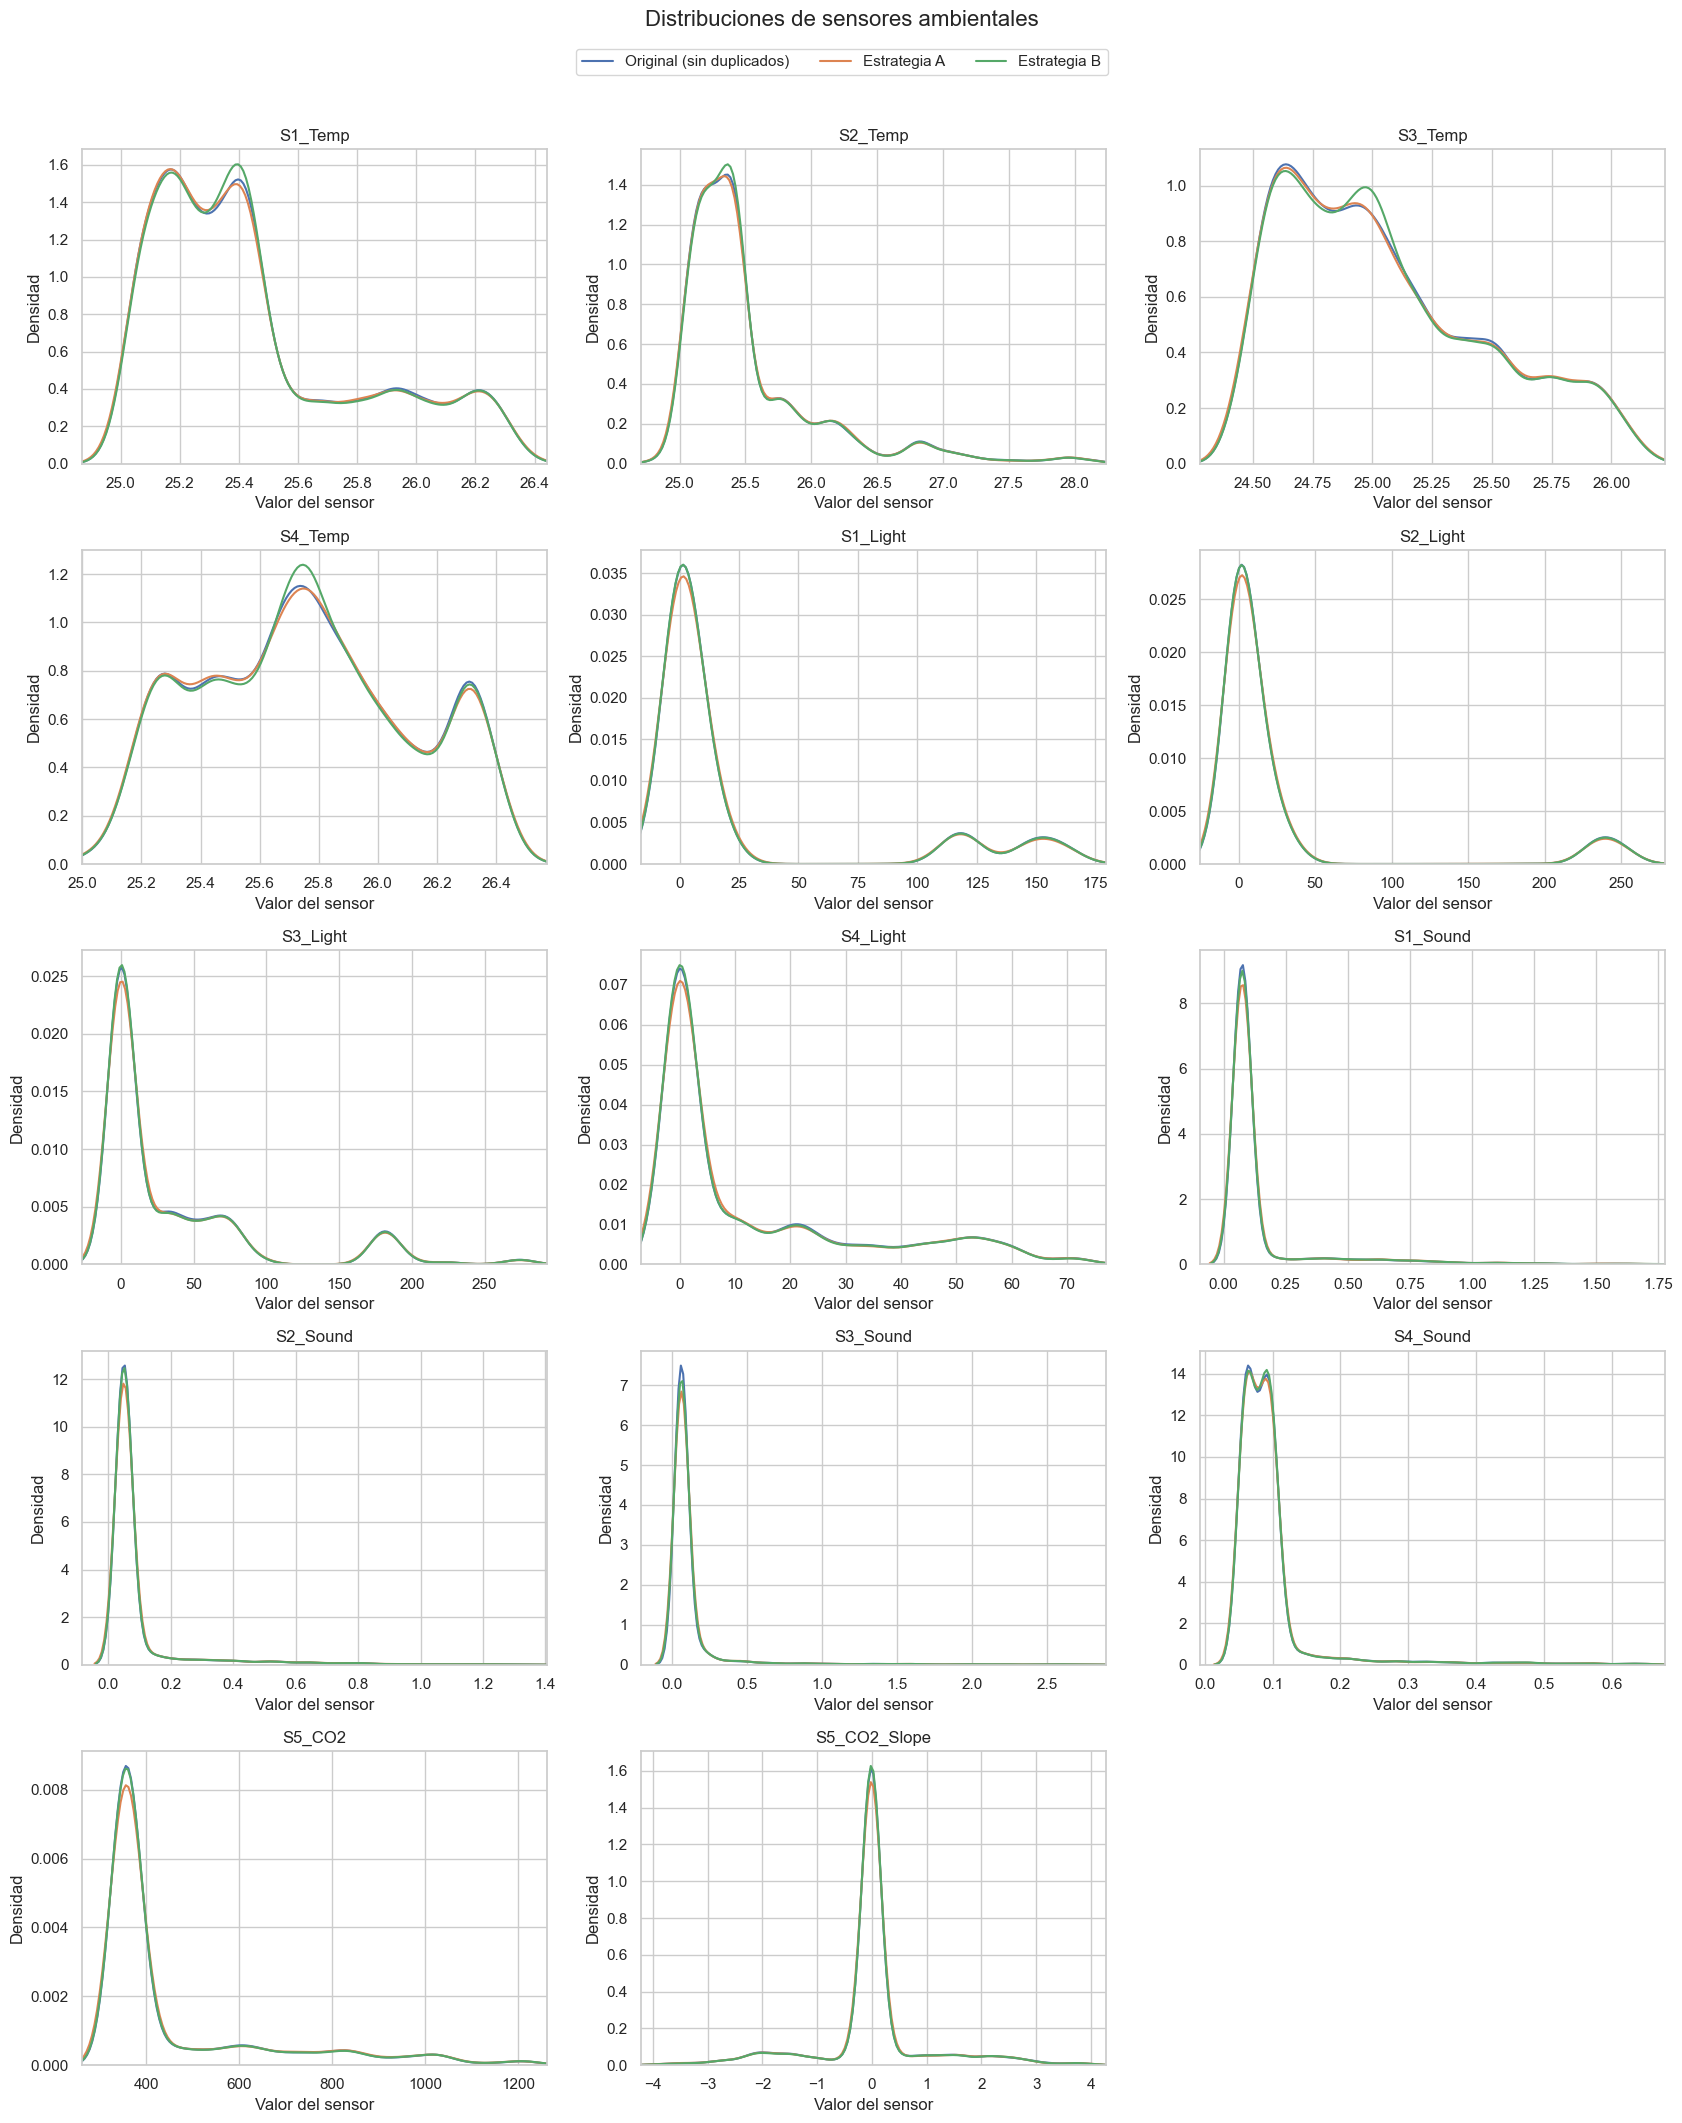

In [53]:

# Sección 8.3: Distribuciones comparativas de sensores continuos
# Los límites se utilizan únicamente para visualización.

continuous_columns = (
    TEMPERATURE_COLUMNS
    + LIGHT_COLUMNS
    + SOUND_COLUMNS
    + CO2_COLUMNS
)

# Comparación en formato largo
long_df = long_format(continuous_columns)

# Límites de visualización del dataset de referencia
reference_df = datasets[REFERENCE]

plot_limits = {}

for column in continuous_columns:
    q01 = reference_df[column].quantile(0.01)
    q99 = reference_df[column].quantile(0.99)

    margin = (q99 - q01) * 0.10

    if np.isclose(margin, 0):
        margin = max(abs(q99) * 0.10, 0.01)

    plot_limits[column] = (
        q01 - margin,
        q99 + margin
    )

# Crear distribución comparativa
fig, axes = plt.subplots(
    5,
    3,
    figsize=(17, 21)
)

axes = axes.flatten()

for index, column in enumerate(continuous_columns):

    ax = axes[index]

    lower, upper = plot_limits[column]

    for name, df in datasets.items():

        values = df[column].dropna()

        # Filtrar únicamente los valores mostrados
        visible_values = values[
            values.between(lower, upper)
        ]

        if (
            len(visible_values) > 1
            and visible_values.nunique() > 1
        ):
            sns.kdeplot(
                x=visible_values,
                ax=ax,
                label=name,
                warn_singular=False
            )

    ax.set_title(column)
    ax.set_xlabel("Valor del sensor")
    ax.set_ylabel("Densidad")
    ax.set_xlim(lower, upper)

# Ocultar paneles sin variable
for index in range(len(continuous_columns), len(axes)):
    axes[index].set_visible(False)

# Leyenda general
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.995)
)

fig.suptitle(
    "Distribuciones de sensores ambientales",
    fontsize=16,
    y=1.01
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


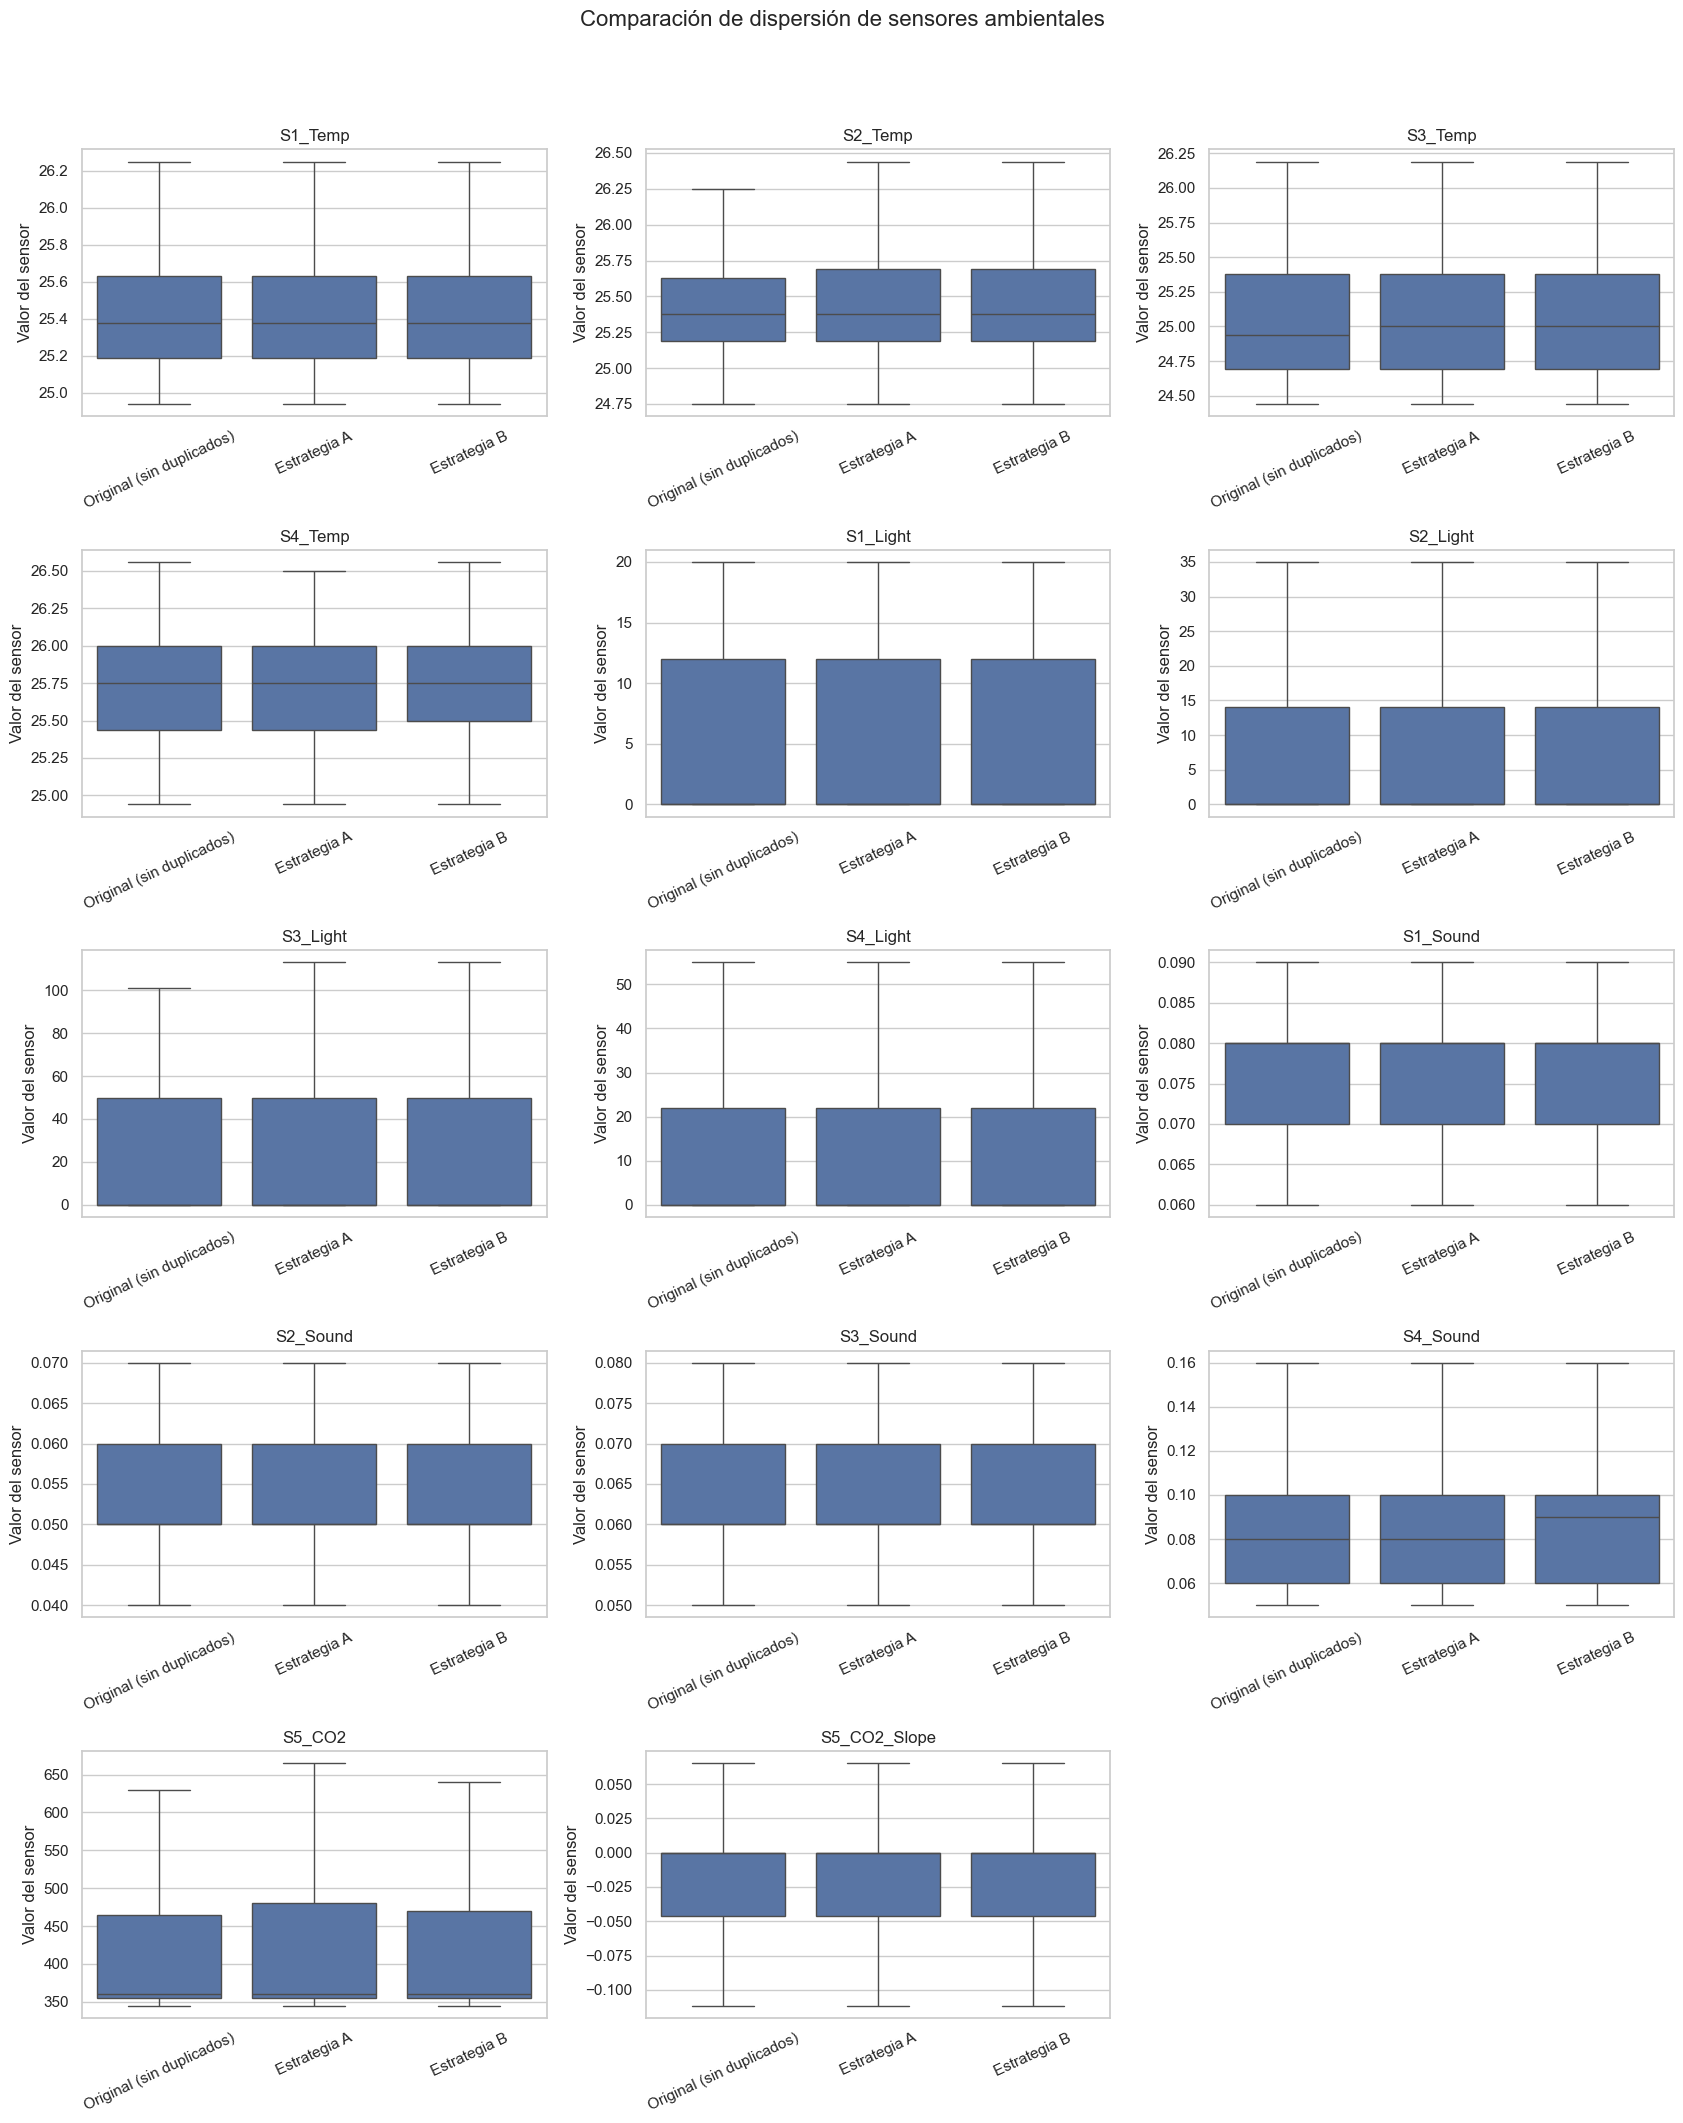

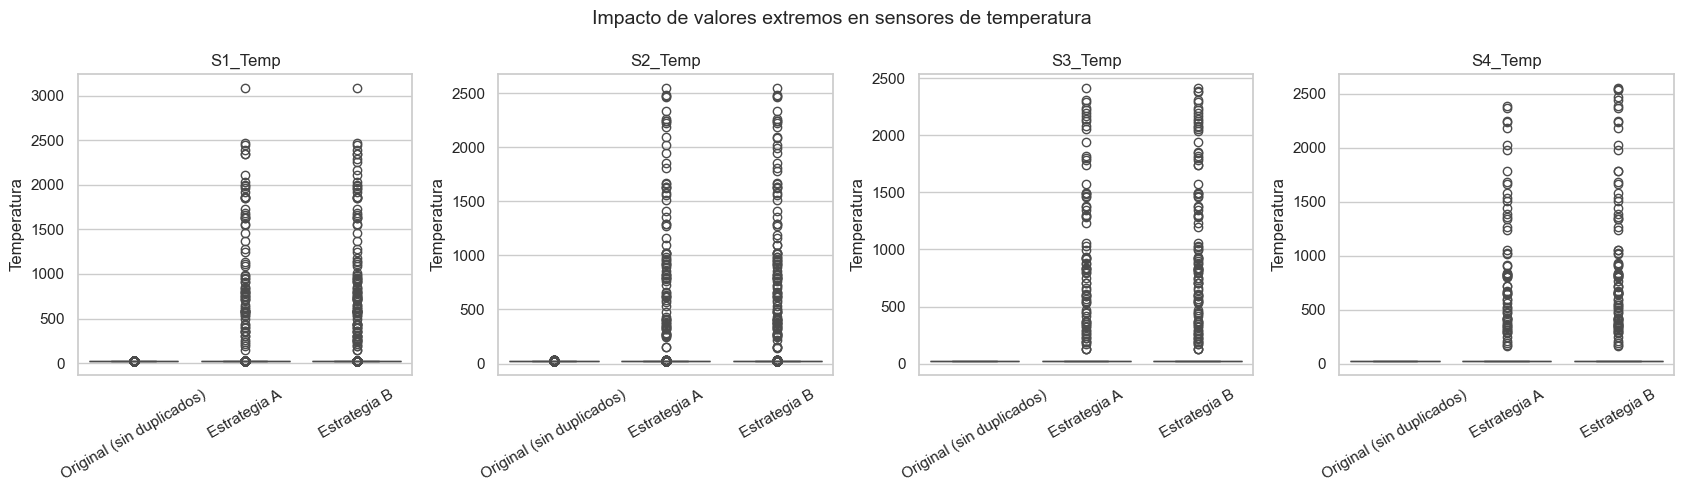

In [54]:

# Sección 8.3: Diagramas de caja comparativos
# Sensores continuos de Room Occupancy Estimation

continuous_columns = (
    TEMPERATURE_COLUMNS
    + LIGHT_COLUMNS
    + SOUND_COLUMNS
    + CO2_COLUMNS
)

# Datos en formato largo
boxplot_df = long_format(continuous_columns)

# Diagramas de caja con visualización central
fig, axes = plt.subplots(
    5,
    3,
    figsize=(17, 21)
)

axes = axes.flatten()

for index, column in enumerate(continuous_columns):

    ax = axes[index]

    sns.boxplot(
        data=boxplot_df,
        x="Dataset",
        y=column,
        ax=ax,
        showfliers=False
    )

    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Valor del sensor")
    ax.tick_params(axis="x", rotation=25)

for index in range(len(continuous_columns), len(axes)):
    axes[index].set_visible(False)

fig.suptitle(
    "Comparación de dispersión de sensores ambientales",
    fontsize=16,
    y=1.01
)

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


# Visualización complementaria de valores extremos
fig, axes = plt.subplots(
    1,
    4,
    figsize=(17, 5)
)

for ax, column in zip(axes, TEMPERATURE_COLUMNS):

    sns.boxplot(
        data=boxplot_df,
        x="Dataset",
        y=column,
        ax=ax,
        showfliers=True
    )

    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Temperatura")
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(
    "Impacto de valores extremos en sensores de temperatura",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Resultados e interpretación — Distribuciones y valores extremos**

Las curvas de densidad y los diagramas de caja permitieron comparar las distribuciones de los sensores ambientales entre el dataset original y las dos estrategias de limpieza.

En las regiones centrales se observó una superposición considerable entre las distribuciones. Las medianas y los rangos intercuartílicos permanecieron relativamente estables, especialmente en los sensores de temperatura, iluminación y sonido.

No obstante, esta similitud debe interpretarse considerando que las curvas de densidad utilizaron intervalos de visualización restringidos y que los primeros diagramas de caja omitieron la representación individual de valores atípicos.

Los diagramas complementarios de temperatura revelaron diferencias importantes. Mientras que el dataset original presenta mediciones concentradas alrededor de 25 °C, las estrategias A y B conservan observaciones superiores a 2,000 °C y, en algunos casos, superiores a 3,000 °C.

Estas mediciones explican parte de las diferencias observadas anteriormente en las medias y desviaciones estándar, aunque las medianas permanezcan próximas a los valores originales.

La estrategia B conserva una proporción mayor de registros mediante imputación, pero este procedimiento no corrige las alteraciones extremas que siguen representadas como valores numéricos válidos.

**Limitación:** la detección estadística de valores atípicos no equivale automáticamente a la identificación de errores. Sin embargo, las temperaturas observadas muestran la necesidad de contar con límites operativos documentados para validar adecuadamente las mediciones continuas.

**Conclusión parcial:** ambas estrategias conservan aproximadamente la estructura central de las distribuciones, pero mantienen alteraciones extremas capaces de afectar las medidas de dispersión y las relaciones estadísticas. Por ello, todavía no existe evidencia suficiente para seleccionar una estrategia únicamente a partir de los gráficos.


## 8.4 Potential outliers using the IQR rule

Se utilizará el rango intercuartílico (IQR) para identificar observaciones potencialmente atípicas en las variables continuas del dataset Room Occupancy Estimation.

Para cada sensor se calcularán el primer cuartil (Q1), el tercer cuartil (Q3) y el rango intercuartílico (IQR = Q3 - Q1). Se considerarán potencialmente atípicos los valores inferiores a Q1 - 1.5 × IQR o superiores a Q3 + 1.5 × IQR.

El procedimiento se aplicará por separado al dataset original sin duplicados y a las estrategias A y B, permitiendo comparar el porcentaje de observaciones señaladas en cada caso.

Los sensores PIR se excluirán de este análisis porque representan variables binarias, cuyo dominio ya fue validado mediante reglas específicas.

**Consideración metodológica:** los límites IQR describen valores estadísticamente inusuales, pero no permiten determinar por sí solos si una medición es incorrecta. Además, los límites calculados por separado pueden cambiar entre datasets debido a la eliminación de registros o la imputación.

Por tanto, los resultados se interpretarán como indicadores de posibles anomalías y no como criterios automáticos de eliminación.


In [55]:

# Sección 8.4: Comparación de valores atípicos mediante IQR


def iqr_outlier_pct(df):
    """Calcula el porcentaje de valores atípicos por sensor."""

    results = {}

    for column in continuous_columns:

        values = df[column].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)

        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outliers = (
            (values < lower_bound)
            | (values > upper_bound)
        )

        results[column] = (
            outliers.mean() * 100
            if len(values) > 0
            else np.nan
        )

    return pd.Series(results)


# Calcular porcentajes para los tres datasets
iqr_comparison = pd.DataFrame({
    name: iqr_outlier_pct(df)
    for name, df in datasets.items()
})

print("Porcentaje de valores potencialmente atípicos por variable:")

display(
    iqr_comparison.style.format("{:.2f}%")
)

# Diferencias respecto al original en puntos porcentuales
iqr_difference = iqr_comparison.drop(
    columns=REFERENCE
).sub(
    iqr_comparison[REFERENCE],
    axis=0
)

print("\nDiferencias respecto al original (puntos porcentuales):")

display(
    iqr_difference.style.format("{:+.2f} pp")
)

# Verificación de integridad
assert len(iqr_comparison) == len(continuous_columns)

print(
    f"\nSensores continuos analizados: "
    f"{len(continuous_columns)}"
)


Porcentaje de valores potencialmente atípicos por variable:


,Original (sin duplicados),Estrategia A,Estrategia B
S1_Temp,1.60%,2.62%,2.67%
S2_Temp,9.36%,8.25%,8.20%
S3_Temp,0.00%,1.07%,1.06%
S4_Temp,0.00%,0.88%,0.91%
S1_Light,16.94%,17.33%,17.37%
S2_Light,10.04%,10.46%,10.57%
S3_Light,9.38%,9.84%,9.66%
S4_Light,5.36%,6.05%,5.97%
S1_Sound,17.49%,18.25%,18.32%
S2_Sound,16.81%,17.49%,17.52%



Diferencias respecto al original (puntos porcentuales):


,Estrategia A,Estrategia B
S1_Temp,+1.02 pp,+1.07 pp
S2_Temp,-1.11 pp,-1.16 pp
S3_Temp,+1.07 pp,+1.06 pp
S4_Temp,+0.88 pp,+0.91 pp
S1_Light,+0.39 pp,+0.43 pp
S2_Light,+0.42 pp,+0.53 pp
S3_Light,+0.46 pp,+0.28 pp
S4_Light,+0.69 pp,+0.61 pp
S1_Sound,+0.75 pp,+0.82 pp
S2_Sound,+0.68 pp,+0.71 pp



Sensores continuos analizados: 14



**Resultados e interpretación — Valores atípicos mediante IQR**

El análisis mediante el rango intercuartílico permitió comparar la proporción de observaciones potencialmente atípicas en las 14 variables continuas del dataset original y de ambas estrategias de limpieza.

En términos generales, los porcentajes de valores señalados mediante IQR presentan diferencias relativamente pequeñas entre los tres conjuntos de datos. Por ejemplo, `S1_Temp` registró 1.60% de valores atípicos en el original, frente a 2.62% en la estrategia A y 2.67% en B.

En `S5_CO2`, los porcentajes fueron de 16.36%, 15.79% y 16.32%, respectivamente. La estrategia B presentó una proporción ligeramente más próxima al dataset de referencia para esta variable.

Por otra parte, `S5_CO2_Slope` mostró porcentajes elevados en los tres datasets, cercanos al 40%. Este comportamiento evidencia que el criterio IQR puede señalar una proporción considerable de observaciones cuando la distribución presenta una concentración importante alrededor de determinados valores.

Aunque las proporciones de valores atípicos son relativamente similares, este resultado no demuestra que las alteraciones numéricas hayan sido eliminadas. El análisis univariado anterior identificó incrementos pronunciados en medias y desviaciones estándar, así como temperaturas superiores a 2,000 °C que permanecen en ambas estrategias.

**Limitación metodológica:** los límites IQR se calcularon por separado para cada dataset, por lo que las diferencias porcentuales también pueden reflejar cambios en los cuartiles ocasionados por la eliminación de registros o la imputación. Asimismo, el criterio estadístico no permite distinguir automáticamente entre mediciones legítimas y errores.

**Conclusión parcial:** ambas estrategias mantienen proporciones de valores potencialmente atípicos relativamente próximas a las originales. Sin embargo, ninguna ha corregido completamente las perturbaciones extremas detectadas durante la auditoría. Por ello, esta comparación debe interpretarse junto con las estadísticas descriptivas, las distribuciones gráficas y el análisis posterior de correlaciones.


## 8.5 Bivariate analysis: predictors vs. wine quality

El análisis bivariado permitirá examinar la relación entre las variables predictoras y `Room_Occupancy_Count`, que representa el número de personas presentes en la habitación.

Para cada uno de los 16 sensores se calculará la media correspondiente a las cuatro clases de ocupación: 0, 1, 2 y 3 personas.

Los resultados se compararán entre el dataset original sin duplicados y las estrategias A y B, con el propósito de identificar posibles modificaciones en los patrones de las mediciones ambientales asociados con la ocupación.

Se utilizarán gráficas de líneas para visualizar las diferencias entre clases y estrategias. Este enfoque permitirá observar cambios en las medias, aunque no establece relaciones causales entre los sensores y la cantidad de personas.

**Consideración metodológica:** las medias de las variables continuas pueden estar afectadas por las perturbaciones extremas identificadas anteriormente. Por tanto, cualquier diferencia considerable deberá interpretarse considerando los resultados del análisis univariado y las limitaciones del contrato de datos.


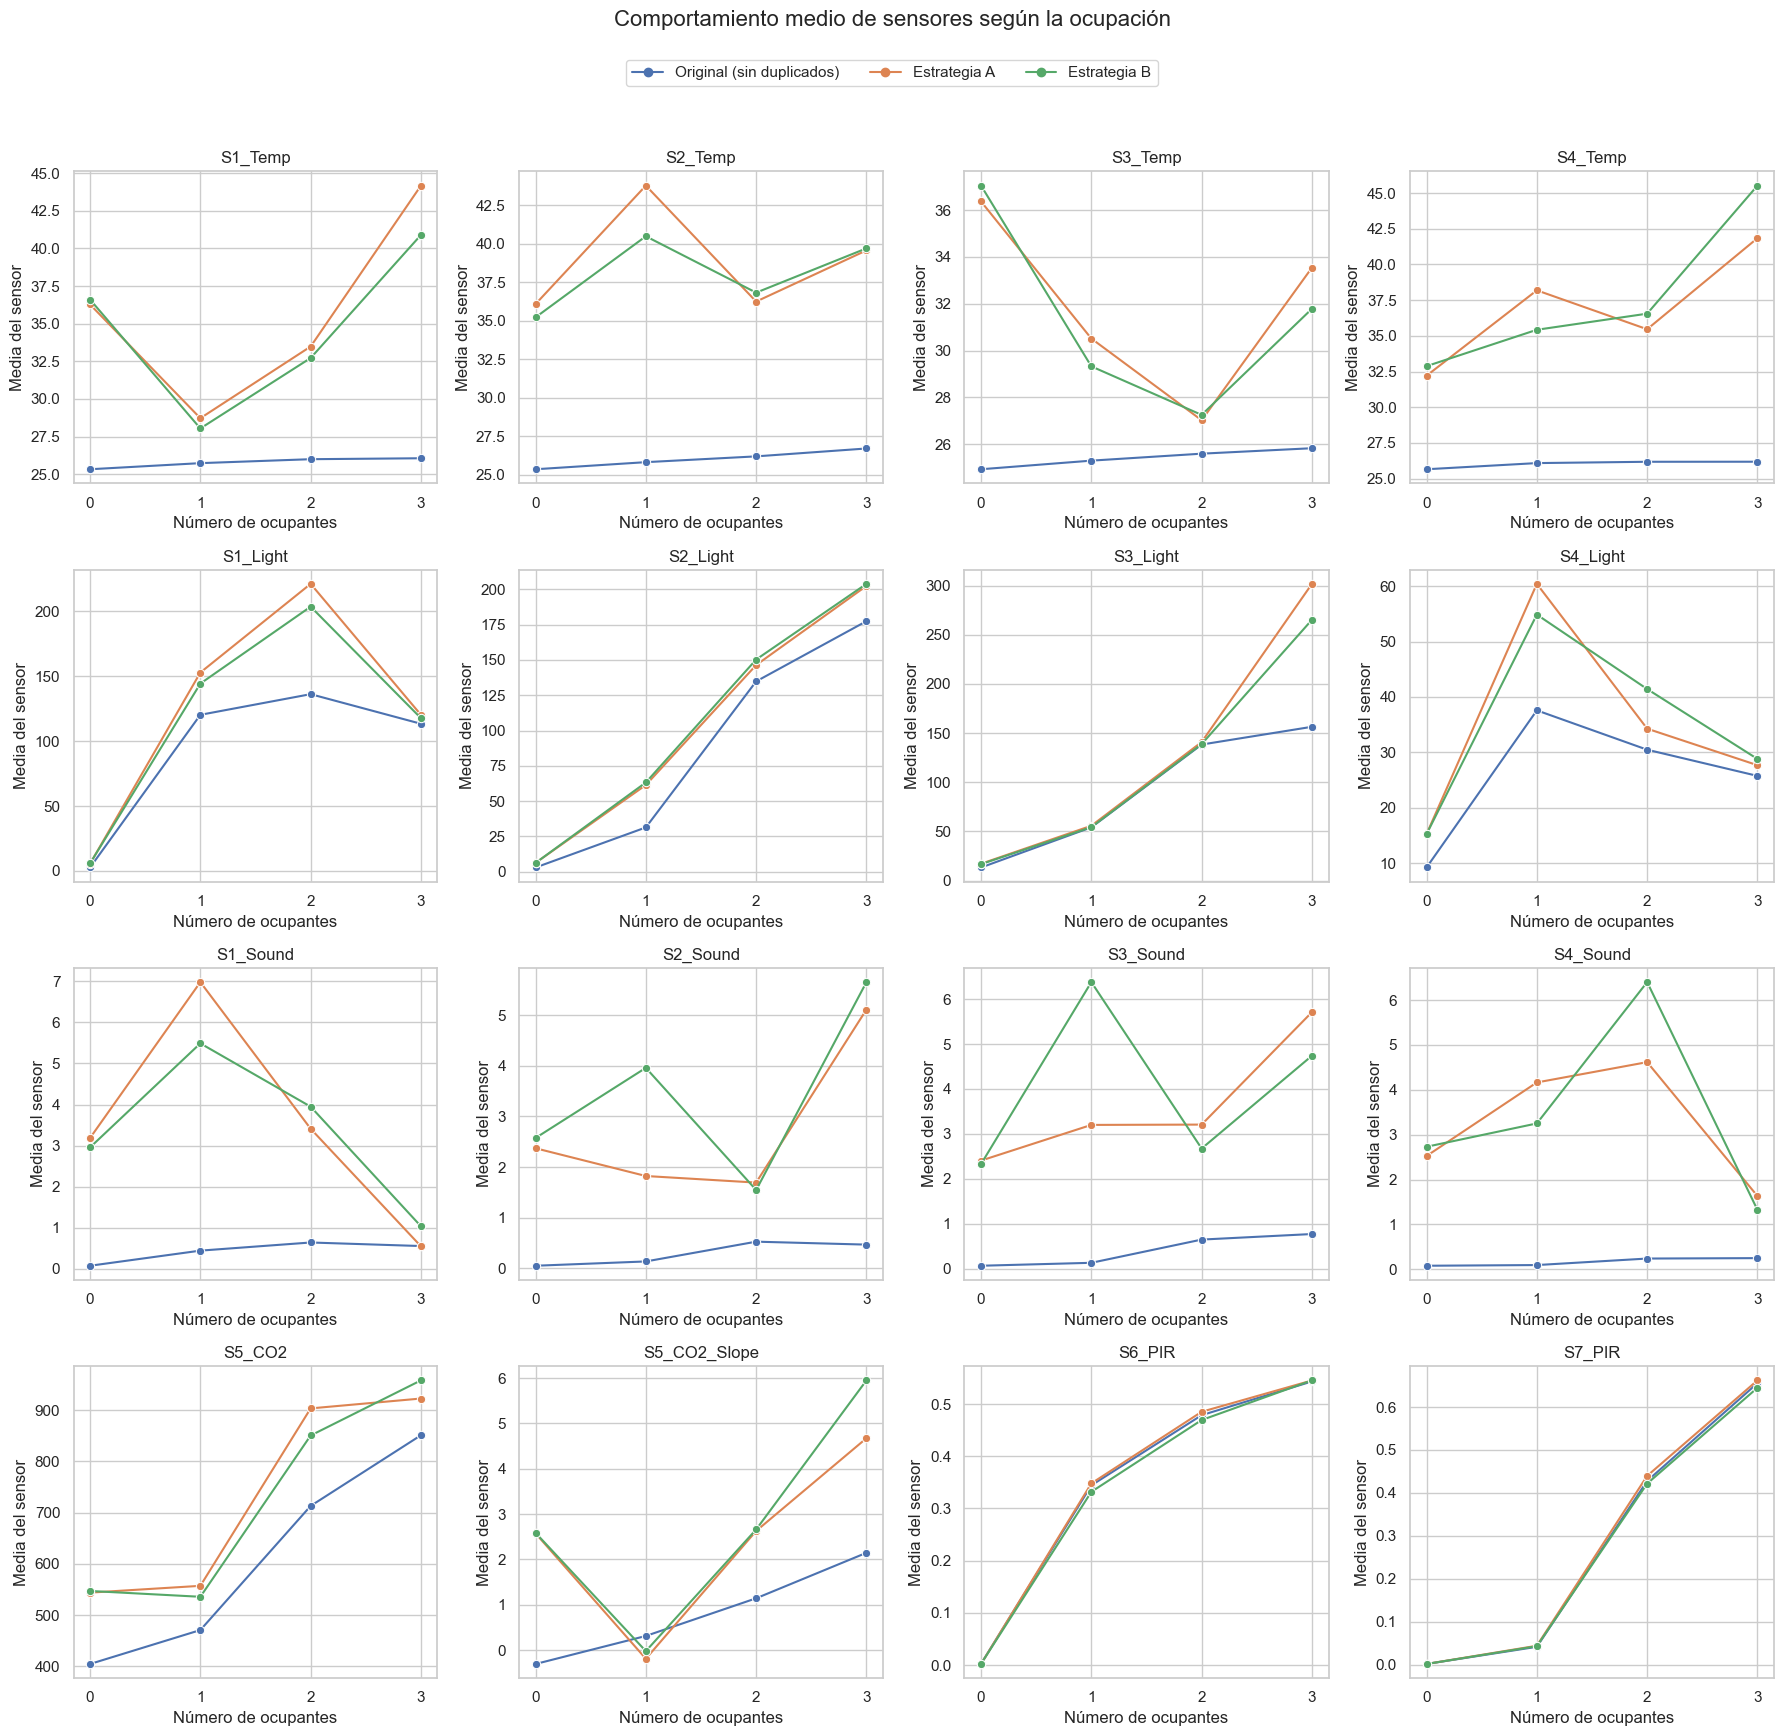

In [59]:

# Sección 8.5: Análisis bivariado
# Medias de sensores según el número de ocupantes

# Calcular medias por clase de ocupación y dataset
means_by_occupancy = pd.concat(
    [
        df.groupby(TARGET_COLUMN)[FEATURE_COLUMNS]
        .mean()
        .reindex(occupation_classes)
        .assign(Dataset=name)
        .reset_index()
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Validar las clases consideradas
assert set(means_by_occupancy[TARGET_COLUMN]) == set(
    occupation_classes
)

# Crear gráficas comparativas
fig, axes = plt.subplots(
    4,
    4,
    figsize=(18, 17)
)

axes = axes.flatten()

for index, column in enumerate(FEATURE_COLUMNS):

    ax = axes[index]

    sns.lineplot(
        data=means_by_occupancy,
        x=TARGET_COLUMN,
        y=column,
        hue="Dataset",
        marker="o",
        ax=ax,
        legend=False
    )

    ax.set_title(column)
    ax.set_xlabel("Número de ocupantes")
    ax.set_ylabel("Media del sensor")
    ax.set_xticks(occupation_classes)


# Leyenda general con colores correspondientes a cada estrategia
colors = sns.color_palette(n_colors=len(datasets))

handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        linestyle="-",
        color=colors[index],
        label=name
    )
    for index, name in enumerate(datasets)
]


fig.legend(
    handles=handles,
    labels=list(datasets.keys()),
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.995)
)

fig.suptitle(
    "Comportamiento medio de sensores según la ocupación",
    fontsize=16,
    y=1.02
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()



**Resultados e interpretación — Análisis bivariado**

El análisis bivariado permitió comparar las medias de los 16 sensores ambientales según las cuatro categorías de ocupación, utilizando el dataset original y las dos estrategias de limpieza.

Los sensores de temperatura mostraron diferencias considerables entre el original y los datasets procesados. Mientras que las medias originales permanecieron próximas a los valores habituales de medición, las estrategias A y B presentaron incrementos y fluctuaciones pronunciadas, asociados con la presencia de valores extremos que no fueron identificados por las restricciones actuales.

Los sensores de iluminación conservaron parcialmente sus patrones de variación entre niveles de ocupación, aunque algunas medias se alejaron del original. De manera similar, los sensores de sonido mostraron diferencias importantes, lo que dificulta interpretar sus patrones como relaciones estables entre las mediciones y la ocupación.

En el caso de la concentración de CO₂, se conservó una tendencia generalmente creciente conforme aumentó el número de ocupantes. Sin embargo, las medias de ambas estrategias resultaron superiores a las del dataset de referencia, lo que evidencia que conservar una tendencia no implica preservar su magnitud.

Los sensores PIR presentaron el comportamiento más estable. Sus medias por categoría de ocupación fueron similares entre los tres datasets, lo que indica que las proporciones de activación de estos sensores se mantuvieron relativamente constantes.

**Limitación metodológica:** las gráficas representan medias condicionadas por el nivel de ocupación y no constituyen pruebas de correlación o causalidad. Además, las alteraciones extremas de los sensores continuos pueden modificar considerablemente las medias, incluso cuando la tendencia general parece conservarse.

**Conclusión parcial:** ambas estrategias mantienen algunas relaciones descriptivas entre sensores y ocupación, especialmente en las variables binarias. No obstante, las diferencias observadas en las variables continuas impiden afirmar que cualquiera de las estrategias haya preservado completamente las relaciones presentes en el dataset original. Será necesario complementar esta evaluación mediante un análisis de correlaciones.


## 8.6 Correlation analysis (Pearson and Spearman)

Se analizarán las relaciones estadísticas entre los 16 sensores ambientales y la variable objetivo `Room_Occupancy_Count`, comparando el dataset original sin duplicados con las estrategias A y B.

Se utilizarán dos coeficientes de correlación:

**Pearson:** permite evaluar relaciones lineales entre variables numéricas. Es sensible a los valores extremos, por lo que resulta útil para identificar posibles alteraciones en las relaciones estadísticas ocasionadas por las perturbaciones del dataset.

**Spearman:** evalúa asociaciones monótonas a partir de rangos. Su utilización complementará el análisis de Pearson, especialmente porque las variables continuas presentan asimetrías y valores extremos.

Para cada método se generarán tres matrices: la correlación del dataset original y las diferencias obtenidas al restar dicha matriz a las correlaciones de las estrategias A y B.

Las diferencias permitirán identificar qué relaciones se conservaron aproximadamente y cuáles presentaron mayores modificaciones después de la limpieza.

**Consideración metodológica:** las correlaciones no establecen causalidad. Además, `Room_Occupancy_Count` representa una variable discreta ordinal de conteo, por lo que sus correlaciones deberán interpretarse como asociaciones estadísticas y no como relaciones causales o necesariamente lineales.


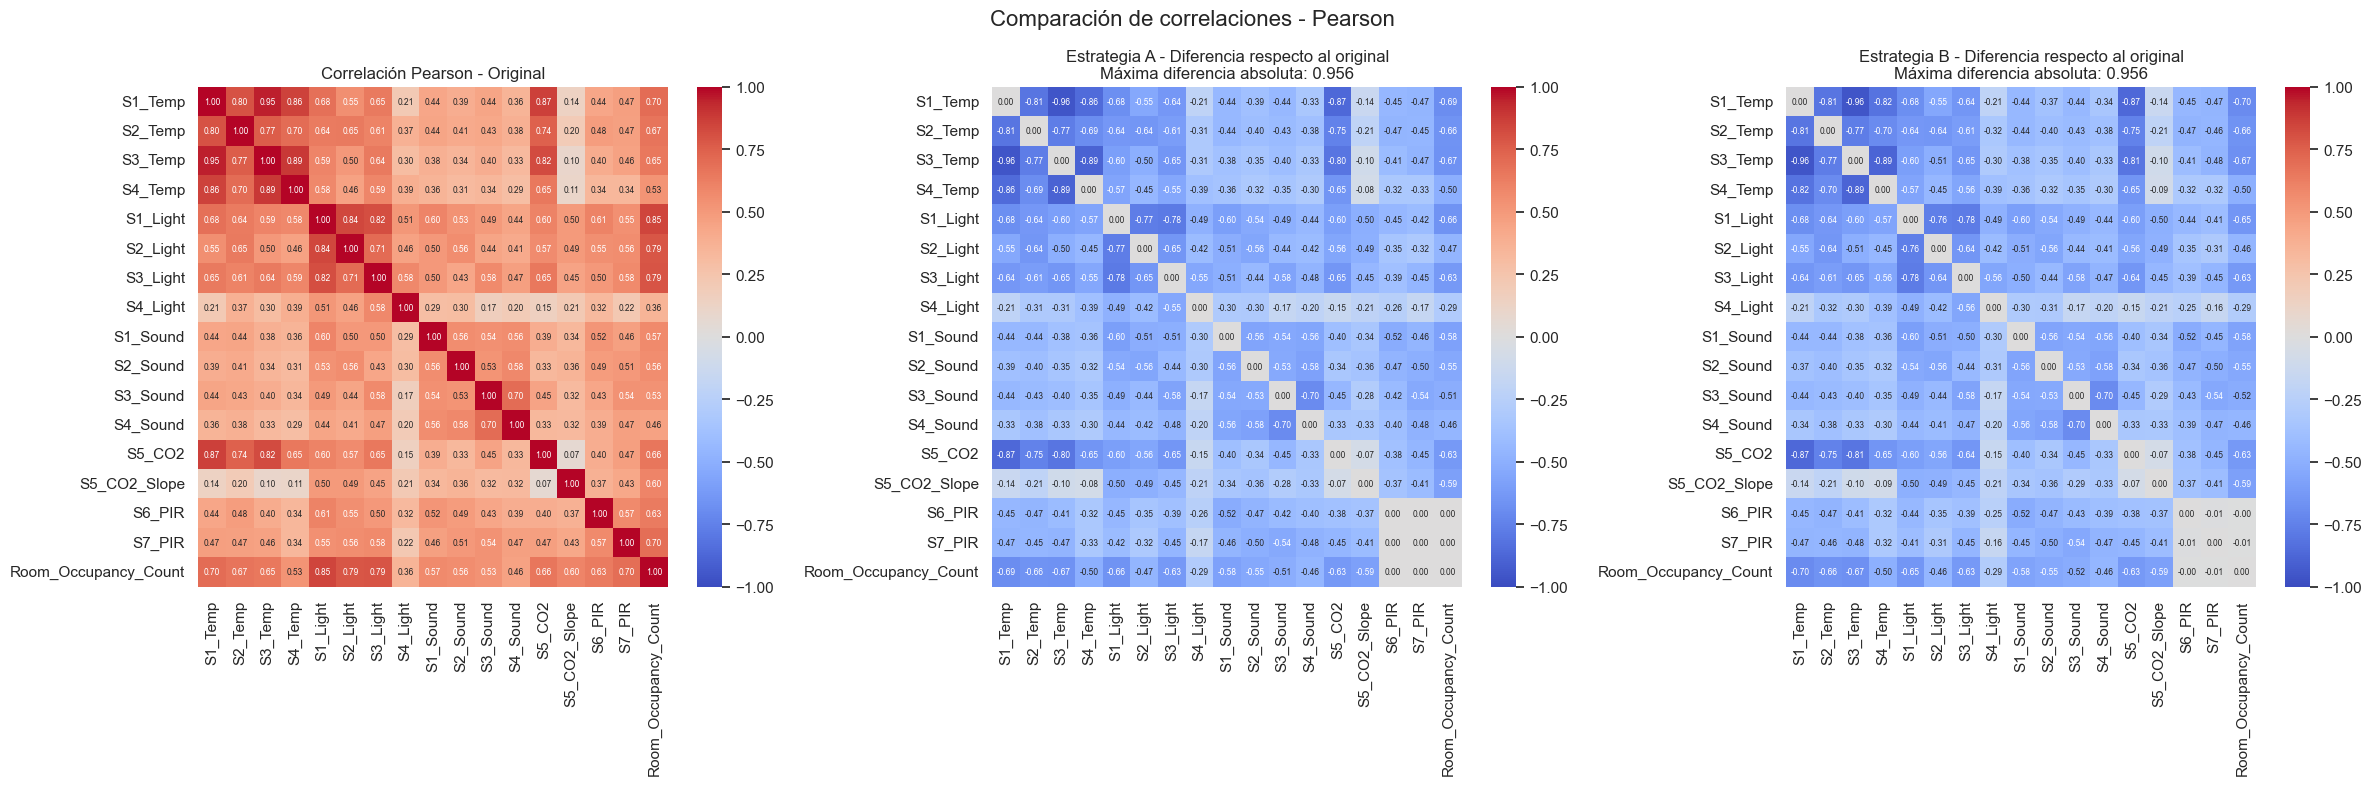


Resumen de diferencias - Pearson:


,Diferencia máxima,Diferencia media
Estrategia A,0.9561,0.4361
Estrategia B,0.9562,0.4354


In [60]:

# Sección 8.6: Análisis comparativo de correlaciones

# Variables predictoras y variable objetivo
corr_cols = FEATURE_COLUMNS + [TARGET_COLUMN]


def corr_diff_heatmaps(method):
    """Compara las correlaciones contra el dataset original."""

    # Correlación de referencia
    reference_corr = datasets[REFERENCE][corr_cols].corr(
        method=method
    )

    # Matrices de correlación de ambas estrategias
    strategy_correlations = {
        name: df[corr_cols].corr(method=method)
        for name, df in datasets.items()
        if name != REFERENCE
    }

    # Construir las diferencias respecto al original
    correlation_differences = {
        name: correlation - reference_corr
        for name, correlation in strategy_correlations.items()
    }

    # Crear tres mapas de calor
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(24, 8)
    )

    # Matriz de referencia
    sns.heatmap(
        reference_corr,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        ax=axes[0],
        annot=True,
        fmt=".2f",
        annot_kws={"size": 6}
    )

    axes[0].set_title(
        f"Correlación {method.capitalize()} - Original"
    )

    # Matrices de diferencias
    for ax, (name, difference) in zip(
        axes[1:],
        correlation_differences.items()
    ):

        max_difference = difference.abs().max().max()

        sns.heatmap(
            difference,
            cmap="coolwarm",
            center=0,
            vmin=-1,
            vmax=1,
            ax=ax,
            annot=True,
            fmt=".2f",
            annot_kws={"size": 6}
        )

        ax.set_title(
            f"{name} - Diferencia respecto al original\n"
            f"Máxima diferencia absoluta: {max_difference:.3f}"
        )

    fig.suptitle(
        f"Comparación de correlaciones - {method.capitalize()}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

    # Resumen de diferencias absolutas
    summary = pd.DataFrame({
        name: {
            "Diferencia máxima": difference.abs().max().max(),
            "Diferencia media": difference.abs().to_numpy().mean()
        }
        for name, difference in correlation_differences.items()
    }).T

    print(f"\nResumen de diferencias - {method.capitalize()}:")

    display(summary.round(4))

    return correlation_differences


# Ejecutar correlación de Pearson
pearson_differences = corr_diff_heatmaps("pearson")


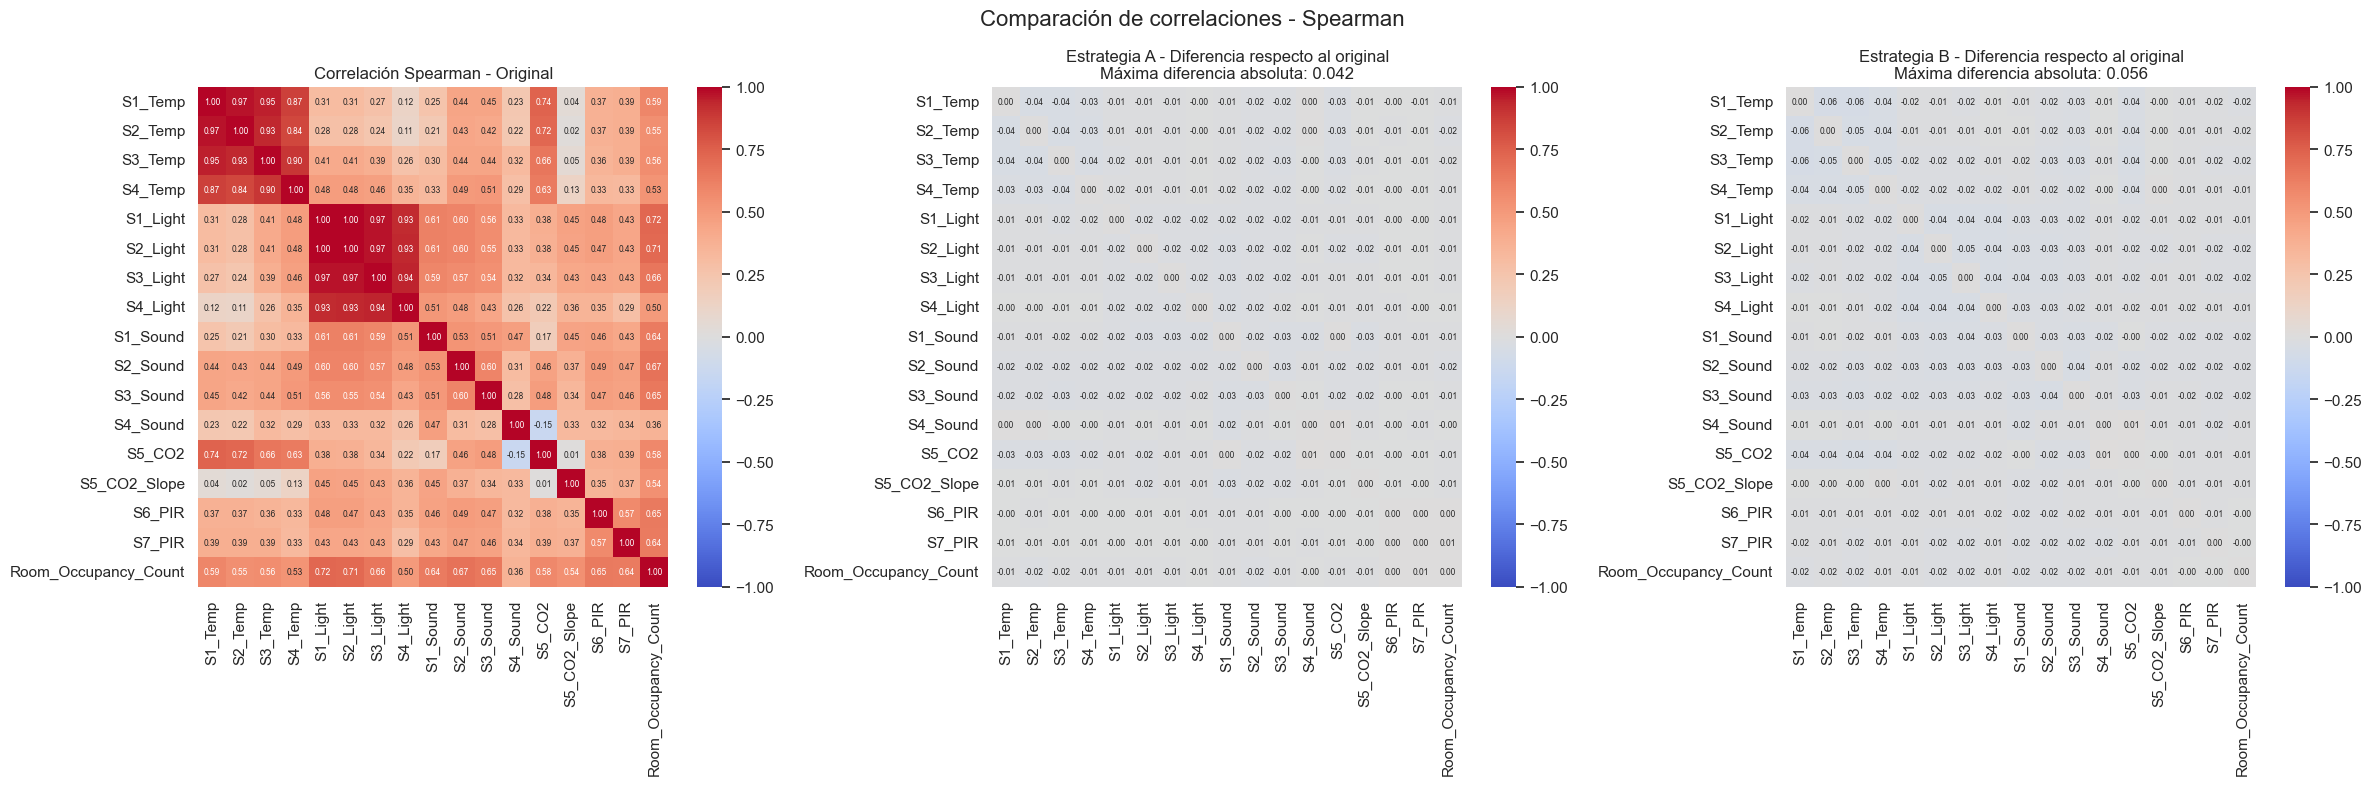


Resumen de diferencias - Spearman:


,Diferencia máxima,Diferencia media
Estrategia A,0.0421,0.0131
Estrategia B,0.0563,0.0188


In [62]:
# Sección 8.6: Correlaciones de Spearman

spearman_differences = corr_diff_heatmaps("spearman")


**Resultados e interpretación — Correlaciones de Pearson y Spearman**

El análisis de correlaciones mostró diferencias importantes entre los efectos de las estrategias de limpieza sobre las relaciones estadísticas de los sensores ambientales.

Mediante Pearson, las diferencias medias absolutas de las matrices de correlación fueron de 0.4361 para la estrategia A y 0.4354 para B. Estos valores evidencian modificaciones considerables respecto al dataset original, especialmente en las variables continuas afectadas por perturbaciones extremas.

En contraste, Spearman presentó diferencias medias de 0.0131 para A y 0.0188 para B, lo que indica una conservación considerablemente mayor de las asociaciones basadas en rangos.

Al examinar exclusivamente las correlaciones con `Room_Occupancy_Count`, las diferencias medias absolutas de Pearson fueron de 0.4941 para A y 0.4917 para B. Para Spearman, los resultados fueron aproximadamente 0.011 y 0.014, respectivamente.

Los rankings confirmaron este comportamiento. En Pearson, los sensores PIR adquirieron mayor relevancia relativa después de la limpieza, mientras que mediante Spearman se conservaron las primeras cuatro posiciones del ranking original.

**Consideración metodológica:** las matrices de diferencias utilizaron una escala fija de −1 a 1 para mantener la comparabilidad visual. Esto reduce la visibilidad de diferencias pequeñas, especialmente en Spearman.

Las correlaciones representan asociaciones estadísticas y no permiten establecer causalidad ni determinar directamente la importancia predictiva de cada variable.

**Conclusión parcial:** ambas estrategias conservan relativamente bien las asociaciones monótonas, pero presentan alteraciones importantes en las correlaciones lineales. La estrategia A muestra menores diferencias en Spearman, mientras que B presenta diferencias marginalmente menores en Pearson. Por tanto, los resultados no permiten declarar una estrategia superior en todos los criterios.


In [63]:

# Sección 8.6: Correlaciones de sensores con la ocupación

target_correlations = {}

for method in ["pearson", "spearman"]:

    correlation_df = pd.DataFrame({
        name: df[FEATURE_COLUMNS + [TARGET_COLUMN]]
        .corr(method=method)[TARGET_COLUMN]
        .drop(TARGET_COLUMN)
        for name, df in datasets.items()
    })

    # Ordenar por correlación absoluta en el dataset original
    ordered_features = (
        correlation_df[REFERENCE]
        .abs()
        .sort_values(ascending=False)
        .index
    )

    correlation_df = correlation_df.loc[ordered_features]

    target_correlations[method] = correlation_df

    print(
        f"\nCorrelaciones con Room_Occupancy_Count "
        f"mediante {method.capitalize()}:"
    )

    display(correlation_df.round(4))


# Comparar desviaciones absolutas respecto al original
correlation_summary = pd.DataFrame({
    method.capitalize(): {
        name: (
            correlations[name] - correlations[REFERENCE]
        ).abs().mean()
        for name in datasets
        if name != REFERENCE
    }
    for method, correlations in target_correlations.items()
})

print("\nDiferencias medias absolutas respecto al original:")
display(correlation_summary.round(4))



Correlaciones con Room_Occupancy_Count mediante Pearson:


,Original (sin duplicados),Estrategia A,Estrategia B
S1_Light,0.8491,0.1909,0.2021
S3_Light,0.7931,0.1624,0.1653
S2_Light,0.7888,0.3204,0.3316
S1_Temp,0.7009,0.0076,0.0006
S7_PIR,0.6951,0.7001,0.6888
S2_Temp,0.6713,0.0074,0.0105
S5_CO2,0.6601,0.0317,0.0342
S3_Temp,0.6520,-0.0166,-0.0209
S6_PIR,0.6331,0.6371,0.6326
S5_CO2_Slope,0.6011,0.0078,0.0137



Correlaciones con Room_Occupancy_Count mediante Spearman:


,Original (sin duplicados),Estrategia A,Estrategia B
S1_Light,0.7191,0.7090,0.7045
S2_Light,0.7133,0.7032,0.6967
S2_Sound,0.6745,0.6579,0.6563
S3_Light,0.6621,0.6525,0.6437
S3_Sound,0.6486,0.6344,0.6293
S6_PIR,0.6456,0.6502,0.6423
S1_Sound,0.6392,0.6261,0.6217
S7_PIR,0.6377,0.6439,0.6329
S1_Temp,0.5890,0.5752,0.5721
S5_CO2,0.5810,0.5703,0.5663



Diferencias medias absolutas respecto al original:


,Pearson,Spearman
Estrategia A,0.4941,0.011
Estrategia B,0.4917,0.014


In [64]:

# Sección 8.6: Ranking de sensores por asociación con la ocupación

top_k = 5

rankings = {}

for method, correlations in target_correlations.items():

    rankings[method] = pd.DataFrame({
        name: (
            correlations[name]
            .abs()
            .sort_values(ascending=False)
            .head(top_k)
            .index
            .tolist()
        )
        for name in datasets
    })

    rankings[method].index = [
        f"#{index + 1}"
        for index in range(top_k)
    ]

    print(
        f"\nTop {top_k} de sensores mediante "
        f"{method.capitalize()}:"
    )

    display(rankings[method])



Top 5 de sensores mediante Pearson:


,Original (sin duplicados),Estrategia A,Estrategia B
#1,S1_Light,S7_PIR,S7_PIR
#2,S3_Light,S6_PIR,S6_PIR
#3,S2_Light,S2_Light,S2_Light
#4,S1_Temp,S1_Light,S1_Light
#5,S7_PIR,S3_Light,S3_Light



Top 5 de sensores mediante Spearman:


,Original (sin duplicados),Estrategia A,Estrategia B
#1,S1_Light,S1_Light,S1_Light
#2,S2_Light,S2_Light,S2_Light
#3,S2_Sound,S2_Sound,S2_Sound
#4,S3_Light,S3_Light,S3_Light
#5,S3_Sound,S6_PIR,S6_PIR


## 8.7 Standardized multivariate profile by quality

Se realizará una comparación multivariada de los sensores ambientales utilizando las cuatro categorías de `Room_Occupancy_Count`.

Debido a que las variables presentan diferentes unidades y escalas de medición, se utilizará una estandarización basada en la media y desviación estándar del dataset original sin duplicados.

Para cada nivel de ocupación se calcularán las medias de los 16 sensores y se expresarán como desviaciones estandarizadas respecto a la referencia.

Posteriormente, se obtendrán las diferencias entre los perfiles estandarizados de las estrategias A y B y el perfil del dataset original.

Los resultados se representarán mediante mapas de calor que permitirán identificar qué sensores y categorías de ocupación presentan mayores modificaciones.

**Consideración metodológica:** la estandarización se realizará utilizando exclusivamente las estadísticas del dataset de referencia y se empleará únicamente con fines comparativos. No se modificarán los archivos limpios ni las reglas de limpieza.

Las perturbaciones extremas pueden producir diferencias estandarizadas considerablemente elevadas, especialmente en variables con poca dispersión original. Por tanto, las magnitudes deberán interpretarse junto con los resultados de los análisis univariados y de correlación.


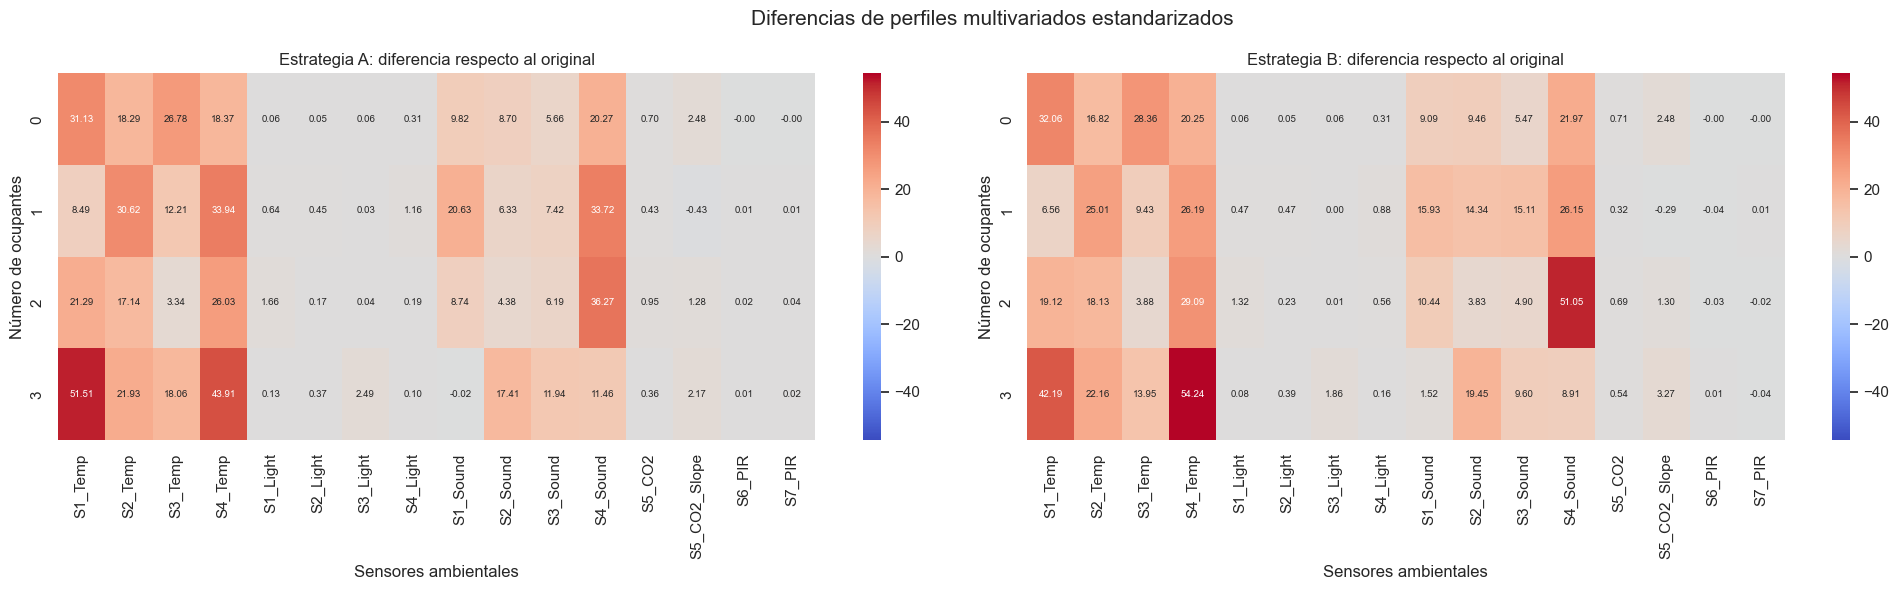

Resumen de diferencias multivariadas:


,Diferencia media absoluta,Diferencia máxima absoluta
Estrategia A,9.5132,51.5140
Estrategia B,9.5516,54.2362


In [65]:

# Sección 8.7: Perfil multivariado estandarizado por ocupación

# Dataset de referencia
reference_df = datasets[REFERENCE]

# Estadísticas de estandarización
reference_means = reference_df[FEATURE_COLUMNS].mean()
reference_stds = reference_df[FEATURE_COLUMNS].std()

# Evitar divisiones entre cero
valid_stds = reference_stds.where(
    ~np.isclose(reference_stds, 0),
    np.nan
)


def standardized_profile(df):
    """Calcula medias por ocupación usando la escala del original."""

    means_by_class = (
        df.groupby(TARGET_COLUMN)[FEATURE_COLUMNS]
        .mean()
        .reindex(occupation_classes)
    )

    return (
        means_by_class - reference_means
    ).div(valid_stds)


# Perfil de referencia
reference_profile = standardized_profile(reference_df)

# Calcular diferencias respecto al original
profile_differences = {
    name: standardized_profile(df) - reference_profile
    for name, df in datasets.items()
    if name != REFERENCE
}

# Determinar una escala simétrica compartida
max_abs_difference = max(
    difference.abs().max().max()
    for difference in profile_differences.values()
)

# Crear mapas de calor comparativos
fig, axes = plt.subplots(
    1,
    2,
    figsize=(20, 6)
)

for ax, (name, difference) in zip(
    axes,
    profile_differences.items()
):

    sns.heatmap(
        difference,
        cmap="coolwarm",
        center=0,
        vmin=-max_abs_difference,
        vmax=max_abs_difference,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        ax=ax
    )

    ax.set_title(
        f"{name}: diferencia respecto al original"
    )

    ax.set_xlabel("Sensores ambientales")
    ax.set_ylabel("Número de ocupantes")

plt.suptitle(
    "Diferencias de perfiles multivariados estandarizados",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Resumen cuantitativo
profile_summary = pd.DataFrame({
    name: {
        "Diferencia media absoluta": (
            difference.abs().to_numpy().mean()
        ),
        "Diferencia máxima absoluta": (
            difference.abs().max().max()
        )
    }
    for name, difference in profile_differences.items()
}).T

print("Resumen de diferencias multivariadas:")
display(profile_summary.round(4))



**Resultados e interpretación — Perfil multivariado estandarizado**

El análisis multivariado permitió comparar las medias de los sensores ambientales por nivel de ocupación, utilizando como referencia las medias y desviaciones estándar del dataset original sin duplicados.

La estrategia A presentó una diferencia media absoluta de 9.5132 unidades estandarizadas y una diferencia máxima de 51.5140. Por su parte, la estrategia B registró una diferencia media absoluta de 9.5516 y una diferencia máxima de 54.2362.

Los mapas de calor mostraron que las mayores desviaciones se concentran principalmente en los sensores de temperatura y sonido. En contraste, los sensores PIR conservaron perfiles próximos a los originales, con diferencias estandarizadas cercanas a cero.

Las desviaciones elevadas en las variables continuas son consistentes con las perturbaciones extremas identificadas previamente, que modifican las medias de los sensores incluso cuando las medianas y los rangos intercuartílicos permanecen relativamente estables.

La estrategia A presentó diferencias ligeramente menores en los indicadores agregados. Sin embargo, la magnitud de las desviaciones frente al dataset original es considerable en ambas estrategias, por lo que esta ventaja no constituye evidencia suficiente para establecer una superioridad general.

**Limitación metodológica:** las diferencias se expresan en unidades de desviación estándar del dataset original y no representan porcentajes de error. Además, las variables con dispersión original reducida pueden producir diferencias estandarizadas particularmente elevadas cuando existen mediciones extremas.

**Conclusión parcial:** ninguna de las dos estrategias logró preservar completamente los perfiles multivariados originales. La estrategia A presentó una desviación agregada ligeramente menor, mientras que la estrategia B conservó una cantidad considerablemente mayor de registros. La selección final deberá considerar conjuntamente estos resultados, las correlaciones, las distribuciones y la conservación de observaciones.


## 8.8 Formal distribution tests

Para complementar el análisis exploratorio, se evaluarán cuantitativamente las diferencias entre las distribuciones de los sensores continuos del dataset original y las obtenidas mediante las estrategias A y B.

Se utilizarán tres indicadores:

| Indicador | Descripción | Interpretación |
|---|---|---|
| Kolmogorov-Smirnov (KS) | Mide la diferencia máxima entre las funciones de distribución acumulada | Valores cercanos a cero indican distribuciones más próximas |
| Diferencia de medias estandarizada (SMD) | Expresa la diferencia de medias respecto a la desviación estándar del original | Valores absolutos menores indican mayor proximidad de las medias |
| Razón de varianzas | Compara la varianza de cada estrategia con la varianza original | Valores próximos a 1 indican dispersión similar |

Las métricas se calcularán para las 14 variables continuas de `Room Occupancy Estimation`. Los sensores PIR se excluyen porque son variables binarias y requieren una interpretación basada en proporciones, ya examinada en los análisis anteriores.

Para complementar el estadístico KS se mostrarán sus valores p. Sin embargo, estos no se utilizarán para demostrar equivalencia estadística, ya que los datasets comparados comparten observaciones y no constituyen muestras independientes.

**Consideración metodológica:** las métricas de medias y varianzas son sensibles a valores extremos. Por ello, una discrepancia elevada podrá reflejar perturbaciones numéricas que permanecieron sin detectar durante la limpieza.

Los resultados se utilizarán para comparar ambas estrategias respecto al dataset original, sin modificar retrospectivamente las reglas de procesamiento.


In [66]:

# Sección 8.8: Pruebas estadísticas de distribución

def distribution_tests(name, ref_name=REFERENCE):
    """Compara distribuciones continuas contra la referencia."""

    reference_df = datasets[ref_name]
    strategy_df = datasets[name]

    results = []

    for column in continuous_columns:

        reference_values = reference_df[column].dropna()
        strategy_values = strategy_df[column].dropna()

        # Kolmogorov-Smirnov
        ks_result = stats.ks_2samp(
            reference_values,
            strategy_values
        )

        # Estadísticas de referencia
        reference_mean = reference_values.mean()
        reference_std = reference_values.std()
        reference_var = reference_values.var()

        # Estadísticas de la estrategia
        strategy_mean = strategy_values.mean()
        strategy_var = strategy_values.var()

        # Diferencia de medias estandarizada
        smd = (
            (strategy_mean - reference_mean) / reference_std
            if not np.isclose(reference_std, 0)
            else np.nan
        )

        # Razón de varianzas
        variance_ratio = (
            strategy_var / reference_var
            if not np.isclose(reference_var, 0)
            else np.nan
        )

        results.append({
            "Variable": column,
            "KS": ks_result.statistic,
            "Valor p KS": ks_result.pvalue,
            "SMD": smd,
            "Razón de varianzas": variance_ratio
        })

    return pd.DataFrame(results).set_index("Variable")


# Evaluar la estrategia A
tests_a = distribution_tests("Estrategia A")

print("Pruebas de distribución — Estrategia A")

display(
    tests_a.style.format({
        "KS": "{:.4f}",
        "Valor p KS": "{:.4g}",
        "SMD": "{:.4f}",
        "Razón de varianzas": "{:.4f}"
    })
)

assert len(tests_a) == len(continuous_columns)

print(
    f"\nVariables continuas evaluadas: {len(tests_a)}"
)


Pruebas de distribución — Estrategia A


,KS,Valor p KS,SMD,Razón de varianzas
Variable,,,,
S1_Temp,0.0105,0.7154,30.7736,129775.0945
S2_Temp,0.0111,0.6477,18.9954,47094.5243
S3_Temp,0.0109,0.675,23.7939,78684.8490
S4_Temp,0.0088,0.8805,21.3645,77044.5562
S1_Light,0.0066,0.99,0.2050,32.9889
S2_Light,0.0059,0.9981,0.0958,7.5384
S3_Light,0.0049,0.9999,0.2247,60.9782
S4_Light,0.0080,0.9426,0.3213,26.6210
S1_Sound,0.0134,0.4133,9.5492,19378.2599



Variables continuas evaluadas: 14


In [67]:

# Sección 8.8: Pruebas de distribución para la estrategia B

tests_b = distribution_tests("Estrategia B")

print("Pruebas de distribución — Estrategia B")

display(
    tests_b.style.format({
        "KS": "{:.4f}",
        "Valor p KS": "{:.4g}",
        "SMD": "{:.4f}",
        "Razón de varianzas": "{:.4f}"
    })
)

assert len(tests_b) == len(continuous_columns)

print(
    f"\nVariables continuas evaluadas: {len(tests_b)}"
)


Pruebas de distribución — Estrategia B


,KS,Valor p KS,SMD,Razón de varianzas
Variable,,,,
S1_Temp,0.0131,0.3527,30.6413,124798.2000
S2_Temp,0.0133,0.3366,17.6499,42365.7946
S3_Temp,0.0138,0.2969,24.6937,84125.6689
S4_Temp,0.0130,0.3619,23.5082,93164.4182
S1_Light,0.0067,0.9768,0.1772,26.2689
S2_Light,0.0065,0.984,0.1059,7.2998
S3_Light,0.0058,0.9955,0.1771,48.0513
S4_Light,0.0081,0.8933,0.3418,31.9157
S1_Sound,0.0118,0.4865,8.9821,17911.8733



Variables continuas evaluadas: 14


In [68]:

# Sección 8.8: Resumen comparativo de ambas estrategias

def correlation_gap(name, ref_name=REFERENCE):
    """Calcula diferencias absolutas de correlación de Pearson."""

    reference_corr = datasets[ref_name][corr_cols].corr()
    strategy_corr = datasets[name][corr_cols].corr()

    difference = (strategy_corr - reference_corr).abs()

    return difference.max().max()


# Consolidar resultados de las pruebas de distribución
scorecard_rows = []

for name, tests in [
    ("Estrategia A", tests_a),
    ("Estrategia B", tests_b)
]:

    scorecard_rows.append({
        "Estrategia": name,
        "Registros": len(datasets[name]),
        "Variables evaluadas": len(tests),
        "KS máximo": tests["KS"].max(),
        "KS promedio": tests["KS"].mean(),
        "SMD máximo absoluto": tests["SMD"].abs().max(),
        "Razón mínima de varianzas":
            tests["Razón de varianzas"].min(),
        "Razón máxima de varianzas":
            tests["Razón de varianzas"].max(),
        "Diferencia máxima de correlación":
            correlation_gap(name)
    })


scorecard = pd.DataFrame(
    scorecard_rows
).set_index("Estrategia")

print("Resumen comparativo de las estrategias:")

display(
    scorecard.style.format({
        "Registros": "{:,.0f}",
        "Variables evaluadas": "{:.0f}",
        "KS máximo": "{:.4f}",
        "KS promedio": "{:.4f}",
        "SMD máximo absoluto": "{:.4f}",
        "Razón mínima de varianzas": "{:.4f}",
        "Razón máxima de varianzas": "{:.4f}",
        "Diferencia máxima de correlación": "{:.4f}"
    })
)

assert (scorecard["Variables evaluadas"] == 14).all()

print("\nScorecard calculado correctamente.")


Resumen comparativo de las estrategias:


,Registros,Variables evaluadas,KS máximo,KS promedio,SMD máximo absoluto,Razón mínima de varianzas,Razón máxima de varianzas,Diferencia máxima de correlación
Estrategia,,,,,,,,
Estrategia A,"7,684",14,0.0134,0.0091,30.7736,7.5384,129775.0945,0.9561
Estrategia B,"9,817",14,0.0138,0.0101,30.6413,7.2998,140096.8530,0.9562



Scorecard calculado correctamente.


**Resultados e interpretación — Pruebas estadísticas de distribución**

Las pruebas estadísticas permitieron evaluar las diferencias entre las distribuciones del dataset original y las obtenidas mediante las estrategias de eliminación e imputación.

La estrategia A presentó un estadístico KS promedio de 0.0091, mientras que la estrategia B obtuvo 0.0101. Estos resultados indican diferencias relativamente pequeñas entre las funciones de distribución acumulada, con una ligera ventaja para la estrategia A.

Sin embargo, las diferencias de medias estandarizadas y las razones de varianzas mostraron alteraciones importantes. El SMD máximo absoluto alcanzó 30.7736 en A y 30.6413 en B. Asimismo, las razones máximas de varianzas fueron de 129,775.0945 y 140,096.8530, respectivamente.

Estos resultados evidencian que una proporción reducida de observaciones extremas puede modificar considerablemente las medias y la dispersión, incluso cuando las diferencias entre las funciones de distribución acumulada son pequeñas.

En cuanto a las correlaciones lineales, las diferencias máximas absolutas respecto al dataset original fueron de 0.9561 para A y 0.9562 para B, lo que confirma modificaciones importantes en determinadas relaciones estadísticas.

**Limitaciones:** los estadísticos KS se utilizaron principalmente como medidas descriptivas, debido a que los datasets comparados comparten observaciones. Los valores p no permiten demostrar equivalencia estadística. Además, las diferencias extremas observadas en medias y varianzas están relacionadas con perturbaciones numéricas que permanecieron sin detectar por las reglas de dominio.

**Conclusión parcial:** la estrategia A presentó una menor discrepancia promedio en KS y una diferencia máxima de correlación ligeramente inferior, mientras que la estrategia B conservó más registros y obtuvo un SMD máximo marginalmente menor. No obstante, ninguna estrategia preservó satisfactoriamente todas las propiedades estadísticas del dataset original. La elección final deberá considerar conjuntamente la conservación de observaciones, las distribuciones, las correlaciones y las limitaciones del proceso de limpieza.

# 9. Conclusions

### 9.1. Hallazgos del diagnóstico y acciones correctivas

El proceso de diagnóstico permitió identificar anomalías estructurales, problemas de formato, valores faltantes, registros duplicados y mediciones inconsistentes en el dataset perturbado Room Occupancy Estimation.

Las diez pruebas diagnósticas proporcionaron evidencia para establecer las acciones correctivas aplicadas durante la limpieza.

| Prueba | Hallazgo | Acción correctiva |
|---|---|---|
| T1. Esquema | Columna adicional `mixed_type_col` | Eliminar la columna ajena al contrato |
| T2. Tipos de datos | Valores numéricos almacenados como texto | Conversión explícita a tipos numéricos |
| T3. Espacios | 9,766 celdas con espacios exteriores | Normalización mediante `str.strip()` |
| T4. Tokens inválidos | 953 celdas con tokens no numéricos | Normalización de marcadores reconocidos a valores faltantes |
| T5. Valores faltantes | Celdas vacías y marcadores inválidos | Evaluar eliminación o imputación |
| T6. Rangos de dominio | 144 celdas fuera de los límites configurados | Invalidar valores que incumplen el contrato |
| T7. Consistencia | Validación del dominio binario de sensores PIR | Invalidar lecturas distintas de 0 y 1 |
| T8. Variable objetivo | 215 etiquetas inválidas | Eliminar registros con ocupación inválida |
| T9. Duplicados | Registros duplicados después de normalizar | Eliminar duplicados exactos |
| T10. Integridad temporal | Marcas temporales inválidas y anomalías cronológicas | Eliminar registros con fechas u horas inválidas y documentar las discontinuidades |

Las transformaciones se implementaron mediante funciones independientes, aplicadas en un orden explícito y acompañadas de un registro de ejecución que permite conocer las modificaciones efectuadas.

### 9.2. Comparación de las estrategias de limpieza

Se evaluaron dos procedimientos para resolver los valores faltantes restantes después de las validaciones comunes.

La **estrategia A**, basada en la eliminación de registros incompletos, produjo un dataset de 7,684 observaciones, equivalente al 75.86% del dataset original.

La **estrategia B**, basada en la imputación por mediana para sensores continuos y moda para sensores PIR, conservó 9,817 observaciones, correspondientes al 96.92% del original.

Ambas estrategias conservaron las 19 columnas esperadas y finalizaron sin valores faltantes ni registros completamente duplicados. Las validaciones automáticas confirmaron el cumplimiento del contrato de datos implementado.

La distribución de `Room_Occupancy_Count` permaneció relativamente estable. En los tres datasets predominó la clase 0, con aproximadamente el 81% de las observaciones.

### 9.3. Conservación de propiedades estadísticas

El análisis exploratorio comparativo mostró diferencias relevantes entre la conservación de las distribuciones centrales y la preservación de las propiedades estadísticas completas.

Las medianas y los rangos intercuartílicos de numerosos sensores permanecieron relativamente próximos a los del dataset original. Sin embargo, las medias y desviaciones estándar presentaron alteraciones pronunciadas.

Por ejemplo, la media de `S1_Temp` aumentó aproximadamente un 42% en ambas estrategias. También se observaron incrementos considerables en las variables de sonido.

Las pruebas formales de distribución produjeron estadísticos KS promedio de 0.0091 para la estrategia A y 0.0101 para B. Aunque estos valores indican diferencias reducidas entre las funciones de distribución acumulada, las razones de varianzas y las diferencias de medias estandarizadas mostraron alteraciones importantes.

Las correlaciones de Pearson también presentaron desviaciones considerables, con diferencias medias absolutas de 0.4361 y 0.4354 para A y B, respectivamente.

En contraste, las correlaciones de Spearman mostraron una mayor estabilidad, con diferencias medias absolutas de 0.0131 para A y 0.0188 para B.

El análisis multivariado estandarizado confirmó que las mayores desviaciones se concentraron principalmente en sensores de temperatura y sonido, mientras que las variables binarias PIR conservaron un comportamiento más próximo a la referencia.

### 9.4. Auditoría contra el dataset original

La comparación bajo la hipótesis de correspondencia posicional identificó 4,173 celdas diferentes entre el dataset original y el perturbado.

Las reglas de validación detectaron 2,899 diferencias, mientras que 1,274 permanecieron sin identificar. La precisión observada fue del 100% y el recall del 69.47%, considerando exclusivamente las alteraciones sintéticas evaluadas.

Los falsos negativos se concentraron en variables continuas que contenían valores numéricos extremos sin incumplir las restricciones configuradas.

Esto demuestra que superar las validaciones estructurales y de dominio no garantiza recuperar completamente las propiedades estadísticas del dataset original.

El archivo original se utilizó exclusivamente con fines de evaluación, sin modificar retrospectivamente las reglas de limpieza.

### 9.5. Selección de estrategia y limitaciones

La estrategia A presentó menores diferencias en los indicadores KS y en las correlaciones de Spearman. Por su parte, la estrategia B conservó 2,133 registros adicionales y mostró una diferencia media de Pearson marginalmente menor.

No obstante, ninguna estrategia fue superior en todos los criterios y ambas conservaron alteraciones extremas capaces de modificar considerablemente las medias, varianzas y correlaciones lineales.

Para un escenario donde la conservación de observaciones sea prioritaria, la estrategia B representa una alternativa favorable, siempre que se reconozca el efecto de la imputación sobre los datos.

Cuando se busque evitar la introducción de valores estimados, la estrategia A constituye una alternativa, aunque implica una pérdida mayor de registros y no corrige por sí misma las perturbaciones extremas.

Por tanto, la selección definitiva dependerá del objetivo analítico y de los criterios de calidad establecidos para el sistema.

### 9.6. Aprendizajes desde la perspectiva de MLOps

La actividad permitió comprobar la importancia de establecer un contrato de datos antes de aplicar transformaciones de limpieza.

La validación previa permitió distinguir problemas de esquema, formato, valores faltantes, restricciones de dominio e inconsistencias, evitando aplicar tratamientos generales sin considerar la naturaleza de cada anomalía.

La implementación mediante funciones independientes y un registro de transformaciones favorece la reproducibilidad, la trazabilidad y la posibilidad de incorporar validaciones automáticas en un pipeline de MLOps.

También se identificó la importancia de distinguir entre valores estadísticamente atípicos y errores confirmados, así como la necesidad de aplicar procedimientos de imputación utilizando exclusivamente los datos de entrenamiento en un escenario de modelado predictivo.

Como limitación principal, el contrato implementado no incluyó límites operativos superiores para determinadas variables continuas. Esto permitió que algunas perturbaciones extremas permanecieran en ambos datasets limpios.

En consecuencia, el proceso evidencia que la calidad de los datos no debe evaluarse únicamente mediante la ausencia de valores faltantes, duplicados o errores de formato. También es necesario comprobar la preservación de las distribuciones, la coherencia de las mediciones y las relaciones estadísticas entre variables.

**Conclusión general:** ambas estrategias permitieron obtener datasets estructuralmente válidos y reproducibles, pero conservaron alteraciones estadísticas importantes. La estrategia A mostró ventajas en algunos indicadores de similitud, mientras que B permitió conservar una mayor proporción de observaciones. La actividad demuestra la necesidad de combinar validaciones automatizadas, reglas de dominio documentadas y evaluaciones estadísticas para construir procesos de preparación de datos confiables en MLOps.
